# Setup

In [1]:
# Import libraries
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import earthkit.data
import regionmask
import cdsapi

print("All libraries imported successfully!")

c:\Users\Adam\miniforge3\envs\era5-analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


In [9]:
## API key
client = cdsapi.Client(
    quiet=False,
    progress=True,
    retry_max=5,
    sleep_max=120,
)

2026-11-16 17:31:25,548 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


In [10]:

import os
import sys
import importlib
import tempfile
from pathlib import Path

# ============================================================
# 1. CDS API credentials
# ============================================================

# Assumes CDS_URL and CDS_API_KEY have already been defined.
#os.environ["CDSAPI_URL"] = CDS_URL
#os.environ["CDSAPI_KEY"] = CDS_API_KEY

print("=" * 55)
print("ERA5 ENVIRONMENT TEST")
print("=" * 55)

# ============================================================
# 2. Check Python version
# ============================================================

print(f"\nPython version: {sys.version.split()[0]}")
print(f"Python executable: {sys.executable}")

# ============================================================
# 3. Test installed packages
# ============================================================

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "xarray": "xarray",
    "netCDF4": "netCDF4",
    "cfgrib": "cfgrib",
    "eccodes": "eccodes",
    "dask": "dask",
    "scipy": "scipy",
    "matplotlib": "matplotlib",
    "cartopy": "cartopy",
    "sklearn": "scikit-learn",
    "cdsapi": "cdsapi",
    "earthkit.data": "earthkit-data",
    "regionmask": "regionmask",
    "xeofs": "xeofs",
}

failed = []

print("\nChecking installed packages:\n")

for module, package in packages.items():
    try:
        importlib.import_module(module)
        print(f"  [OK] {package}")
    except Exception as e:
        print(f"  [FAIL] {package}: {e}")
        failed.append(package)

# ============================================================
# 4. Check CDS API configuration
# ============================================================

print("\nChecking CDS API configuration:\n")

url = os.environ.get("CDSAPI_URL")
key = os.environ.get("CDSAPI_KEY")

if url and key:
    print(f"  [OK] CDS API URL: {url}")
    print("  [OK] CDS API key is configured (hidden)")
else:
    print("  [FAIL] CDS API credentials missing")

# ============================================================
# 5. Test Xarray and NumPy
# ============================================================

print("\nTesting Xarray and NumPy:\n")

try:
    import numpy as np
    import xarray as xr

    data = xr.DataArray(
        np.random.default_rng(42).random((10, 20)),
        dims=["latitude", "longitude"],
        coords={
            "latitude": np.linspace(50, 60, 10),
            "longitude": np.linspace(-10, 10, 20),
        },
        name="temperature",
    )

    print(f"  [OK] Created DataArray: {data.shape}")
    print(f"  [OK] Mean value: {data.mean().item():.4f}")

except Exception as e:
    print(f"  [FAIL] Xarray test: {e}")
    failed.append("xarray computation")

# ============================================================
# 6. Test NetCDF writing and reading
# ============================================================

print("\nTesting NetCDF:\n")

try:
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "test.nc"

        data.to_netcdf(path, engine="netcdf4")

        with xr.open_dataarray(path, engine="netcdf4") as loaded:
            np.testing.assert_allclose(
                loaded.values, data.values
            )

    print("  [OK] NetCDF write/read successful")

except Exception as e:
    print(f"  [FAIL] NetCDF test: {e}")
    failed.append("NetCDF read/write")

# ============================================================
# 7. Test CDS API client initialization
# ============================================================

print("\nTesting CDS API client:\n")

try:
    import cdsapi

    client = client

    print("  [OK] CDS API client initialized")
    print("  [INFO] No download attempted yet")

except Exception as e:
    print(f"  [FAIL] CDS API client: {e}")
    failed.append("CDS API client")

# ============================================================
# 8. Summary
# ============================================================

print("\n" + "=" * 55)

if not failed:
    print("SUCCESS: All local environment tests passed!")
else:
    print(f"WARNING: {len(failed)} test(s) failed")
    print("Failed:", ", ".join(failed))

print("=" * 55)


ERA5 ENVIRONMENT TEST

Python version: 3.12.16
Python executable: c:\Users\Adam\miniforge3\envs\era5-analysis\python.exe

Checking installed packages:

  [OK] numpy
  [OK] pandas
  [OK] xarray
  [OK] netCDF4
  [OK] cfgrib
  [OK] eccodes
  [OK] dask
  [OK] scipy
  [OK] matplotlib
  [OK] cartopy
  [OK] scikit-learn
  [OK] cdsapi
  [OK] earthkit-data
  [OK] regionmask
  [OK] xeofs

Checking CDS API configuration:

  [FAIL] CDS API credentials missing

Testing Xarray and NumPy:

  [OK] Created DataArray: (10, 20)
  [OK] Mean value: 0.4939

Testing NetCDF:

  [OK] NetCDF write/read successful

Testing CDS API client:

  [OK] CDS API client initialized
  [INFO] No download attempted yet

SUCCESS: All local environment tests passed!


ERA5 END-TO-END ENVIRONMENT TEST

[2/6] Downloading ERA5 data...
[OK] Existing ERA5 file found
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5_uk_temperature.nc
Size: 28.50 KB

[3/6] Opening ERA5 NetCDF dataset...

Dataset:
<xarray.Dataset> Size: 10kB
Dimensions:     (valid_time: 1, latitude: 41, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2024-01-01T12:00:00
  * latitude    (latitude) float64 328B 59.0 58.75 58.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 9kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:       

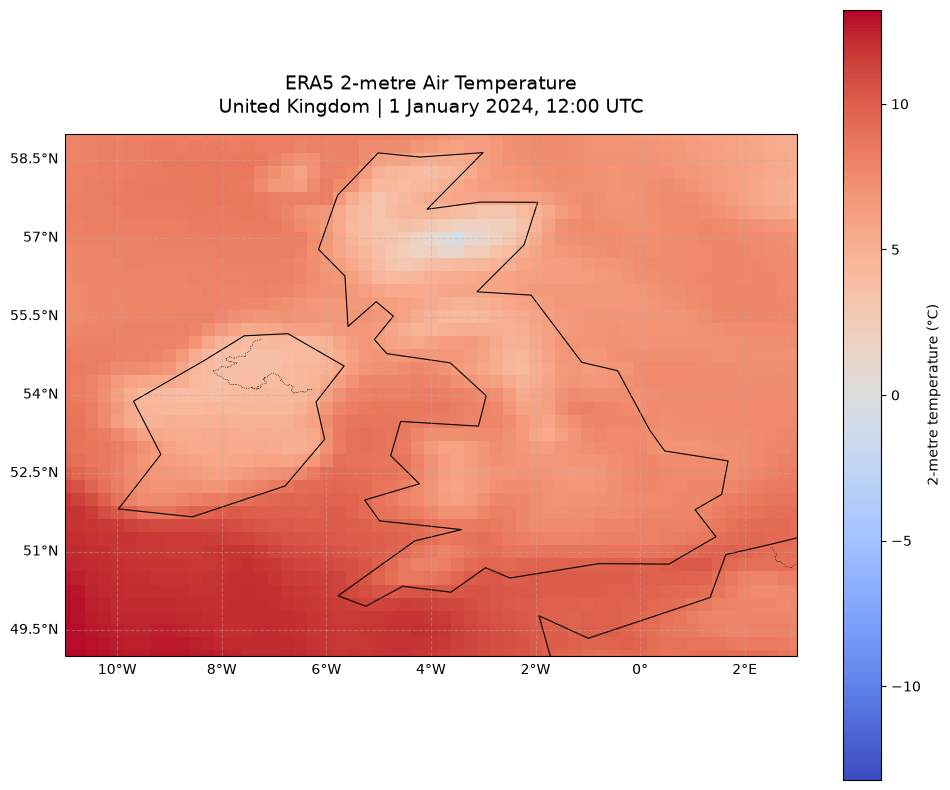

[OK] Map saved: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5_uk_temperature.png

[6/6] Running final checks...

ERA5 END-TO-END TEST RESULTS
[FAIL] CDS API credentials configured
[PASS] ERA5 NetCDF file exists
[PASS] ERA5 NetCDF file is non-empty
[PASS] Temperature variable available
[PASS] Temperature converted to Celsius
[PASS] Temperature values are finite
[PASS] Temperature statistics calculated
[PASS] Temperature map saved


In [11]:
import os
from pathlib import Path

import cdsapi
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ============================================================
# ERA5 END-TO-END ENVIRONMENT TEST
# ============================================================

print("=" * 60)
print("ERA5 END-TO-END ENVIRONMENT TEST")
print("=" * 60)

# ============================================================
# 1. CDS API CREDENTIALS
# ============================================================

# Assumes CDS_URL and CDS_API_KEY are already defined.
# Do not print or commit your API key.

#os.environ["CDSAPI_URL"] = CDS_URL
#os.environ["CDSAPI_KEY"] = CDS_API_KEY

#print("\n[1/6] Checking CDS API credentials...")

#assert os.environ.get("CDSAPI_URL"), "Missing CDS API URL"
#assert os.environ.get("CDSAPI_KEY"), "Missing CDS API key"

#print("[OK] CDS API credentials configured")

# ============================================================
# 2. DOWNLOAD ERA5 DATA
# ============================================================

print("\n[2/6] Downloading ERA5 data...")

data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

output_file = data_dir / "uk" / "era5_uk_temperature.nc"

if not output_file.exists():

    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": ["reanalysis"],
            "variable": ["2m_temperature"],
            "year": ["2024"],
            "month": ["01"],
            "day": ["01"],
            "time": ["12:00"],
            "data_format": "netcdf",
            "download_format": "unarchived",
            "area": [59, -11, 49, 3],
        },
        str(output_file.resolve()),
    )

    print("[OK] ERA5 download complete")

else:
    print("[OK] Existing ERA5 file found")

print(f"File: {output_file.resolve()}")
print(f"Size: {output_file.stat().st_size / 1024:.2f} KB")

# ============================================================
# 3. OPEN AND INSPECT DATASET
# ============================================================

print("\n[3/6] Opening ERA5 NetCDF dataset...")

ds = xr.open_dataset(output_file)

print("\nDataset:")
print(ds)

print("\nVariables:", list(ds.data_vars))
print("Dimensions:", dict(ds.sizes))
print("Coordinates:", list(ds.coords))

assert "t2m" in ds.data_vars, "Temperature variable t2m missing"

print("\n[OK] NetCDF dataset opened successfully")

# ============================================================
# 4. TEMPERATURE ANALYSIS
# ============================================================

print("\n[4/6] Analysing ERA5 temperature...")

# Convert Kelvin to Celsius
temperature_c = (ds["t2m"] - 273.15).squeeze()

temperature_c.attrs["units"] = "degC"
temperature_c.attrs["long_name"] = "2-metre air temperature"

# Calculate statistics
t_min = temperature_c.min().item()
t_max = temperature_c.max().item()
t_mean = temperature_c.mean().item()
t_std = temperature_c.std().item()

print("\nTemperature statistics:")
print("-" * 40)
print(f"Minimum:            {t_min:.2f} °C")
print(f"Maximum:            {t_max:.2f} °C")
print(f"Mean:               {t_mean:.2f} °C")
print(f"Standard deviation: {t_std:.2f} °C")

assert np.isfinite(temperature_c.values).all(), (
    "Temperature contains NaN or infinite values"
)

print("\n[OK] Temperature calculations successful")

# ============================================================
# 5. VISUALISE TEMPERATURE WITH CARTOPY
# ============================================================

print("\n[5/6] Generating ERA5 temperature map...")

fig_dir = Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)

fig = plt.figure(figsize=(10, 8))

ax = plt.axes(
    projection=ccrs.PlateCarree()
)

# Plot temperature field
temperature_c.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    cbar_kwargs={
        "label": "2-metre temperature (°C)"
    }
)

# Geographic features
ax.coastlines(
    resolution="110m",
    linewidth=0.8
)

ax.add_feature(
    cfeature.BORDERS,
    linestyle=":",
    linewidth=0.5
)

# Map extent
ax.set_extent(
    [-11, 3, 49, 59],
    crs=ccrs.PlateCarree()
)

# Gridlines
ax.gridlines(
    draw_labels={"bottom": "x", "left": "y"},
    linestyle="--",
    alpha=0.4
)

# Title
ax.set_title(
    "ERA5 2-metre Air Temperature\n"
    "United Kingdom | 1 January 2024, 12:00 UTC",
    fontsize=14,
    pad=15
)

plt.tight_layout()

# Save figure
figure_file = fig_dir / "era5_uk_temperature.png"

plt.savefig(
    figure_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"[OK] Map saved: {figure_file.resolve()}")

# ============================================================
# 6. FINAL VERIFICATION
# ============================================================

print("\n[6/6] Running final checks...")

checks = {
    "CDS API credentials configured":
        bool(os.environ.get("CDSAPI_URL")) and
        bool(os.environ.get("CDSAPI_KEY")),

    "ERA5 NetCDF file exists":
        output_file.exists(),

    "ERA5 NetCDF file is non-empty":
        output_file.stat().st_size > 0,

    "Temperature variable available":
        "t2m" in ds.data_vars,

    "Temperature converted to Celsius":
        temperature_c.attrs.get("units") == "degC",

    "Temperature values are finite":
        bool(np.isfinite(temperature_c.values).all()),

    "Temperature statistics calculated":
        bool(np.isfinite([t_min, t_max, t_mean, t_std]).all()),

    "Temperature map saved":
        figure_file.exists(),
}

print("\n" + "=" * 60)
print("ERA5 END-TO-END TEST RESULTS")
print("=" * 60)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 60)

if all(checks.values()):
    print("SUCCESS: ERA5 END-TO-END WORKFLOW IS OPERATIONAL!")
else:
    print("WARNING: Some tests failed.")

print("=" * 60)

# Close dataset
ds.close()

NOAA ERSSTv5 - EL NINO ANALYSIS

[1/8] Using existing NOAA dataset
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\noaa\sst.mnmean.nc
Size: 154.85 MB

[2/8] Loading tropical Pacific SST...

Original dataset dimensions:
{'time': 2074, 'nbnds': 2, 'lat': 89, 'lon': 180}

Original latitude range:
88.0 to -88.0

Original longitude range:
0.0 to 358.0

Selected SST dimensions:
{'time': 240, 'lat': 21, 'lon': 81}

[OK] Pacific SST selected successfully
Minimum SST: 15.83 °C
Maximum SST: 31.96 °C

[3/8] Calculating SST climatology and anomalies...
[OK] Monthly climatology calculated
[OK] Monthly anomalies calculated
[OK] 20-year mean SST calculated

[4/8] Plotting mean Pacific SST...


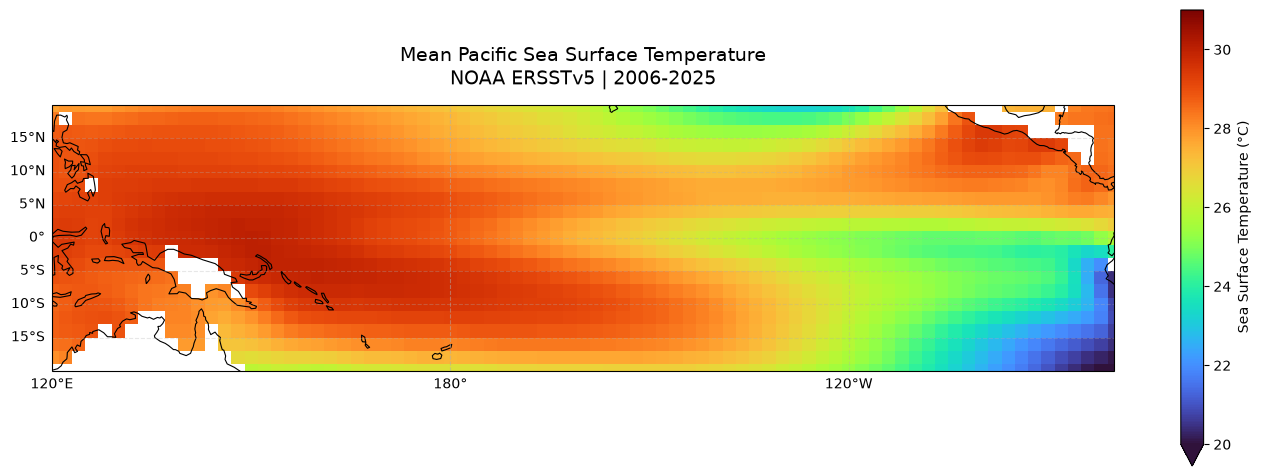

[OK] Mean SST map saved

[5/8] Calculating Niño 3.4 index...
[OK] Niño 3.4 index calculated
Maximum anomaly: 2.78 °C
Minimum anomaly: -1.58 °C

[6/8] Plotting Niño 3.4 anomalies...


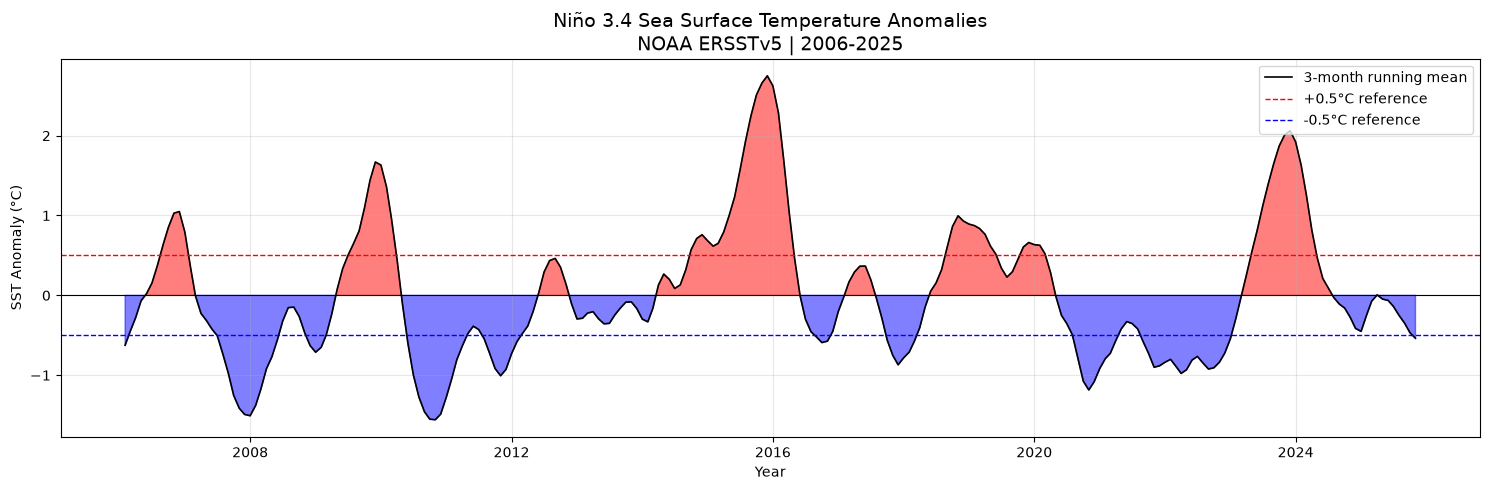

[OK] Niño 3.4 time series saved

[7/8] Plotting Pacific Hovmöller diagram...


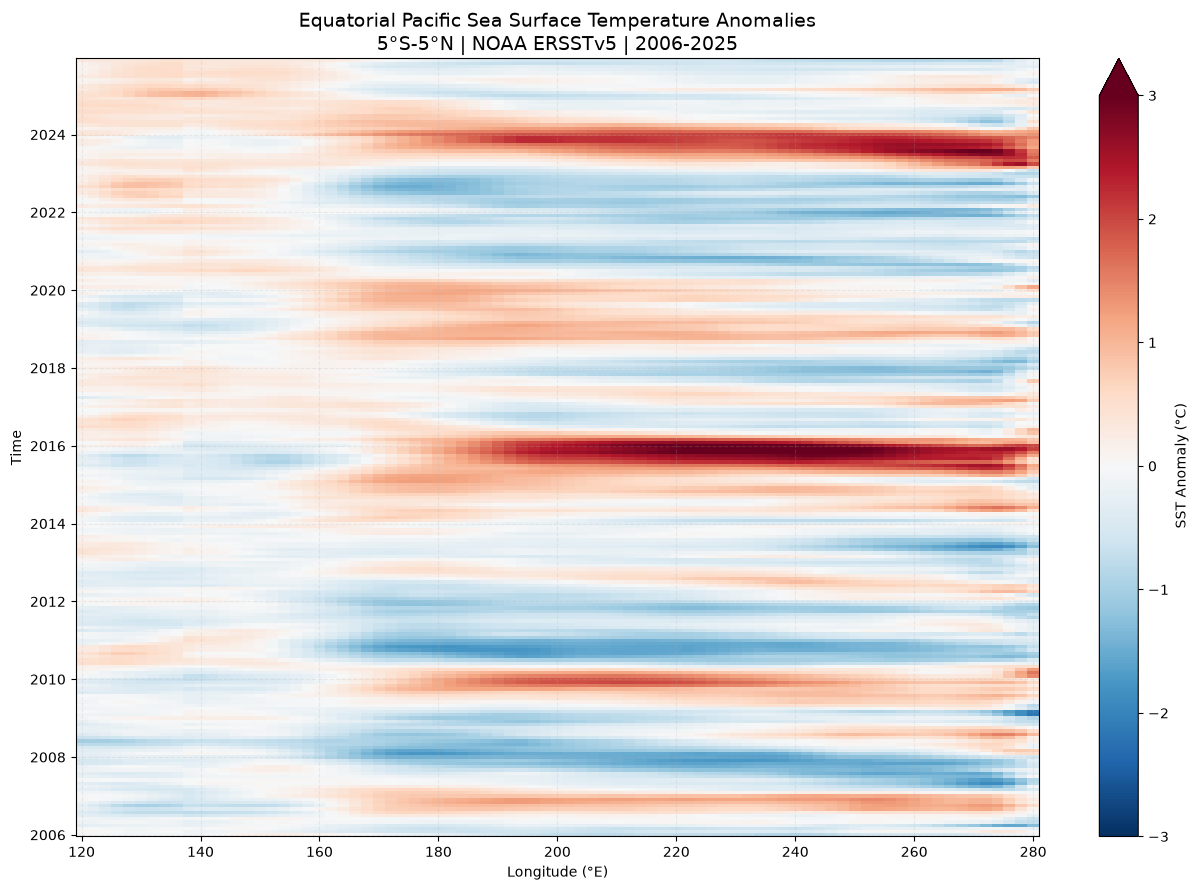

[OK] Hovmöller diagram saved

[8/8] Saving Niño 3.4 index...

NOAA ERSSTv5 ANALYSIS RESULTS
[PASS] NOAA dataset downloaded
[PASS] 240 months selected
[PASS] Latitude selection valid
[PASS] Longitude selection valid
[PASS] Mean SST calculated
[PASS] Niño 3.4 index calculated
[PASS] Mean SST map saved
[PASS] Niño 3.4 plot saved
[PASS] Hovmöller diagram saved
[PASS] CSV saved
[PASS] NetCDF anomalies saved
SUCCESS: ALL TESTS PASSED!

Months analysed: 240
Latitude points: 21
Longitude points: 81

Output directory:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures

Data directory:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\noaa


In [7]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
import urllib.request

# ============================================================
# NOAA ERSSTv5 - EL NINO ANALYSIS
# Monthly Pacific Sea Surface Temperature: 2006-2025
# ============================================================

START_YEAR = 2006
END_YEAR = 2025

DATA_DIR = Path("data/noaa")
FIG_DIR = Path("figures")

DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

url = (
    "https://downloads.psl.noaa.gov/Datasets/"
    "noaa.ersst.v5/sst.mnmean.nc"
)

file_path = DATA_DIR / "sst.mnmean.nc"

# ============================================================
# 1. DOWNLOAD NOAA DATA
# ============================================================

print("=" * 60)
print("NOAA ERSSTv5 - EL NINO ANALYSIS")
print("=" * 60)

if not file_path.exists():

    print("\n[1/8] Downloading NOAA ERSSTv5...")

    # Download to a temporary file to avoid retaining
    # incomplete downloads if interrupted.
    temp_path = file_path.with_suffix(".nc.part")

    try:
        urllib.request.urlretrieve(url, temp_path)
        temp_path.replace(file_path)
    except Exception:
        temp_path.unlink(missing_ok=True)
        raise

    print("[OK] Download complete")

else:
    print("\n[1/8] Using existing NOAA dataset")

print(f"File: {file_path.resolve()}")
print(f"Size: {file_path.stat().st_size / 1024**2:.2f} MB")

# ============================================================
# 2. LOAD AND SELECT TROPICAL PACIFIC
# ============================================================

print("\n[2/8] Loading tropical Pacific SST...")

ds = xr.open_dataset(file_path)

print("\nOriginal dataset dimensions:")
print(dict(ds.sizes))

print("\nOriginal latitude range:")
print(ds.lat.values[0], "to", ds.lat.values[-1])

print("\nOriginal longitude range:")
print(ds.lon.values[0], "to", ds.lon.values[-1])

# IMPORTANT:
# Sort coordinates into ascending order.
# This fixes the empty latitude selection problem.

sst = ds["sst"].sortby("lat").sortby("lon")

# Select the tropical Pacific:
# Latitude: 20S to 20N
# Longitude: 120E to 80W (280E)
# Time: January 2006 to December 2025

sst = sst.sel(
    time=slice(
        f"{START_YEAR}-01-01",
        f"{END_YEAR}-12-31"
    ),
    lat=slice(-20, 20),
    lon=slice(120, 280)
)

# Load selected data into memory
sst = sst.load()

print("\nSelected SST dimensions:")
print(dict(sst.sizes))

# Verify data selection
assert sst.sizes["time"] == 240, (
    f"Expected 240 months, got {sst.sizes['time']}"
)

assert sst.sizes["lat"] > 0, (
    "Latitude selection is empty"
)

assert sst.sizes["lon"] > 0, (
    "Longitude selection is empty"
)

assert bool(sst.notnull().any()), (
    "Selected SST contains no valid data"
)

print("\n[OK] Pacific SST selected successfully")

print(f"Minimum SST: {float(sst.min()):.2f} °C")
print(f"Maximum SST: {float(sst.max()):.2f} °C")

# ============================================================
# 3. CALCULATE CLIMATOLOGY AND ANOMALIES
# ============================================================

print("\n[3/8] Calculating SST climatology and anomalies...")

# Monthly climatology:
# Mean January, mean February, etc.
climatology = sst.groupby("time.month").mean(
    dim="time"
)

# Monthly anomalies relative to 2006-2025 climatology
anomalies = (
    sst.groupby("time.month") - climatology
)

# Mean SST over the entire 20-year period
mean_sst = sst.mean(dim="time")

print("[OK] Monthly climatology calculated")
print("[OK] Monthly anomalies calculated")
print("[OK] 20-year mean SST calculated")

# ============================================================
# 4. PLOT 20-YEAR MEAN PACIFIC SST
# ============================================================

print("\n[4/8] Plotting mean Pacific SST...")

fig = plt.figure(figsize=(14, 6))

ax = plt.axes(
    projection=ccrs.PlateCarree(
        central_longitude=180
    )
)

mean_sst.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="turbo",
    vmin=20,
    vmax=31,
    cbar_kwargs={
        "label": "Sea Surface Temperature (°C)",
        "shrink": 0.8
    }
)

ax.coastlines(
    resolution="110m",
    linewidth=0.8
)

ax.set_extent(
    [120, 280, -20, 20],
    crs=ccrs.PlateCarree()
)

ax.gridlines(
    draw_labels={"bottom": "x", "left": "y"},
    linestyle="--",
    alpha=0.3
)

ax.set_title(
    "Mean Pacific Sea Surface Temperature\n"
    "NOAA ERSSTv5 | 2006-2025",
    fontsize=14,
    pad=15
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "pacific_mean_sst.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("[OK] Mean SST map saved")

# ============================================================
# 5. CALCULATE NINO 3.4 SST ANOMALY INDEX
# ============================================================

print("\n[5/8] Calculating Niño 3.4 index...")

# Niño 3.4 region:
# Latitude: 5S to 5N
# Longitude: 170W to 120W
# Converted to 0-360 longitude: 190E to 240E

nino34 = anomalies.sel(
    lat=slice(-5, 5),
    lon=slice(190, 240)
)

assert nino34.sizes["lat"] > 0
assert nino34.sizes["lon"] > 0

# Area weighting using cosine of latitude
weights = np.cos(
    np.deg2rad(nino34.lat)
)

nino34_index = nino34.weighted(
    weights
).mean(
    dim=["lat", "lon"]
)

# Three-month running mean
nino34_smooth = nino34_index.rolling(
    time=3,
    center=True
).mean()

print("[OK] Niño 3.4 index calculated")

print(
    f"Maximum anomaly: "
    f"{float(nino34_index.max()):.2f} °C"
)

print(
    f"Minimum anomaly: "
    f"{float(nino34_index.min()):.2f} °C"
)

# ============================================================
# 6. PLOT NINO 3.4 TIME SERIES
# ============================================================

print("\n[6/8] Plotting Niño 3.4 anomalies...")

fig, ax = plt.subplots(figsize=(15, 5))

dates = pd.to_datetime(
    nino34_smooth.time.values
)

values = nino34_smooth.values

# Main time series
ax.plot(
    dates,
    values,
    color="black",
    linewidth=1.2,
    label="3-month running mean"
)

# Warm anomalies
ax.fill_between(
    dates,
    values,
    0,
    where=values > 0,
    color="red",
    alpha=0.5,
    interpolate=True
)

# Cold anomalies
ax.fill_between(
    dates,
    values,
    0,
    where=values < 0,
    color="blue",
    alpha=0.5,
    interpolate=True
)

# Reference lines
ax.axhline(
    0,
    color="black",
    linewidth=0.8
)

ax.axhline(
    0.5,
    color="red",
    linestyle="--",
    linewidth=1,
    label="+0.5°C reference"
)

ax.axhline(
    -0.5,
    color="blue",
    linestyle="--",
    linewidth=1,
    label="-0.5°C reference"
)

ax.set_title(
    "Niño 3.4 Sea Surface Temperature Anomalies\n"
    "NOAA ERSSTv5 | 2006-2025",
    fontsize=14
)

ax.set_ylabel("SST Anomaly (°C)")
ax.set_xlabel("Year")

ax.grid(alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "nino34_anomalies.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("[OK] Niño 3.4 time series saved")

# ============================================================
# 7. EQUATORIAL PACIFIC HOVMOLLER DIAGRAM
# ============================================================

print("\n[7/8] Plotting Pacific Hovmöller diagram...")

# Select equatorial Pacific (5S to 5N)
equatorial = anomalies.sel(
    lat=slice(-5, 5)
)

# Latitude weighting
weights_eq = np.cos(
    np.deg2rad(equatorial.lat)
)

# Average over equatorial latitude band
hovmoller = equatorial.weighted(
    weights_eq
).mean("lat")

fig, ax = plt.subplots(figsize=(13, 9))

hovmoller.plot(
    ax=ax,
    x="lon",
    y="time",
    cmap="RdBu_r",
    vmin=-3,
    vmax=3,
    cbar_kwargs={
        "label": "SST Anomaly (°C)"
    }
)

ax.set_title(
    "Equatorial Pacific Sea Surface Temperature Anomalies\n"
    "5°S-5°N | NOAA ERSSTv5 | 2006-2025",
    fontsize=14
)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Time")

ax.grid(
    linestyle="--",
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "pacific_hovmoller.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("[OK] Hovmöller diagram saved")

# ============================================================
# 8. SAVE DATA AND FINAL VERIFICATION
# ============================================================

print("\n[8/8] Saving Niño 3.4 index...")

csv_file = (
    DATA_DIR / "nino34_monthly_anomalies.csv"
)

nino34_index.to_dataframe(
    name="sst_anomaly_C"
).to_csv(csv_file)

# Save calculated anomalies to NetCDF
anomaly_file = DATA_DIR / "pacific_sst_anomalies.nc"

anomalies.to_dataset(
    name="sst_anomaly"
).to_netcdf(anomaly_file)

# Final checks
checks = {
    "NOAA dataset downloaded":
        file_path.exists(),

    "240 months selected":
        sst.sizes["time"] == 240,

    "Latitude selection valid":
        sst.sizes["lat"] > 0,

    "Longitude selection valid":
        sst.sizes["lon"] > 0,

    "Mean SST calculated":
        bool(mean_sst.notnull().any()),

    "Niño 3.4 index calculated":
        bool(nino34_index.notnull().any()),

    "Mean SST map saved":
        (FIG_DIR / "pacific_mean_sst.png").exists(),

    "Niño 3.4 plot saved":
        (FIG_DIR / "nino34_anomalies.png").exists(),

    "Hovmöller diagram saved":
        (FIG_DIR / "pacific_hovmoller.png").exists(),

    "CSV saved":
        csv_file.exists(),

    "NetCDF anomalies saved":
        anomaly_file.exists(),
}

print("\n" + "=" * 60)
print("NOAA ERSSTv5 ANALYSIS RESULTS")
print("=" * 60)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 60)

if all(checks.values()):
    print("SUCCESS: ALL TESTS PASSED!")
else:
    print("WARNING: Some tests failed.")

print(f"\nMonths analysed: {sst.sizes['time']}")
print(f"Latitude points: {sst.sizes['lat']}")
print(f"Longitude points: {sst.sizes['lon']}")

print("\nOutput directory:")
print(FIG_DIR.resolve())

print("\nData directory:")
print(DATA_DIR.resolve())

print("=" * 60)

# Close original dataset
ds.close()


ERA5 MEAN SEA-LEVEL PRESSURE VALIDATION

[1/7] Checking file integrity...
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5\era5_global\era5_mean_sea_level_pressure_1940_2025.nc
File size: 1.23 GB

Dataset:
<xarray.Dataset> Size: 4GB
Dimensions:     (valid_time: 1032, latitude: 721, longitude: 1440)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01 ... 2025-12-01
    expver      (valid_time) <U4 17kB dask.array<chunksize=(1032,), meta=np.ndarray>
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B ...
Data variables:
    msl         (valid_time, latitude, longitude) float32 4GB dask.array<chunksize=(148, 103, 206), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:            

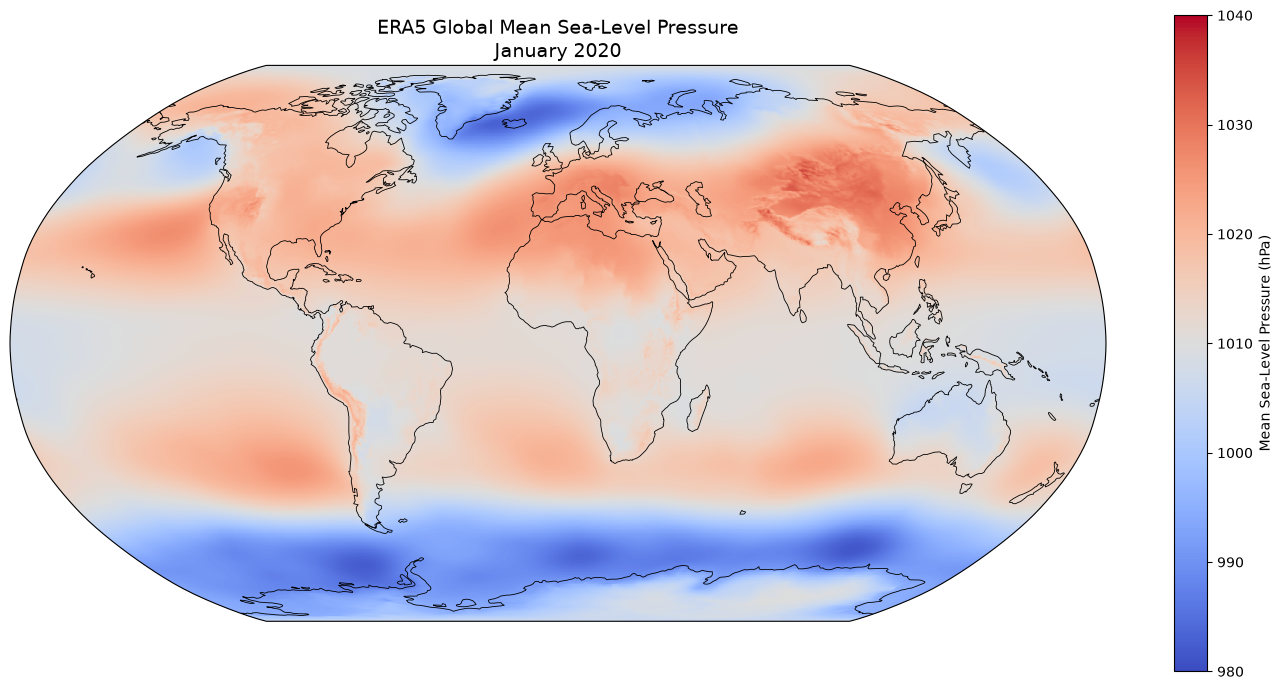


[7/7] Plotting tropical Pacific pressure...


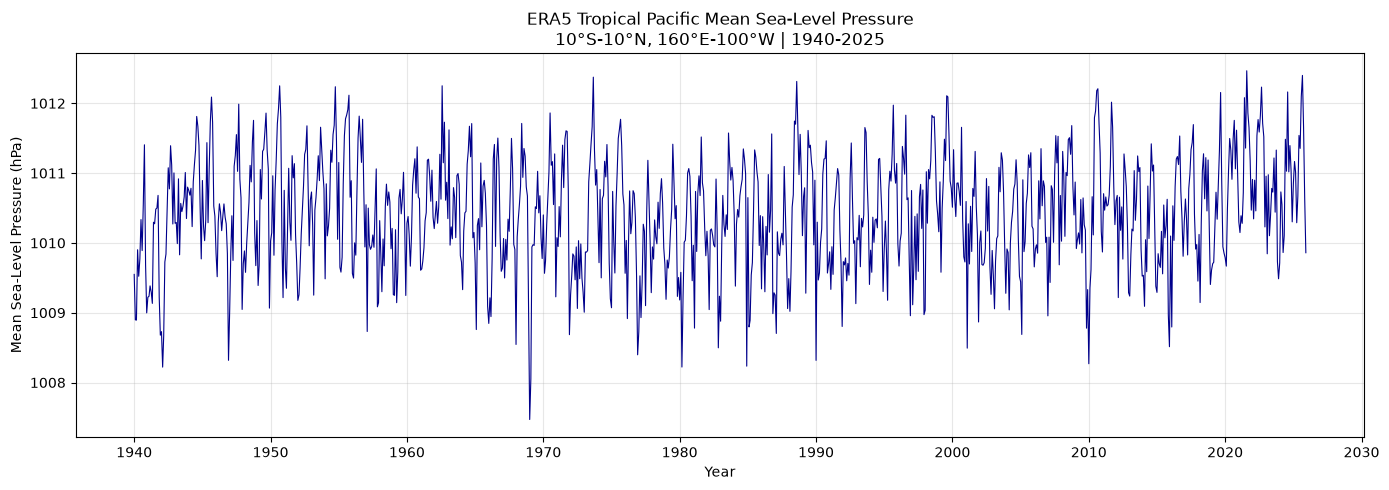


ERA5 PRESSURE VALIDATION RESULTS
[PASS] NetCDF file opens
[PASS] MSLP variable present
[PASS] Global spatial coverage
[PASS] Correct monthly time coverage
[PASS] Pressure values plausible
[PASS] No missing pressure values
[PASS] Global pressure map saved
[PASS] Pacific pressure time series saved
SUCCESS: ERA5 PRESSURE DATA PASSED ALL CHECKS!

Figures saved to: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_validation


In [12]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path

# ============================================================
# ERA5 MEAN SEA-LEVEL PRESSURE VALIDATION
# Global monthly data | 1940-2025
# ============================================================

DATA_FILE = Path(
    "data/era5/era5_global/"
    "era5_mean_sea_level_pressure_1940_2025.nc"
)

FIG_DIR = Path("figures/era5_validation")
FIG_DIR.mkdir(parents=True, exist_ok=True)

START_YEAR = 1940
END_YEAR = 2025

checks = {}

print("=" * 65)
print("ERA5 MEAN SEA-LEVEL PRESSURE VALIDATION")
print("=" * 65)

# ============================================================
# 1. FILE INTEGRITY
# ============================================================

print("\n[1/7] Checking file integrity...")

assert DATA_FILE.exists(), (
    f"File not found: {DATA_FILE.resolve()}"
)

size_gb = DATA_FILE.stat().st_size / 1024**3

print(f"File: {DATA_FILE.resolve()}")
print(f"File size: {size_gb:.2f} GB")

ds = xr.open_dataset(
    DATA_FILE,
    engine="netcdf4",
    chunks={"time": 12}
)

print("\nDataset:")
print(ds)

checks["NetCDF file opens"] = True

# ============================================================
# 2. CHECK VARIABLES AND DIMENSIONS
# ============================================================

print("\n[2/7] Checking variables and dimensions...")

# Handle different ERA5 time coordinate names
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

assert "msl" in ds.data_vars, (
    "Expected mean sea-level pressure variable 'msl'"
)

assert "time" in ds.dims
assert "latitude" in ds.dims
assert "longitude" in ds.dims

msl = ds["msl"]

print("Variable:", msl.name)
print("Dimensions:", dict(msl.sizes))
print("Units:", msl.attrs.get("units", "Unknown"))

checks["MSLP variable present"] = True

# ============================================================
# 3. VERIFY SPATIAL COVERAGE
# ============================================================

print("\n[3/7] Checking spatial coverage...")

nlat = ds.sizes["latitude"]
nlon = ds.sizes["longitude"]

lat_min = float(ds.latitude.min())
lat_max = float(ds.latitude.max())
lon_min = float(ds.longitude.min())
lon_max = float(ds.longitude.max())

print(f"Latitude points: {nlat}")
print(f"Longitude points: {nlon}")

print(f"Latitude range: {lat_min:.2f} to {lat_max:.2f}")
print(f"Longitude range: {lon_min:.2f} to {lon_max:.2f}")

checks["Global spatial coverage"] = (
    lat_min <= -89.75 and
    lat_max >= 89.75 and
    nlat >= 700 and
    nlon >= 1400
)

# ============================================================
# 4. VERIFY TEMPORAL COVERAGE
# ============================================================

print("\n[4/7] Checking temporal coverage...")

expected_months = (
    END_YEAR - START_YEAR + 1
) * 12

actual_months = ds.sizes["time"]

dates = pd.to_datetime(ds.time.values)

print("Expected months:", expected_months)
print("Actual months:", actual_months)

print("First date:", dates.min())
print("Last date:", dates.max())

# Compare year-month periods to avoid dependence
# on the exact day or hour used by ERA5.
actual_periods = pd.PeriodIndex(dates, freq="M")

expected_periods = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

checks["Correct monthly time coverage"] = (
    actual_months == expected_months and
    actual_periods.equals(expected_periods)
)

# ============================================================
# 5. PRESSURE VALUES AND MISSING DATA
# ============================================================

print("\n[5/7] Checking pressure values...")

# ERA5 MSLP is normally stored in Pascals.
units = msl.attrs.get("units", "")

if units == "Pa":
    msl_hpa = msl / 100.0
elif units in ("hPa", "millibars", "mbar"):
    msl_hpa = msl
else:
    raise ValueError(
        f"Unexpected pressure units: {units}"
    )

msl_hpa.attrs["units"] = "hPa"

# Calculate statistics lazily using Dask.
# This may take some time for the full global archive.
stats = xr.Dataset({
    "minimum": msl_hpa.min(),
    "maximum": msl_hpa.max(),
    "mean": msl_hpa.mean(),
    "missing": msl_hpa.isnull().sum(),
    "total": xr.DataArray(msl_hpa.size)
}).compute()

p_min = float(stats["minimum"])
p_max = float(stats["maximum"])
p_mean = float(stats["mean"])
missing = int(stats["missing"])
total = int(stats["total"])

missing_pct = 100 * missing / total

print(f"Minimum pressure: {p_min:.2f} hPa")
print(f"Maximum pressure: {p_max:.2f} hPa")
print(f"Mean pressure:    {p_mean:.2f} hPa")
print(f"Missing values:   {missing:,}")
print(f"Missing percent:  {missing_pct:.6f}%")

# Broad sanity bounds, not strict physical limits.
checks["Pressure values plausible"] = (
    850 < p_min < 1050 and
    950 < p_mean < 1050 and
    950 < p_max < 1150
)

checks["No missing pressure values"] = (
    missing == 0
)

# ============================================================
# 6. GLOBAL PRESSURE MAP
# ============================================================

print("\n[6/7] Plotting global pressure map...")

# One month only: avoids loading entire archive.
sample = msl_hpa.sel(
    time="2020-01"
).squeeze().compute()

fig = plt.figure(figsize=(14, 7))

ax = plt.axes(
    projection=ccrs.Robinson()
)

sample.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    vmin=980,
    vmax=1040,
    cbar_kwargs={
        "label": "Mean Sea-Level Pressure (hPa)"
    }
)

ax.coastlines(
    resolution="110m",
    linewidth=0.6
)

ax.set_global()

ax.set_title(
    "ERA5 Global Mean Sea-Level Pressure\n"
    "January 2020",
    fontsize=14
)

plt.tight_layout()

map_file = FIG_DIR / "mslp_global_jan2020.png"

plt.savefig(
    map_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

checks["Global pressure map saved"] = (
    map_file.exists()
)

# ============================================================
# 7. TROPICAL PACIFIC PRESSURE TIME SERIES
# ============================================================

print("\n[7/7] Plotting tropical Pacific pressure...")

# Convert longitude coordinates to 0-360.
msl_pacific = msl_hpa.assign_coords(
    longitude=msl_hpa.longitude % 360
).sortby("longitude").sortby("latitude")

# Tropical Pacific region
pacific = msl_pacific.sel(
    latitude=slice(-10, 10),
    longitude=slice(160, 260)
)

assert pacific.sizes["latitude"] > 0
assert pacific.sizes["longitude"] > 0

# Area-weighted average
weights = np.cos(
    np.deg2rad(pacific.latitude)
)

pacific_mean = pacific.weighted(weights).mean(
    dim=["latitude", "longitude"]
).compute()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    pacific_mean.time.values,
    pacific_mean.values,
    color="darkblue",
    linewidth=0.8
)

ax.set_title(
    "ERA5 Tropical Pacific Mean Sea-Level Pressure\n"
    "10°S-10°N, 160°E-100°W | 1940-2025"
)

ax.set_xlabel("Year")
ax.set_ylabel("Mean Sea-Level Pressure (hPa)")
ax.grid(alpha=0.3)

plt.tight_layout()

series_file = FIG_DIR / "mslp_pacific_timeseries.png"

plt.savefig(
    series_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

checks["Pacific pressure time series saved"] = (
    series_file.exists()
)

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("ERA5 PRESSURE VALIDATION RESULTS")
print("=" * 65)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 65)

if all(checks.values()):
    print("SUCCESS: ERA5 PRESSURE DATA PASSED ALL CHECKS!")
else:
    print("WARNING: Some validation checks failed.")

print(f"\nFigures saved to: {FIG_DIR.resolve()}")

ds.close()


In [15]:

import xarray as xr
from pathlib import Path

# ============================================================
# TRIM ERA5 SST DATASET TO 1940-2025
# ============================================================

DATA_DIR = Path("data/era5")

# Original SST file
input_file = DATA_DIR / "from_oscar" / "global_sst.nc"

# New trimmed file
output_file = DATA_DIR / "era5_global" / "era5_sea_surface_temperature_1940_2025.nc"

# ============================================================
# 1. OPEN DATASET
# ============================================================

print("Opening ERA5 SST dataset...")

ds = xr.open_dataset(
    input_file,
    engine="netcdf4",
    chunks={"time": 12}
)

# Handle ERA5 time coordinate naming
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

print("\nOriginal time coverage:")
print(ds.time.values[0])
print(ds.time.values[-1])
print("Months:", ds.sizes["time"])

# ============================================================
# 2. SELECT 1940-2025
# ============================================================

ds_trimmed = ds.sel(
    time=slice("1940-01-01", "2025-12-31")
)

print("\nTrimmed time coverage:")
print(ds_trimmed.time.values[0])
print(ds_trimmed.time.values[-1])
print("Months:", ds_trimmed.sizes["time"])

# Verify expected monthly coverage
assert ds_trimmed.sizes["time"] == 1032, (
    "Expected 1032 months for 1940-2025"
)

# ============================================================
# 3. SAVE TRIMMED DATASET
# ============================================================

print("\nSaving trimmed dataset...")

encoding = {
    var: {
        "zlib": True,
        "complevel": 4
    }
    for var in ds_trimmed.data_vars
}

ds_trimmed.to_netcdf(
    output_file,
    engine="netcdf4",
    encoding=encoding
)

print("\nTrimmed file saved:")
print(output_file.resolve())

print(
    f"File size: "
    f"{output_file.stat().st_size / 1024**3:.2f} GB"
)

# ============================================================
# 4. VERIFY SAVED FILE
# ============================================================

with xr.open_dataset(output_file) as check:

    assert check.sizes["time"] == 1032

    print("\nVerification successful!")
    print("First month:", check.time.values[0])
    print("Last month:", check.time.values[-1])

ds.close()

print("\nSUCCESS: ERA5 SST trimmed to 1940-2025!")


Opening ERA5 SST dataset...

Original time coverage:
1940-01-01T00:00:00.000000000
2026-10-01T00:00:00.000000000
Months: 1042

Trimmed time coverage:
1940-01-01T00:00:00.000000000
2025-12-01T00:00:00.000000000
Months: 1032

Saving trimmed dataset...

Trimmed file saved:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5\era5_global\era5_sea_surface_temperature_1940_2025.nc
File size: 0.91 GB

Verification successful!
First month: 1940-01-01T00:00:00.000000000
Last month: 2025-12-01T00:00:00.000000000

SUCCESS: ERA5 SST trimmed to 1940-2025!


ERA5 SEA SURFACE TEMPERATURE VALIDATION

[1/7] Checking file integrity...
File: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5\era5_global\era5_sea_surface_temperature_1940_2025.nc
File size: 0.91 GB

Dataset:
<xarray.Dataset> Size: 4GB
Dimensions:    (time: 1032, latitude: 721, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 8kB 1940-01-01 1940-02-01 ... 2025-12-01
    expver     (time) <U4 17kB dask.array<chunksize=(1032,), meta=np.ndarray>
  * latitude   (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude  (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number     int64 8B ...
Data variables:
    sst        (time, latitude, longitude) float32 4GB dask.array<chunksize=(296, 206, 412), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institut

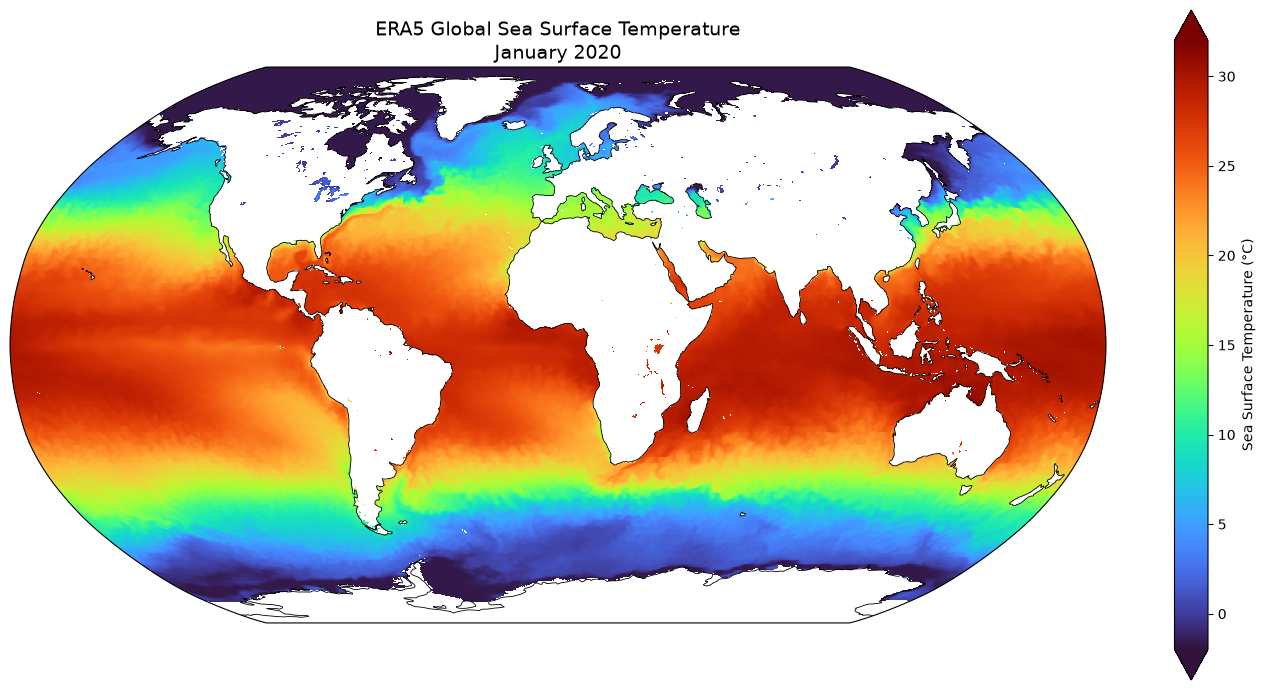


[7/7] Plotting Niño 3.4 SST time series...


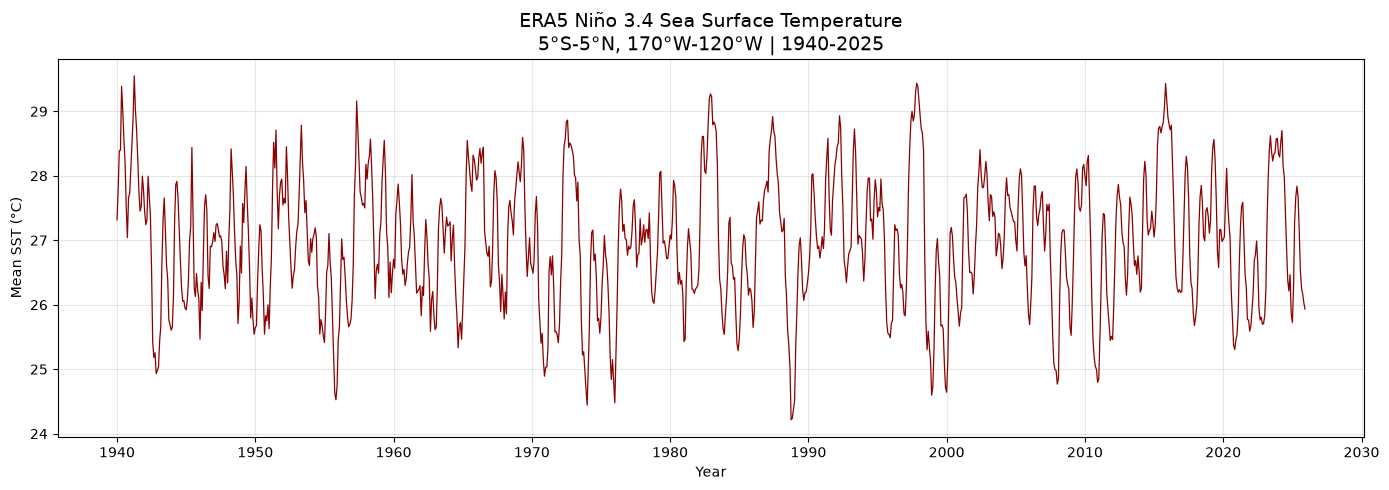


ERA5 SST VALIDATION RESULTS
[PASS] NetCDF file opens
[PASS] SST variable present
[PASS] Global spatial coverage
[PASS] Correct monthly time coverage
[PASS] SST values plausible
[PASS] Valid SST data present
[PASS] Global SST map saved
[PASS] Niño 3.4 SST time series saved
SUCCESS: ERA5 SST DATA PASSED ALL CHECKS!

Figures saved to: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_validation


In [16]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path

# ============================================================
# ERA5 SEA SURFACE TEMPERATURE VALIDATION
# Global monthly data | 1940-2025
# ============================================================

DATA_FILE = Path(
    "data/era5/era5_global/"
    "era5_sea_surface_temperature_1940_2025.nc"
)

FIG_DIR = Path("figures/era5_validation")
FIG_DIR.mkdir(parents=True, exist_ok=True)

START_YEAR = 1940
END_YEAR = 2025

checks = {}

print("=" * 65)
print("ERA5 SEA SURFACE TEMPERATURE VALIDATION")
print("=" * 65)

# ============================================================
# 1. FILE INTEGRITY
# ============================================================

print("\n[1/7] Checking file integrity...")

assert DATA_FILE.exists(), (
    f"File not found: {DATA_FILE.resolve()}"
)

size_gb = DATA_FILE.stat().st_size / 1024**3

print(f"File: {DATA_FILE.resolve()}")
print(f"File size: {size_gb:.2f} GB")

ds = xr.open_dataset(
    DATA_FILE,
    engine="netcdf4",
    chunks="auto"
)

print("\nDataset:")
print(ds)

checks["NetCDF file opens"] = True

# ============================================================
# 2. CHECK VARIABLES AND DIMENSIONS
# ============================================================

print("\n[2/7] Checking variables and dimensions...")

# Handle ERA5 time coordinate naming
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

assert "sst" in ds.data_vars, (
    "Expected sea surface temperature variable 'sst'"
)

assert "time" in ds.dims
assert "latitude" in ds.dims
assert "longitude" in ds.dims

sst = ds["sst"]

print("Variable:", sst.name)
print("Dimensions:", dict(sst.sizes))
print("Units:", sst.attrs.get("units", "Unknown"))

checks["SST variable present"] = True

# ============================================================
# 3. VERIFY SPATIAL COVERAGE
# ============================================================

print("\n[3/7] Checking spatial coverage...")

nlat = ds.sizes["latitude"]
nlon = ds.sizes["longitude"]

lat_min = float(ds.latitude.min())
lat_max = float(ds.latitude.max())
lon_min = float(ds.longitude.min())
lon_max = float(ds.longitude.max())

print(f"Latitude points: {nlat}")
print(f"Longitude points: {nlon}")

print(f"Latitude range: {lat_min:.2f} to {lat_max:.2f}")
print(f"Longitude range: {lon_min:.2f} to {lon_max:.2f}")

checks["Global spatial coverage"] = (
    lat_min <= -89.75 and
    lat_max >= 89.75 and
    nlat >= 700 and
    nlon >= 1400
)

# ============================================================
# 4. VERIFY TEMPORAL COVERAGE
# ============================================================

print("\n[4/7] Checking temporal coverage...")

expected_months = (
    END_YEAR - START_YEAR + 1
) * 12

actual_months = ds.sizes["time"]

dates = pd.to_datetime(ds.time.values)

print("Expected months:", expected_months)
print("Actual months:", actual_months)
print("First date:", dates.min())
print("Last date:", dates.max())

actual_periods = pd.PeriodIndex(
    dates,
    freq="M"
)

expected_periods = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

checks["Correct monthly time coverage"] = (
    actual_months == expected_months and
    actual_periods.equals(expected_periods)
)

# ============================================================
# 5. SST VALUES AND MISSING DATA
# ============================================================

print("\n[5/7] Checking SST values...")

units = sst.attrs.get("units", "")

# ERA5 SST is normally in Kelvin
if units in ("K", "kelvin", "Kelvin"):
    sst_c = sst - 273.15

elif units in ("degC", "C", "celsius", "degrees_C"):
    sst_c = sst

else:
    raise ValueError(
        f"Unexpected SST units: {units}"
    )

sst_c.attrs["units"] = "degC"

# Calculate global statistics.
# Missing land values are excluded automatically.
stats = xr.Dataset({
    "minimum": sst_c.min(skipna=True),
    "maximum": sst_c.max(skipna=True),
    "mean": sst_c.mean(skipna=True),
    "missing": sst_c.isnull().sum(),
    "valid": sst_c.notnull().sum()
}).compute()

t_min = float(stats["minimum"])
t_max = float(stats["maximum"])
t_mean = float(stats["mean"])

missing = int(stats["missing"])
valid = int(stats["valid"])

total = missing + valid
missing_pct = 100 * missing / total

print(f"Minimum SST: {t_min:.2f} °C")
print(f"Maximum SST: {t_max:.2f} °C")
print(f"Mean SST:    {t_mean:.2f} °C")
print(f"Missing values: {missing:,}")
print(f"Valid values:   {valid:,}")
print(f"Missing fraction: {missing_pct:.2f}%")

# Broad physical plausibility checks
checks["SST values plausible"] = (
    -5 < t_min < 10 and
    0 < t_mean < 30 and
    20 < t_max < 45
)

# Land missing values are expected.
checks["Valid SST data present"] = valid > 0

# ============================================================
# 6. GLOBAL SST MAP
# ============================================================

print("\n[6/7] Plotting global SST map...")

sample = sst_c.sel(
    time="2020-01"
).squeeze().compute()

fig = plt.figure(figsize=(14, 7))

ax = plt.axes(
    projection=ccrs.Robinson()
)

sample.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="turbo",
    vmin=-2,
    vmax=32,
    cbar_kwargs={
        "label": "Sea Surface Temperature (°C)"
    }
)

ax.coastlines(
    resolution="110m",
    linewidth=0.6
)

ax.set_global()

ax.set_title(
    "ERA5 Global Sea Surface Temperature\n"
    "January 2020",
    fontsize=14
)

plt.tight_layout()

map_file = FIG_DIR / "sst_global_jan2020.png"

plt.savefig(
    map_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

checks["Global SST map saved"] = (
    map_file.exists()
)

# ============================================================
# 7. NINO 3.4 SST TIME SERIES
# ============================================================

print("\n[7/7] Plotting Niño 3.4 SST time series...")

# Convert longitude to 0-360 and sort coordinates
sst_pacific = sst_c.assign_coords(
    longitude=sst_c.longitude % 360
).sortby("longitude").sortby("latitude")

# Niño 3.4:
# 5S-5N, 170W-120W (190E-240E)
nino34 = sst_pacific.sel(
    latitude=slice(-5, 5),
    longitude=slice(190, 240)
)

assert nino34.sizes["latitude"] > 0
assert nino34.sizes["longitude"] > 0

# Area-weighted mean
weights = np.cos(
    np.deg2rad(nino34.latitude)
)

nino34_mean = nino34.weighted(
    weights
).mean(
    dim=["latitude", "longitude"]
).compute()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    nino34_mean.time.values,
    nino34_mean.values,
    color="darkred",
    linewidth=0.9
)

ax.set_title(
    "ERA5 Niño 3.4 Sea Surface Temperature\n"
    "5°S-5°N, 170°W-120°W | 1940-2025",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Mean SST (°C)")
ax.grid(alpha=0.3)

plt.tight_layout()

series_file = FIG_DIR / "nino34_sst_timeseries.png"

plt.savefig(
    series_file,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

checks["Niño 3.4 SST time series saved"] = (
    series_file.exists()
)

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("ERA5 SST VALIDATION RESULTS")
print("=" * 65)

for name, passed in checks.items():
    status = "[PASS]" if passed else "[FAIL]"
    print(f"{status} {name}")

print("=" * 65)

if all(checks.values()):
    print("SUCCESS: ERA5 SST DATA PASSED ALL CHECKS!")
else:
    print("WARNING: Some validation checks failed.")

print(f"\nFigures saved to: {FIG_DIR.resolve()}")

ds.close()



Loading sst...
Shape: (1032, 20, 80)

Loading msl...
Shape: (1032, 20, 80)

Performing PCA...

Performing PCA...


c:\Users\Adam\miniforge3\envs\era5-analysis\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


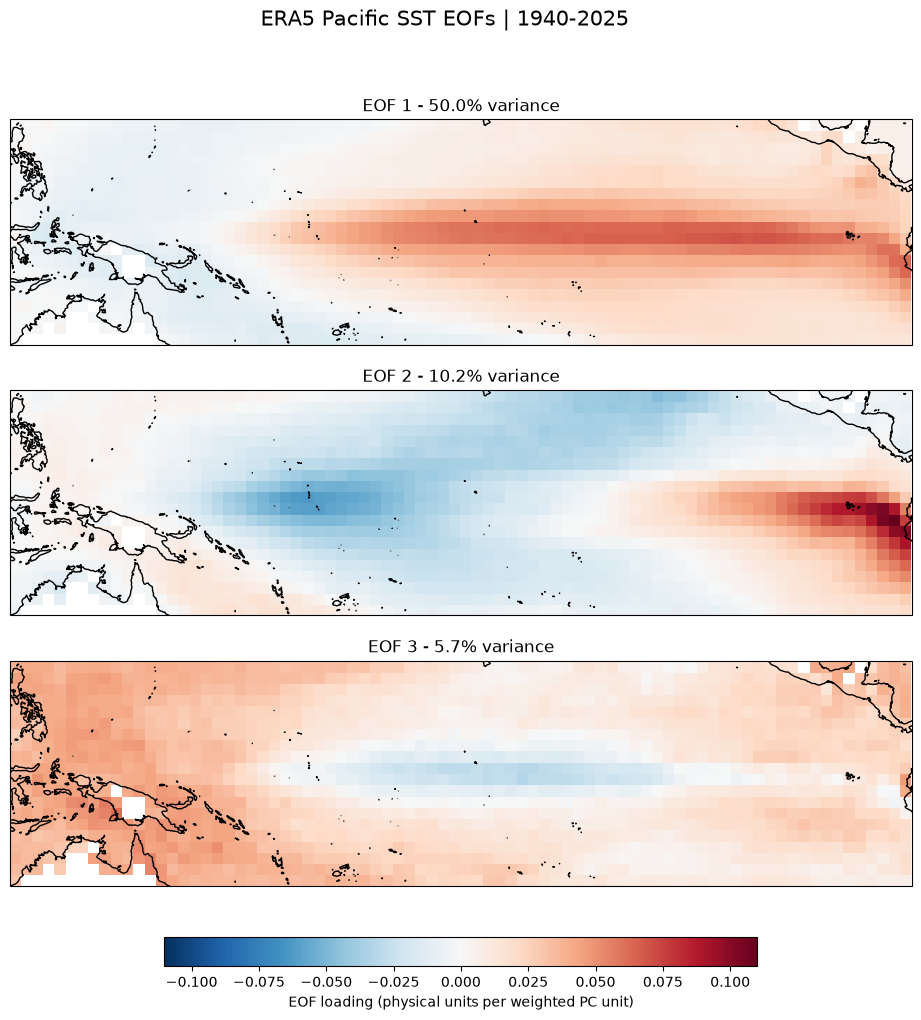

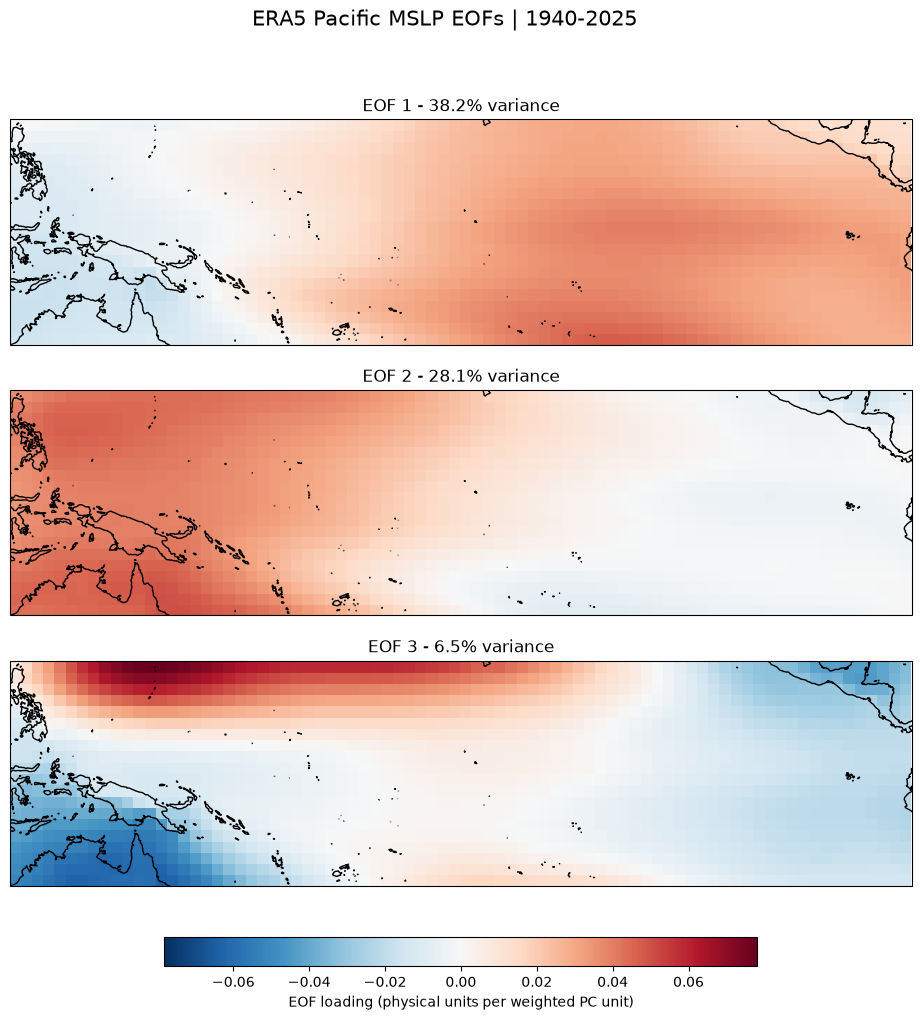

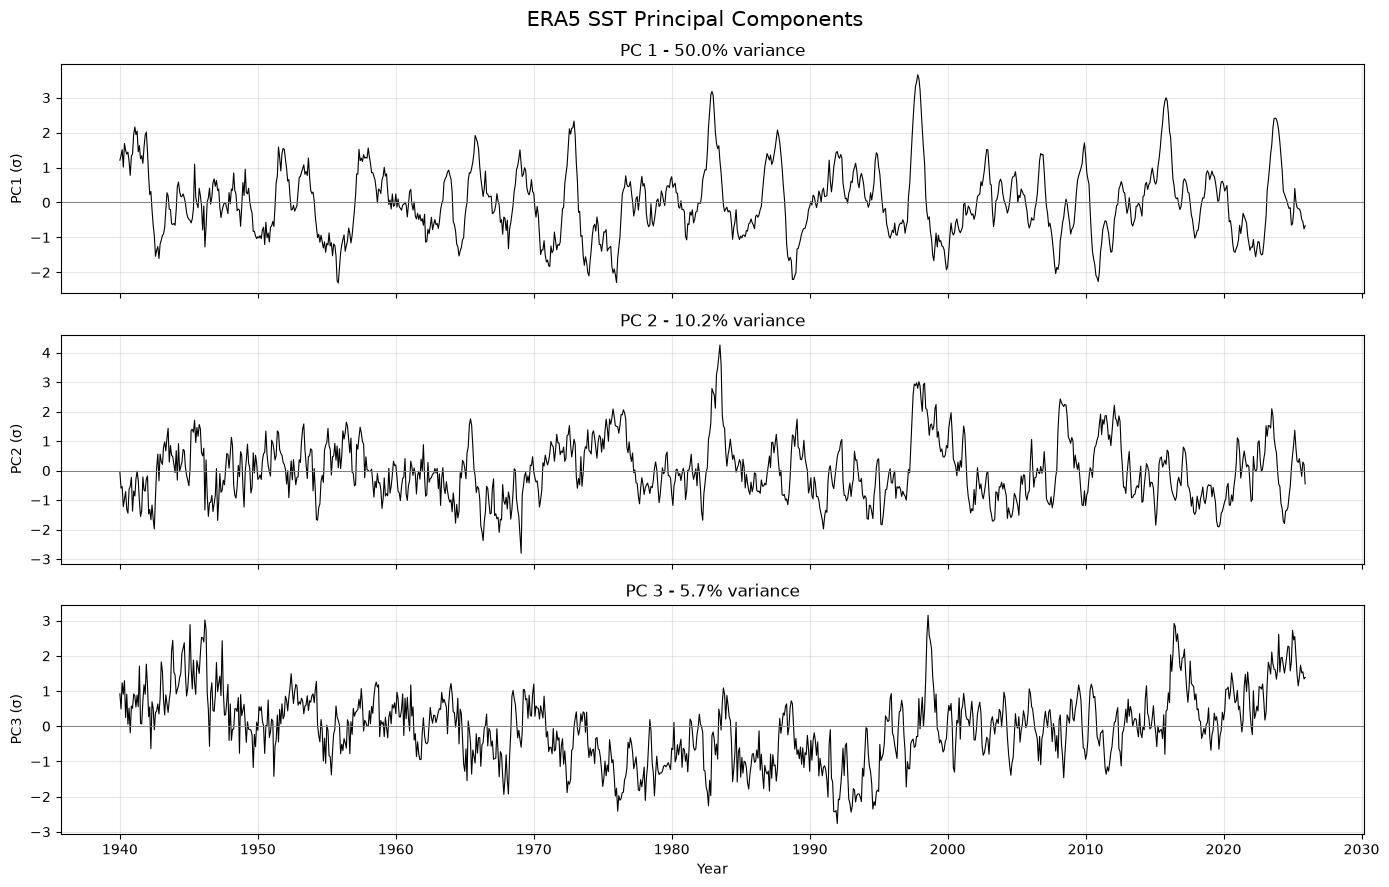

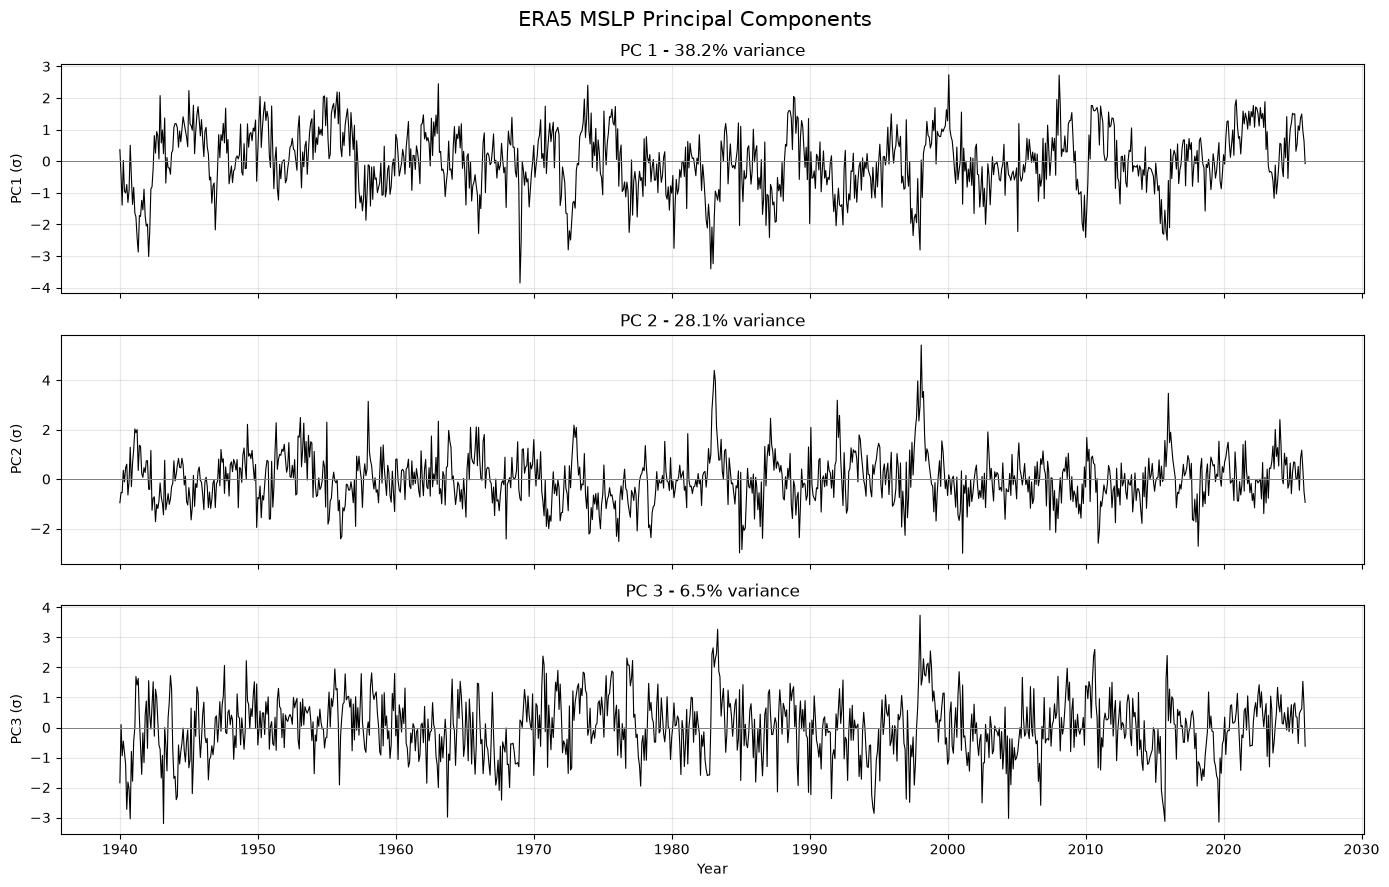


SST PC1 vs MSLP PC1 correlation: -0.6741742220768199


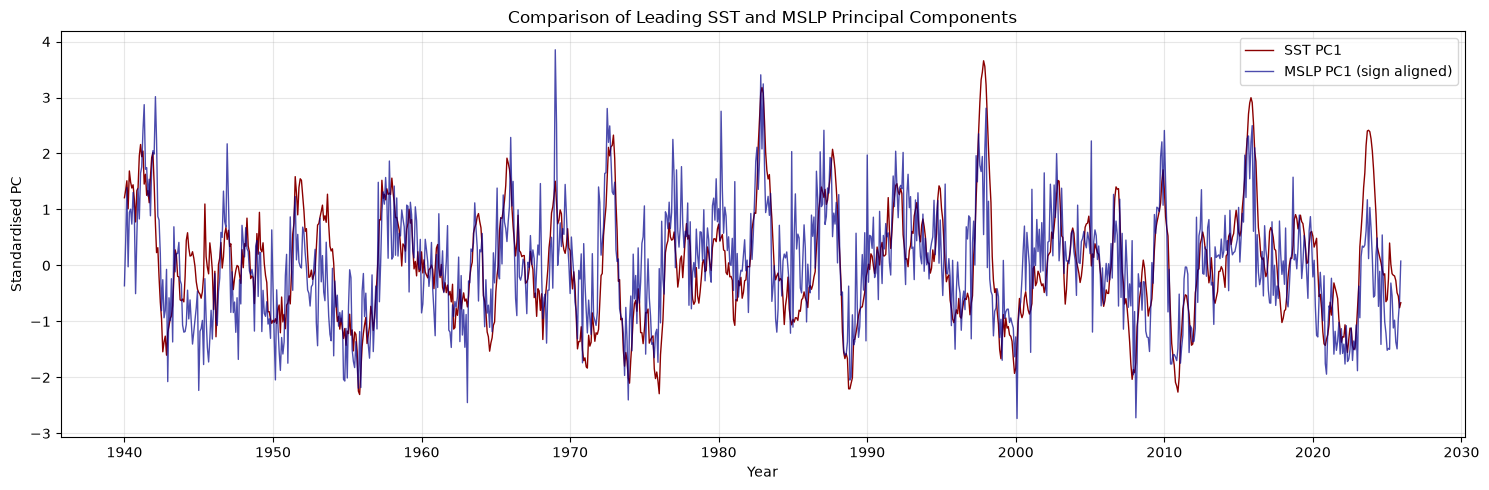


ERA5 TROPICAL PACIFIC PCA SUMMARY

SST variance explained:
  EOF 1: 49.99%
  EOF 2: 10.21%
  EOF 3: 5.73%

MSLP variance explained:
  EOF 1: 38.17%
  EOF 2: 28.08%
  EOF 3: 6.50%

Figures saved to: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_pca


In [18]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from sklearn.decomposition import PCA
from scipy.signal import detrend

# ============================================================
# ERA5 TROPICAL PACIFIC EOF / PCA ANALYSIS
# SST and MSLP | 1940-2025
# ============================================================

START_YEAR = 1940
END_YEAR = 2025
N_COMPONENTS = 3

DATA_DIR = Path("data/era5/era5_global")
FIG_DIR = Path("figures/era5_pca")
FIG_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "SST": DATA_DIR / (
        "era5_sea_surface_temperature_1940_2025.nc"
    ),
    "MSLP": DATA_DIR / (
        "era5_mean_sea_level_pressure_1940_2025.nc"
    ),
}

# ============================================================
# 1. LOAD PACIFIC REGION
# ============================================================

def load_pacific(path, variable, conversion):

    print(f"\nLoading {variable}...")

    ds = xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    )

    # Handle time coordinate
    if "valid_time" in ds.dims:
        ds = ds.rename({"valid_time": "time"})

    da = ds[variable]

    # Convert longitude to 0-360
    da = da.assign_coords(
        longitude=da.longitude % 360
    )

    da = da.sortby("longitude")
    da = da.sortby("latitude")

    # Select tropical Pacific
    da = da.sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        ),
        latitude=slice(-20, 20),
        longitude=slice(120, 280)
    )

    # Coarsen from 0.25 to approximately 2 degrees
    da = da.coarsen(
        latitude=8,
        longitude=8,
        boundary="trim"
    ).mean()

    # Unit conversion
    da = da * conversion[0] + conversion[1]

    # Load selected/coarsened data
    da = da.compute()

    print("Shape:", da.shape)

    ds.close()

    return da


sst = load_pacific(
    FILES["SST"],
    "sst",
    (1, -273.15)
)

mslp = load_pacific(
    FILES["MSLP"],
    "msl",
    (0.01, 0)
)

# ============================================================
# 2. MONTHLY ANOMALIES
# ============================================================

def calculate_anomalies(da):

    # Remove monthly seasonal climatology
    climatology = da.groupby("time.month").mean("time")

    anomalies = (
        da.groupby("time.month") - climatology
    )

    return anomalies


sst_anom = calculate_anomalies(sst)
mslp_anom = calculate_anomalies(mslp)

# ============================================================
# 3. EOF / PCA FUNCTION
# ============================================================

def perform_pca(anomalies, n_components=3):

    print("\nPerforming PCA...")

    # Shape: time x latitude x longitude
    nt = anomalies.sizes["time"]

    # Flatten spatial dimensions
    spatial_shape = (
        anomalies.sizes["latitude"],
        anomalies.sizes["longitude"]
    )

    data = anomalies.values.reshape(nt, -1)

    # Exclude grid cells containing missing values
    valid = np.isfinite(data).all(axis=0)

    X = data[:, valid]

    # Remove linear trends
    X = detrend(X, axis=0, type="linear")

    # Latitude weights: sqrt(cos(latitude))
    lat = anomalies.latitude.values
    lon = anomalies.longitude.values

    lat_weights = np.sqrt(
        np.cos(np.deg2rad(lat))
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None],
        spatial_shape
    ).reshape(-1)

    weights = weights_2d[valid]

    # Apply spatial weights
    X_weighted = X * weights

    # PCA
    pca = PCA(n_components=n_components)

    pcs = pca.fit_transform(X_weighted)

    # Convert EOFs back to physical space
    eofs_flat = np.full(
        (n_components, data.shape[1]),
        np.nan
    )

    eofs_flat[:, valid] = (
        pca.components_ / weights
    )

    eofs = eofs_flat.reshape(
        n_components,
        *spatial_shape
    )

    explained = pca.explained_variance_ratio_ * 100

    return pcs, eofs, explained


sst_pcs, sst_eofs, sst_var = perform_pca(
    sst_anom,
    N_COMPONENTS
)

mslp_pcs, mslp_eofs, mslp_var = perform_pca(
    mslp_anom,
    N_COMPONENTS
)

# ============================================================
# 4. PLOT EOF SPATIAL PATTERNS
# ============================================================

def plot_eofs(eofs, explained, da, title, filename):

    fig, axes = plt.subplots(
        3, 1,
        figsize=(13, 11),
        subplot_kw={
            "projection": ccrs.PlateCarree(
                central_longitude=180
            )
        }
    )

    lon = da.longitude.values
    lat = da.latitude.values

    vmax = np.nanmax(np.abs(eofs))

    for i, ax in enumerate(axes):

        im = ax.pcolormesh(
            lon,
            lat,
            eofs[i],
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-vmax,
            vmax=vmax,
            shading="auto"
        )

        ax.coastlines()
        ax.set_extent(
            [120, 280, -20, 20],
            crs=ccrs.PlateCarree()
        )

        ax.set_title(
            f"EOF {i+1} - "
            f"{explained[i]:.1f}% variance"
        )

    fig.colorbar(
        im,
        ax=axes,
        orientation="horizontal",
        fraction=0.035,
        pad=0.06,
        label="EOF loading (physical units per weighted PC unit)"
    )

    fig.suptitle(title, fontsize=15)

    plt.savefig(
        FIG_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


plot_eofs(
    sst_eofs,
    sst_var,
    sst,
    "ERA5 Pacific SST EOFs | 1940-2025",
    "sst_eofs.png"
)

plot_eofs(
    mslp_eofs,
    mslp_var,
    mslp,
    "ERA5 Pacific MSLP EOFs | 1940-2025",
    "mslp_eofs.png"
)

# ============================================================
# 5. PLOT PRINCIPAL COMPONENT TIME SERIES
# ============================================================

def plot_pcs(pcs, explained, da, title, filename):

    fig, axes = plt.subplots(
        3, 1,
        figsize=(14, 9),
        sharex=True
    )

    dates = pd.to_datetime(da.time.values)

    for i, ax in enumerate(axes):

        # Standardise PC to unit variance
        pc = pcs[:, i]
        pc_std = (pc - pc.mean()) / pc.std()

        ax.plot(
            dates,
            pc_std,
            color="black",
            linewidth=0.8
        )

        ax.axhline(
            0,
            color="grey",
            linewidth=0.7
        )

        ax.set_ylabel(f"PC{i+1} (σ)")

        ax.set_title(
            f"PC {i+1} - "
            f"{explained[i]:.1f}% variance"
        )

        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("Year")

    fig.suptitle(title, fontsize=15)

    plt.tight_layout()

    plt.savefig(
        FIG_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


plot_pcs(
    sst_pcs,
    sst_var,
    sst,
    "ERA5 SST Principal Components",
    "sst_pcs.png"
)

plot_pcs(
    mslp_pcs,
    mslp_var,
    mslp,
    "ERA5 MSLP Principal Components",
    "mslp_pcs.png"
)

# ============================================================
# 6. COMPARE SST AND PRESSURE PC1
# ============================================================

sst_pc1 = (
    sst_pcs[:, 0] - sst_pcs[:, 0].mean()
) / sst_pcs[:, 0].std()

mslp_pc1 = (
    mslp_pcs[:, 0] - mslp_pcs[:, 0].mean()
) / mslp_pcs[:, 0].std()

# EOF signs are arbitrary. Align pressure PC1 for
# visual comparison only.
correlation = np.corrcoef(
    sst_pc1,
    mslp_pc1
)[0, 1]

print("\nSST PC1 vs MSLP PC1 correlation:", correlation)

if correlation < 0:
    mslp_pc1 = -mslp_pc1

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    sst.time,
    sst_pc1,
    label="SST PC1",
    color="darkred",
    linewidth=1
)

ax.plot(
    mslp.time,
    mslp_pc1,
    label="MSLP PC1 (sign aligned)",
    color="darkblue",
    linewidth=1,
    alpha=0.7
)

ax.set_title(
    "Comparison of Leading SST and MSLP Principal Components"
)

ax.set_ylabel("Standardised PC")
ax.set_xlabel("Year")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "sst_mslp_pc1_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 7. SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("ERA5 TROPICAL PACIFIC PCA SUMMARY")
print("=" * 60)

print("\nSST variance explained:")
for i, v in enumerate(sst_var):
    print(f"  EOF {i+1}: {v:.2f}%")

print("\nMSLP variance explained:")
for i, v in enumerate(mslp_var):
    print(f"  EOF {i+1}: {v:.2f}%")

print("\nFigures saved to:", FIG_DIR.resolve())
print("=" * 60)


Opening ERA5 global SST...
Global SST shape: (1032, 90, 180)
Pacific SST shape: (1032, 20, 80)

Running global PCA...
Running Pacific PCA...

Global vs Pacific PC correlations:
            Pacific PC1  Pacific PC2  Pacific PC3
Global PC1        0.970       -0.067       -0.020
Global PC2        0.113       -0.069        0.638
Global PC3        0.138        0.707       -0.120


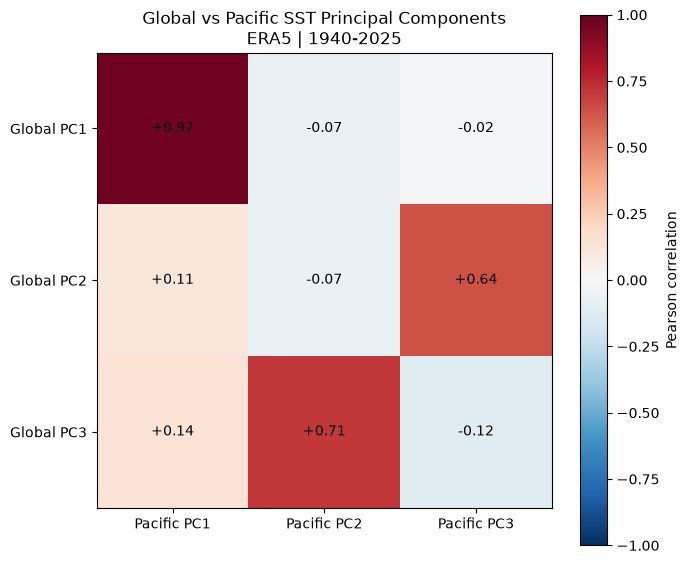

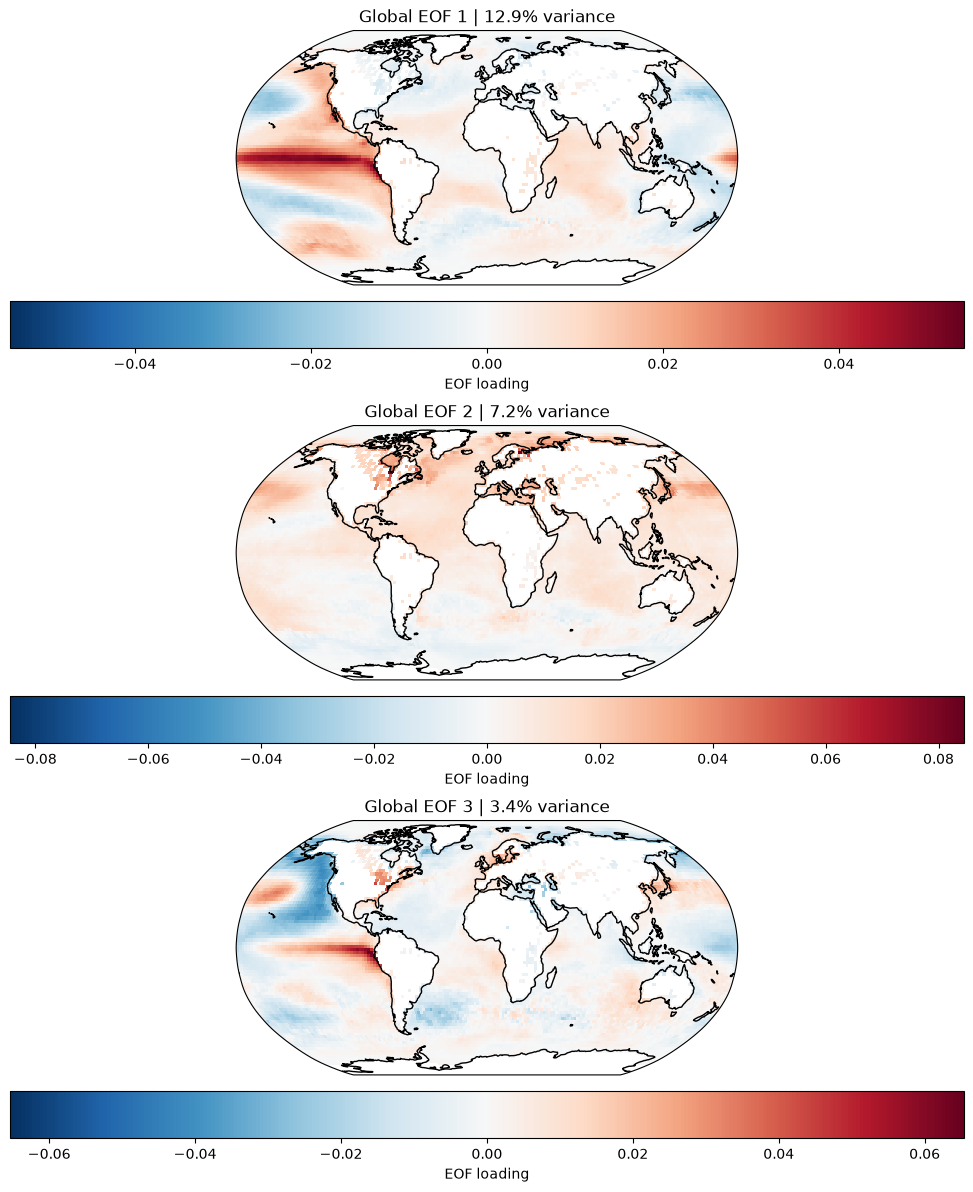

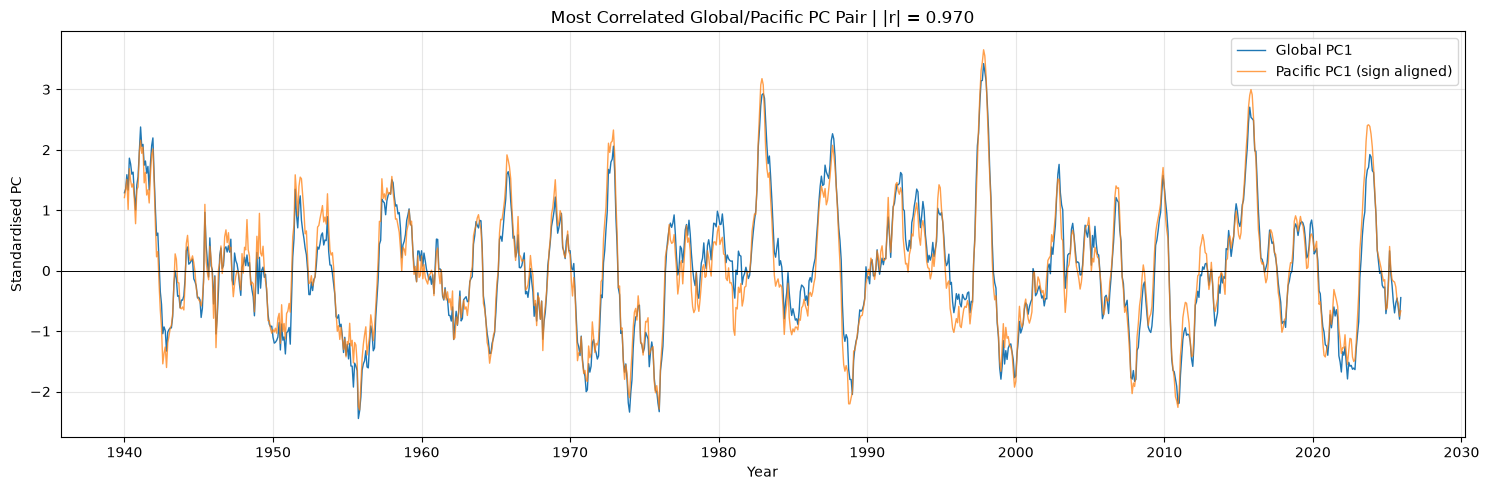


GLOBAL VS PACIFIC SST PCA SUMMARY

Global variance explained:
  PC1: 12.86%
  PC2: 7.18%
  PC3: 3.40%

Pacific variance explained:
  PC1: 49.99%
  PC2: 10.21%
  PC3: 5.73%

Strongest correlation: Global PC3 vs Pacific PC1, r=0.970

Figures saved to: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\global_pacific_pca


In [20]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from scipy.signal import detrend
from sklearn.decomposition import PCA

# ============================================================
# ERA5 GLOBAL SST PCA vs TROPICAL PACIFIC PCA
# 1940-2025 | Monthly | Approx. 2-degree grid
# ============================================================

DATA_FILE = Path(
    "data/era5/era5_global/"
    "era5_sea_surface_temperature_1940_2025.nc"
)

FIG_DIR = Path("figures/global_pacific_pca")
FIG_DIR.mkdir(parents=True, exist_ok=True)

START_YEAR = 1940
END_YEAR = 2025
N_COMPONENTS = 3
COARSEN_FACTOR = 8  # 0.25 degrees -> approx. 2 degrees

# ============================================================
# 1. LOAD AND COARSEN GLOBAL SST
# ============================================================

print("Opening ERA5 global SST...")

ds = xr.open_dataset(
    DATA_FILE,
    engine="netcdf4",
    chunks="auto"
)

if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

sst = ds["sst"]

sst = sst.sel(
    time=slice(
        f"{START_YEAR}-01-01",
        f"{END_YEAR}-12-31"
    )
)

# Convert to Celsius
sst = sst - 273.15

# Convert longitudes to 0-360
sst = sst.assign_coords(
    longitude=sst.longitude % 360
).sortby("longitude").sortby("latitude")

# Coarsen spatially before loading into memory
sst = sst.coarsen(
    latitude=COARSEN_FACTOR,
    longitude=COARSEN_FACTOR,
    boundary="trim"
).mean()

sst = sst.transpose(
    "time", "latitude", "longitude"
).compute()

assert sst.sizes["time"] == 1032
assert sst.sizes["latitude"] > 0
assert sst.sizes["longitude"] > 0

print("Global SST shape:", sst.shape)

# ============================================================
# 2. SELECT PACIFIC FROM THE SAME COARSENED GRID
# ============================================================

pacific = sst.sel(
    latitude=slice(-20, 20),
    longitude=slice(120, 280)
)

assert pacific.sizes["latitude"] > 0
assert pacific.sizes["longitude"] > 0

print("Pacific SST shape:", pacific.shape)

# ============================================================
# 3. PCA FUNCTION
# ============================================================

def calculate_pca(data, n_components=3):

    # Remove monthly seasonal cycle
    climatology = data.groupby("time.month").mean("time")
    anomalies = data.groupby("time.month") - climatology

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    matrix = anomalies.values.reshape(nt, ny * nx)

    # Only retain cells valid throughout the record
    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid]

    if X.shape[1] < n_components:
        raise ValueError("Too few valid ocean grid cells")

    # Remove linear trend at every ocean grid cell
    X = detrend(X, axis=0, type="linear")

    # Area weights for EOF analysis
    lat = anomalies.latitude.values

    weights_2d = np.broadcast_to(
        np.sqrt(
            np.clip(np.cos(np.deg2rad(lat)), 0, None)
        )[:, None],
        (ny, nx)
    )

    weights = weights_2d.reshape(-1)[valid]

    X_weighted = X * weights

    # Snapshot PCA: observations are months,
    # features are ocean grid cells.
    pca = PCA(
        n_components=n_components,
        svd_solver="randomized",
        random_state=42
    )

    pcs = pca.fit_transform(X_weighted)

    # Recover physical-space EOF patterns
    eofs_flat = np.full(
        (n_components, ny * nx),
        np.nan,
        dtype=np.float32
    )

    eofs_flat[:, valid] = (
        pca.components_ / weights
    ).astype(np.float32)

    eofs = eofs_flat.reshape(n_components, ny, nx)

    explained = pca.explained_variance_ratio_ * 100

    return pcs, eofs, explained


print("\nRunning global PCA...")
global_pcs, global_eofs, global_var = calculate_pca(
    sst, N_COMPONENTS
)

print("Running Pacific PCA...")
pacific_pcs, pacific_eofs, pacific_var = calculate_pca(
    pacific, N_COMPONENTS
)

# ============================================================
# 4. CORRELATION MATRIX
# ============================================================

# Standardise PC time series
def standardise(pcs):
    return (
        pcs - pcs.mean(axis=0)
    ) / pcs.std(axis=0, ddof=1)

G = standardise(global_pcs)
P = standardise(pacific_pcs)

# Correlate each global PC with each Pacific PC
correlations = np.corrcoef(
    G.T, P.T
)[:N_COMPONENTS, N_COMPONENTS:]

print("\nGlobal vs Pacific PC correlations:")
print(
    pd.DataFrame(
        correlations,
        index=[f"Global PC{i+1}" for i in range(N_COMPONENTS)],
        columns=[f"Pacific PC{i+1}" for i in range(N_COMPONENTS)]
    ).round(3)
)

# ============================================================
# 5. PLOT CORRELATION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(N_COMPONENTS))
ax.set_yticks(range(N_COMPONENTS))

ax.set_xticklabels(
    [f"Pacific PC{i+1}" for i in range(N_COMPONENTS)]
)

ax.set_yticklabels(
    [f"Global PC{i+1}" for i in range(N_COMPONENTS)]
)

for i in range(N_COMPONENTS):
    for j in range(N_COMPONENTS):
        ax.text(
            j, i,
            f"{correlations[i, j]:+.2f}",
            ha="center",
            va="center",
            color="black"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Pearson correlation"
)

ax.set_title(
    "Global vs Pacific SST Principal Components\n"
    "ERA5 | 1940-2025"
)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "pc_correlation_matrix.png",
    dpi=200
)
plt.show()

# ============================================================
# 6. PLOT GLOBAL EOF MAPS
# ============================================================

fig, axes = plt.subplots(
    N_COMPONENTS, 1,
    figsize=(14, 4 * N_COMPONENTS),
    subplot_kw={"projection": ccrs.Robinson()}
)

axes = np.atleast_1d(axes)

for i, ax in enumerate(axes):

    pattern = global_eofs[i]

    vmax = np.nanmax(np.abs(pattern))

    im = ax.pcolormesh(
        sst.longitude.values,
        sst.latitude.values,
        pattern,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        shading="auto"
    )

    ax.coastlines(resolution="110m")
    ax.set_global()

    ax.set_title(
        f"Global EOF {i+1} | "
        f"{global_var[i]:.1f}% variance"
    )

    fig.colorbar(
        im, ax=ax,
        orientation="horizontal",
        pad=0.05,
        shrink=0.7,
        label="EOF loading"
    )

plt.tight_layout()
plt.savefig(
    FIG_DIR / "global_sst_eofs.png",
    dpi=200
)
plt.show()

# ============================================================
# 7. COMPARE MOST CORRELATED PC PAIR
# ============================================================

i, j = np.unravel_index(
    np.argmax(np.abs(correlations)),
    correlations.shape
)

r = correlations[i, j]

# Align sign for visual comparison only
global_series = G[:, i]
pacific_series = P[:, j] * np.sign(r)

dates = pd.to_datetime(sst.time.values)

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    dates,
    global_series,
    label=f"Global PC{i+1}",
    linewidth=1
)

ax.plot(
    dates,
    pacific_series,
    label=f"Pacific PC{j+1} (sign aligned)",
    linewidth=1,
    alpha=0.75
)

ax.axhline(0, color="black", linewidth=0.7)

ax.set_title(
    f"Most Correlated Global/Pacific PC Pair "
    f"| |r| = {abs(r):.3f}"
)

ax.set_ylabel("Standardised PC")
ax.set_xlabel("Year")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "global_pacific_pc_comparison.png",
    dpi=200
)
plt.show()

# ============================================================
# 8. SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("GLOBAL VS PACIFIC SST PCA SUMMARY")
print("=" * 60)

print("\nGlobal variance explained:")
for i, v in enumerate(global_var):
    print(f"  PC{i+1}: {v:.2f}%")

print("\nPacific variance explained:")
for i, v in enumerate(pacific_var):
    print(f"  PC{i+1}: {v:.2f}%")

print(
    f"\nStrongest correlation: "
    f"Global PC{i+1} vs Pacific PC{j+1}, r={r:.3f}"
)

print("\nFigures saved to:", FIG_DIR.resolve())

ds.close()


ERA5 GLOBAL vs PACIFIC PRESSURE PCA

[1/8] Opening ERA5 global MSLP...
Global MSLP shape: (1032, 90, 180)
Pressure units: hPa

[2/8] Selecting tropical Pacific...
Pacific MSLP shape: (1032, 20, 80)

[3/8] Running global pressure PCA...
[OK] Global PCA complete

[4/8] Running Pacific pressure PCA...
[OK] Pacific PCA complete

[5/8] Calculating correlations...

Global vs Pacific PC correlations:
            Pacific PC1  Pacific PC2  Pacific PC3
Global PC1       -0.179       -0.091        0.034
Global PC2       -0.225       -0.048        0.055
Global PC3       -0.296        0.266       -0.153

[6/8] Plotting correlation matrix...


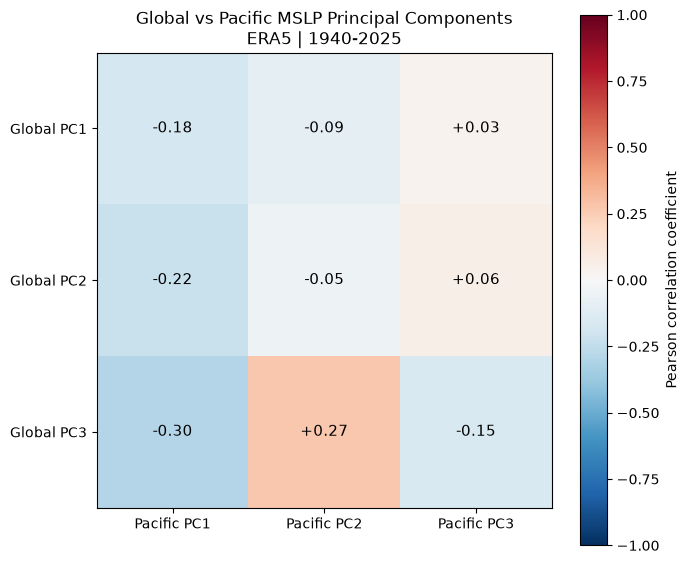


[7/8] Plotting global EOF patterns...


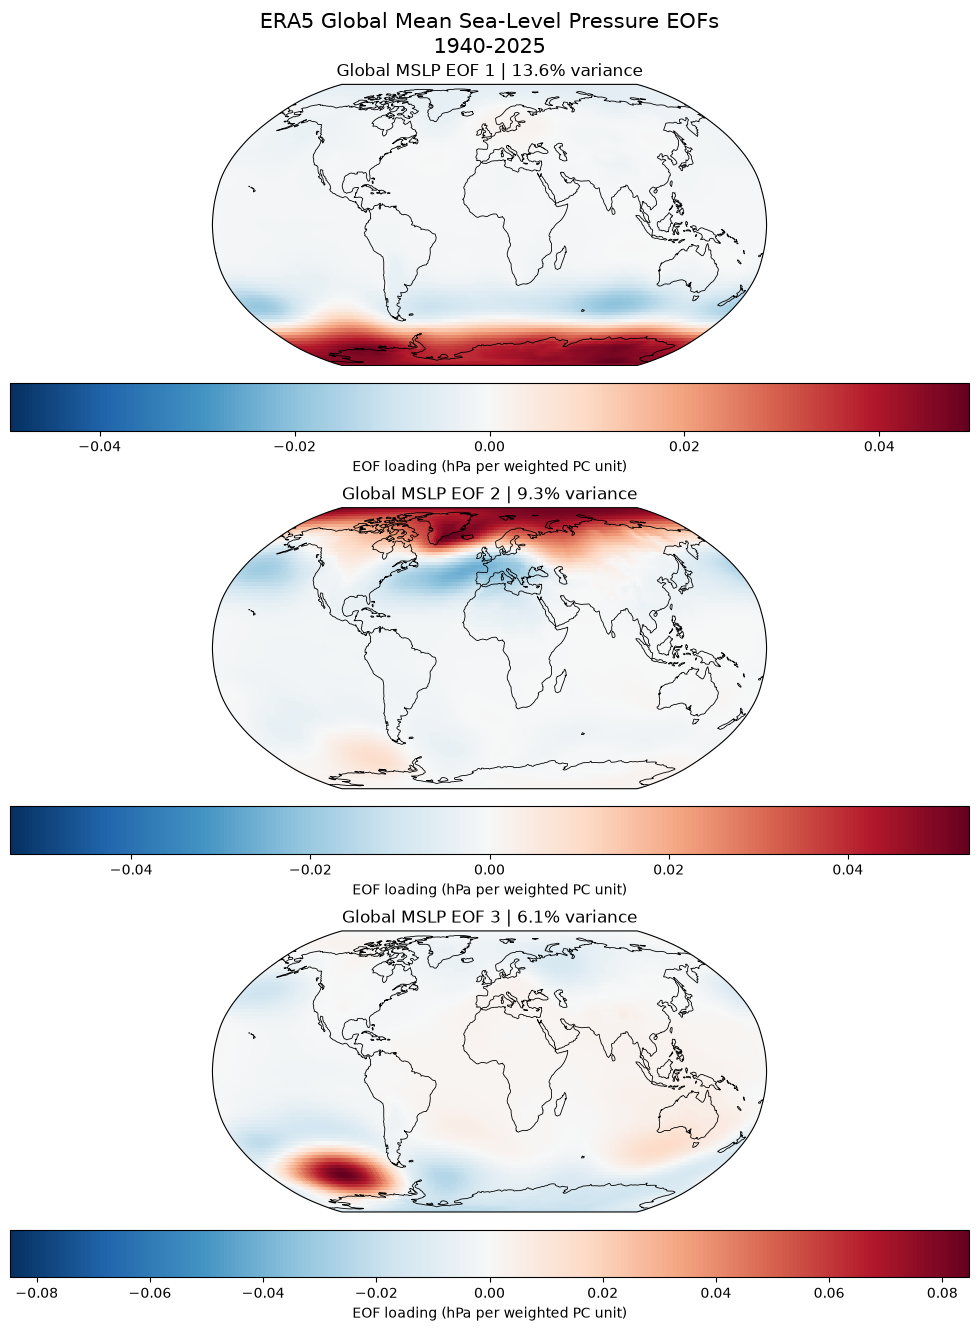


[8/8] Comparing principal components...


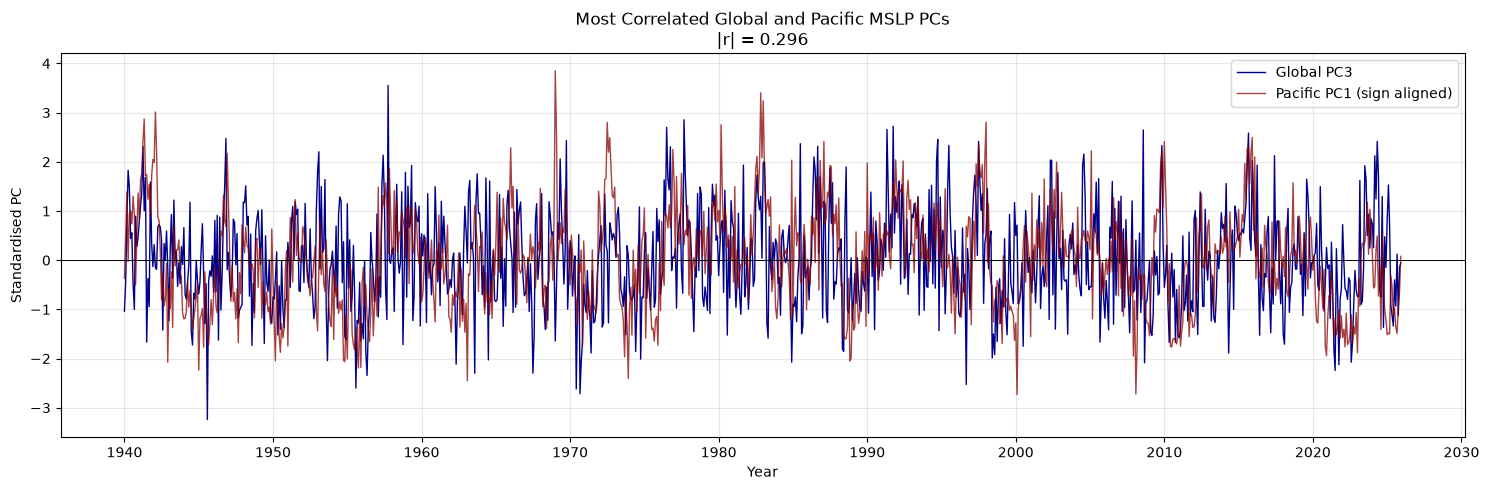


ERA5 GLOBAL vs PACIFIC PRESSURE PCA SUMMARY

Global MSLP variance explained:
  EOF 1: 13.60%
  EOF 2: 9.25%
  EOF 3: 6.10%

Pacific MSLP variance explained:
  EOF 1: 38.17%
  EOF 2: 28.08%
  EOF 3: 6.50%

Strongest global/Pacific correlation:
  Global PC3 vs Pacific PC1
  Pearson r = -0.296
  Absolute correlation = 0.296

Figures saved to:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\global_pacific_mslp_pca


In [21]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from scipy.signal import detrend
from sklearn.decomposition import PCA

# ============================================================
# ERA5 GLOBAL MSLP PCA vs TROPICAL PACIFIC MSLP PCA
# 1940-2025 | Monthly | Approx. 2-degree grid
# ============================================================

DATA_FILE = Path(
    "data/era5/era5_global/"
    "era5_mean_sea_level_pressure_1940_2025.nc"
)

FIG_DIR = Path("figures/global_pacific_mslp_pca")
FIG_DIR.mkdir(parents=True, exist_ok=True)

START_YEAR = 1940
END_YEAR = 2025

N_COMPONENTS = 3
COARSEN_FACTOR = 8  # 0.25 degrees -> approximately 2 degrees

# ============================================================
# 1. LOAD AND COARSEN GLOBAL MSLP
# ============================================================

print("=" * 65)
print("ERA5 GLOBAL vs PACIFIC PRESSURE PCA")
print("=" * 65)

print("\n[1/8] Opening ERA5 global MSLP...")

ds = xr.open_dataset(
    DATA_FILE,
    engine="netcdf4",
    chunks="auto"
)

# Handle ERA5 time coordinate naming
if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

mslp = ds["msl"]

# Select historical period
mslp = mslp.sel(
    time=slice(
        f"{START_YEAR}-01-01",
        f"{END_YEAR}-12-31"
    )
)

# Convert pressure from Pa to hPa
mslp = mslp / 100.0
mslp.attrs["units"] = "hPa"

# Convert longitude to 0-360
mslp = mslp.assign_coords(
    longitude=mslp.longitude % 360
)

# Sort coordinates
mslp = mslp.sortby("longitude")
mslp = mslp.sortby("latitude")

# Coarsen before loading into memory
mslp = mslp.coarsen(
    latitude=COARSEN_FACTOR,
    longitude=COARSEN_FACTOR,
    boundary="trim"
).mean()

mslp = mslp.transpose(
    "time",
    "latitude",
    "longitude"
).compute()

assert mslp.sizes["time"] == 1032, (
    "Expected 1032 months (1940-2025)"
)

print("Global MSLP shape:", mslp.shape)
print("Pressure units:", mslp.attrs.get("units"))

# ============================================================
# 2. SELECT TROPICAL PACIFIC
# ============================================================

print("\n[2/8] Selecting tropical Pacific...")

pacific = mslp.sel(
    latitude=slice(-20, 20),
    longitude=slice(120, 280)
)

assert pacific.sizes["latitude"] > 0
assert pacific.sizes["longitude"] > 0

print("Pacific MSLP shape:", pacific.shape)

# ============================================================
# 3. PCA FUNCTION
# ============================================================

def calculate_pca(data, n_components=3):

    # Remove monthly seasonal cycle
    climatology = data.groupby(
        "time.month"
    ).mean("time")

    anomalies = (
        data.groupby("time.month") - climatology
    )

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    # Reshape to time x spatial grid points
    matrix = anomalies.values.reshape(
        nt,
        ny * nx
    )

    # Retain cells valid throughout the record
    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid]

    if X.shape[1] < n_components:
        raise ValueError(
            "Too few valid grid cells for PCA"
        )

    # Remove linear trend at every grid point
    X = detrend(
        X,
        axis=0,
        type="linear"
    )

    # Latitude weights for EOF analysis
    lat = anomalies.latitude.values

    lat_weights = np.sqrt(
        np.clip(
            np.cos(np.deg2rad(lat)),
            0,
            None
        )
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None],
        (ny, nx)
    )

    weights = weights_2d.reshape(-1)[valid]

    # Avoid zero weights at the poles
    positive = weights > 1e-8

    X = X[:, positive]
    weights = weights[positive]

    valid_indices = np.flatnonzero(valid)[positive]

    # Apply area weighting
    X_weighted = X * weights

    # PCA using randomized SVD
    pca = PCA(
        n_components=n_components,
        svd_solver="randomized",
        random_state=42
    )

    pcs = pca.fit_transform(X_weighted)

    # Recover EOF patterns in physical space
    eofs_flat = np.full(
        (n_components, ny * nx),
        np.nan,
        dtype=np.float32
    )

    eofs_flat[:, valid_indices] = (
        pca.components_ / weights
    ).astype(np.float32)

    eofs = eofs_flat.reshape(
        n_components,
        ny,
        nx
    )

    explained = (
        pca.explained_variance_ratio_ * 100
    )

    return pcs, eofs, explained


# ============================================================
# 4. RUN GLOBAL AND PACIFIC PCA
# ============================================================

print("\n[3/8] Running global pressure PCA...")

global_pcs, global_eofs, global_var = calculate_pca(
    mslp,
    N_COMPONENTS
)

print("[OK] Global PCA complete")

print("\n[4/8] Running Pacific pressure PCA...")

pacific_pcs, pacific_eofs, pacific_var = calculate_pca(
    pacific,
    N_COMPONENTS
)

print("[OK] Pacific PCA complete")

# ============================================================
# 5. CALCULATE PC CORRELATIONS
# ============================================================

print("\n[5/8] Calculating correlations...")

def standardise(pcs):

    return (
        pcs - pcs.mean(axis=0)
    ) / pcs.std(axis=0, ddof=1)


G = standardise(global_pcs)
P = standardise(pacific_pcs)

# Correlation matrix:
# Rows = global PCs
# Columns = Pacific PCs
correlations = np.corrcoef(
    G.T,
    P.T
)[:N_COMPONENTS, N_COMPONENTS:]

correlation_df = pd.DataFrame(
    correlations,
    index=[
        f"Global PC{i+1}"
        for i in range(N_COMPONENTS)
    ],
    columns=[
        f"Pacific PC{i+1}"
        for i in range(N_COMPONENTS)
    ]
)

print("\nGlobal vs Pacific PC correlations:")
print(correlation_df.round(3))

# ============================================================
# 6. PLOT CORRELATION MATRIX
# ============================================================

print("\n[6/8] Plotting correlation matrix...")

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(N_COMPONENTS))
ax.set_yticks(range(N_COMPONENTS))

ax.set_xticklabels(
    [
        f"Pacific PC{i+1}"
        for i in range(N_COMPONENTS)
    ]
)

ax.set_yticklabels(
    [
        f"Global PC{i+1}"
        for i in range(N_COMPONENTS)
    ]
)

# Add correlation coefficients
for i in range(N_COMPONENTS):
    for j in range(N_COMPONENTS):

        value = correlations[i, j]

        ax.text(
            j,
            i,
            f"{value:+.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=11
        )

fig.colorbar(
    im,
    ax=ax,
    label="Pearson correlation coefficient"
)

ax.set_title(
    "Global vs Pacific MSLP Principal Components\n"
    "ERA5 | 1940-2025"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "mslp_pc_correlation_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 7. PLOT GLOBAL PRESSURE EOF MAPS
# ============================================================

print("\n[7/8] Plotting global EOF patterns...")

fig, axes = plt.subplots(
    N_COMPONENTS,
    1,
    figsize=(14, 4.5 * N_COMPONENTS),
    subplot_kw={
        "projection": ccrs.Robinson()
    }
)

axes = np.atleast_1d(axes)

for i, ax in enumerate(axes):

    pattern = global_eofs[i]

    vmax = np.nanmax(np.abs(pattern))

    im = ax.pcolormesh(
        mslp.longitude.values,
        mslp.latitude.values,
        pattern,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        shading="auto"
    )

    ax.coastlines(
        resolution="110m",
        linewidth=0.6
    )

    ax.set_global()

    ax.set_title(
        f"Global MSLP EOF {i+1} | "
        f"{global_var[i]:.1f}% variance"
    )

    fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.05,
        shrink=0.7,
        label="EOF loading (hPa per weighted PC unit)"
    )

fig.suptitle(
    "ERA5 Global Mean Sea-Level Pressure EOFs\n"
    "1940-2025",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "global_mslp_eofs.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. COMPARE MOST CORRELATED PC PAIR
# ============================================================

print("\n[8/8] Comparing principal components...")

best_global, best_pacific = np.unravel_index(
    np.argmax(np.abs(correlations)),
    correlations.shape
)

r = correlations[
    best_global,
    best_pacific
]

# EOF signs are arbitrary.
# Align signs for visual comparison only.
global_series = G[:, best_global]

pacific_series = (
    P[:, best_pacific] * np.sign(r)
)

dates = pd.to_datetime(
    mslp.time.values
)

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    dates,
    global_series,
    label=f"Global PC{best_global+1}",
    linewidth=1,
    color="darkblue"
)

ax.plot(
    dates,
    pacific_series,
    label=(
        f"Pacific PC{best_pacific+1} "
        "(sign aligned)"
    ),
    linewidth=1,
    color="darkred",
    alpha=0.75
)

ax.axhline(
    0,
    color="black",
    linewidth=0.7
)

ax.set_title(
    "Most Correlated Global and Pacific MSLP PCs\n"
    f"|r| = {abs(r):.3f}"
)

ax.set_ylabel("Standardised PC")
ax.set_xlabel("Year")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "global_pacific_mslp_pc_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. SAVE RESULTS AND SUMMARY
# ============================================================

correlation_df.to_csv(
    FIG_DIR / "mslp_pc_correlations.csv"
)

print("\n" + "=" * 65)
print("ERA5 GLOBAL vs PACIFIC PRESSURE PCA SUMMARY")
print("=" * 65)

print("\nGlobal MSLP variance explained:")

for i, variance in enumerate(global_var):
    print(
        f"  EOF {i+1}: {variance:.2f}%"
    )

print("\nPacific MSLP variance explained:")

for i, variance in enumerate(pacific_var):
    print(
        f"  EOF {i+1}: {variance:.2f}%"
    )

print("\nStrongest global/Pacific correlation:")

print(
    f"  Global PC{best_global+1} vs "
    f"Pacific PC{best_pacific+1}"
)

print(f"  Pearson r = {r:.3f}")
print(f"  Absolute correlation = {abs(r):.3f}")

print("\nFigures saved to:")
print(FIG_DIR.resolve())

print("=" * 65)

ds.close()



Loading sst...
Shape: (1032, 65, 80)

Loading msl...
Shape: (1032, 65, 80)

Applying common ocean mask...
Ocean grid cells: 4608

Performing PCA...

Performing PCA...


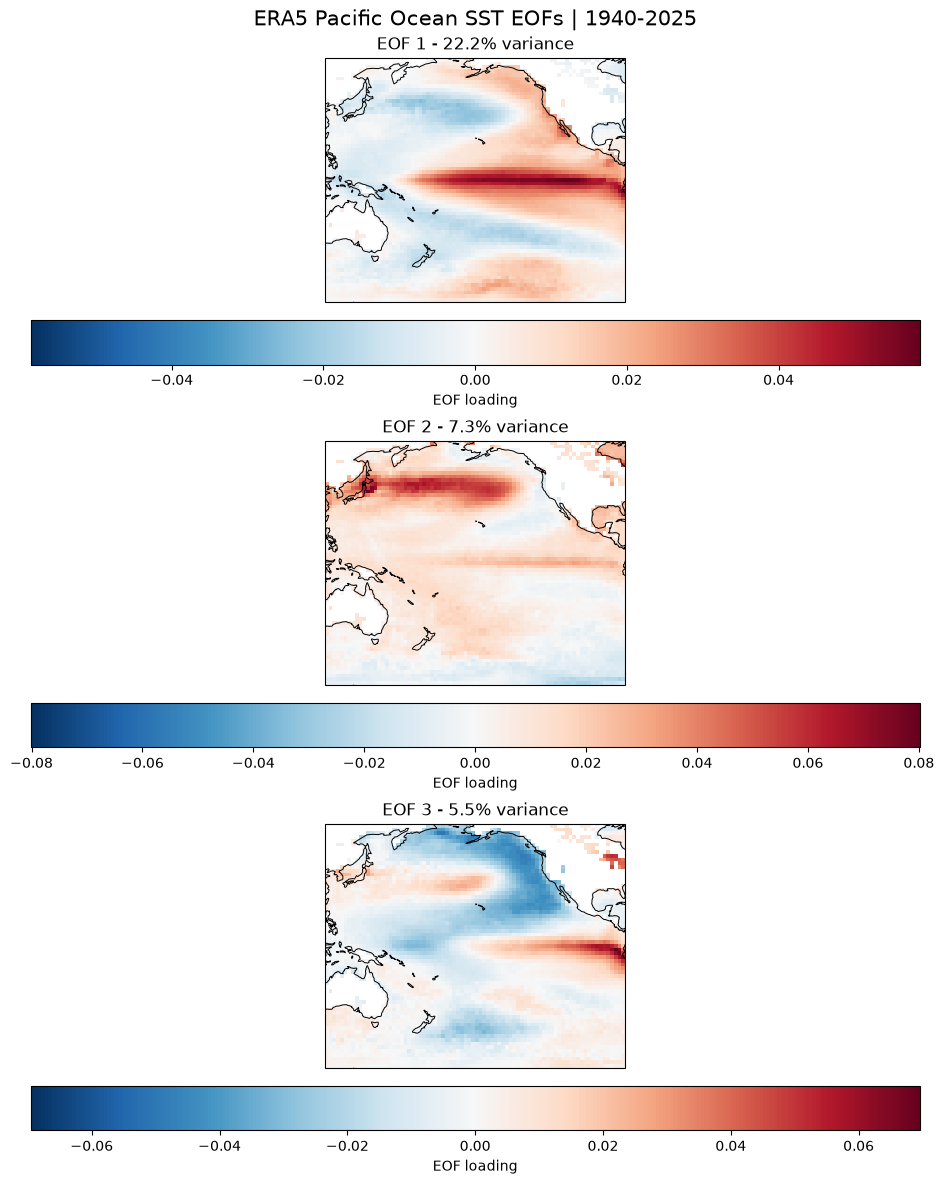

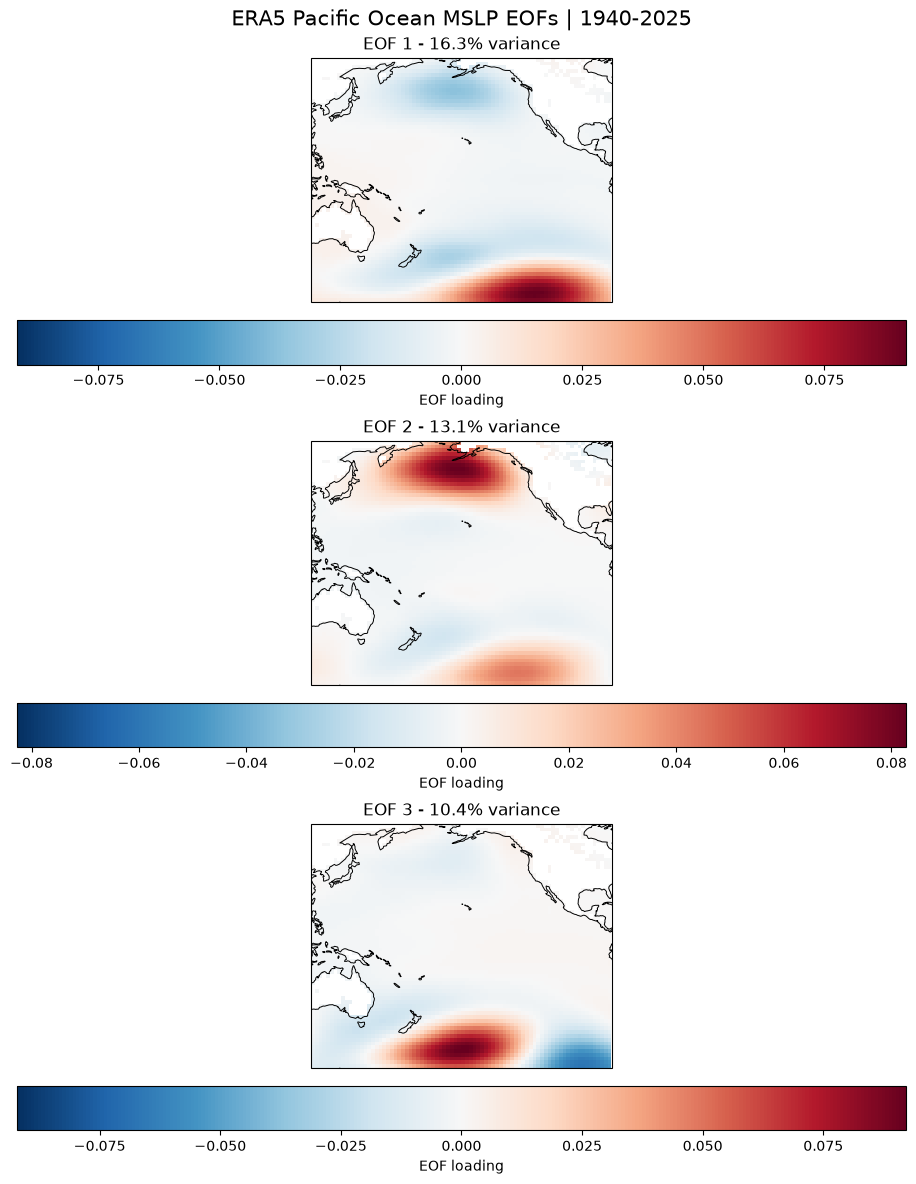

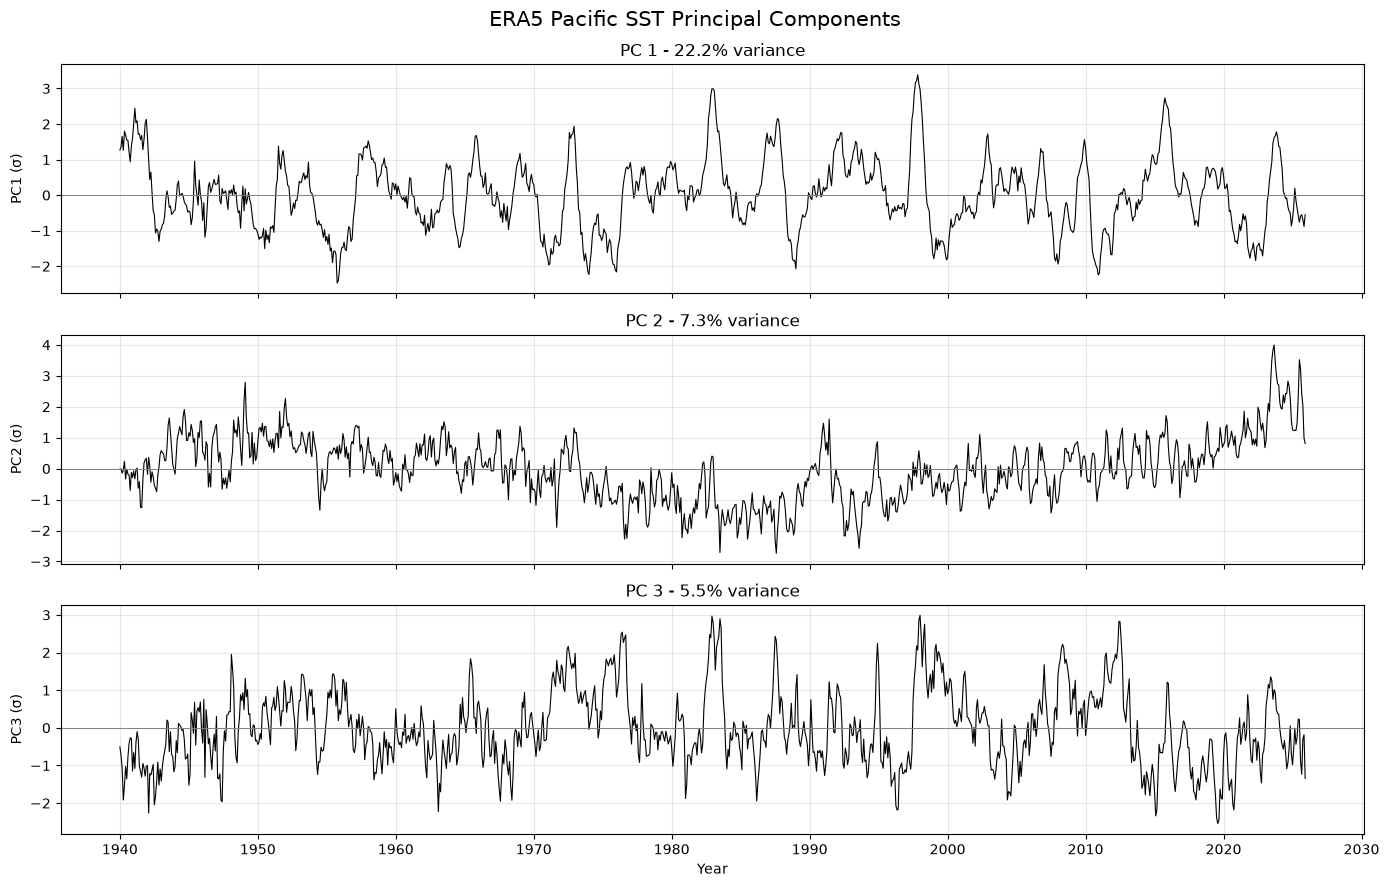

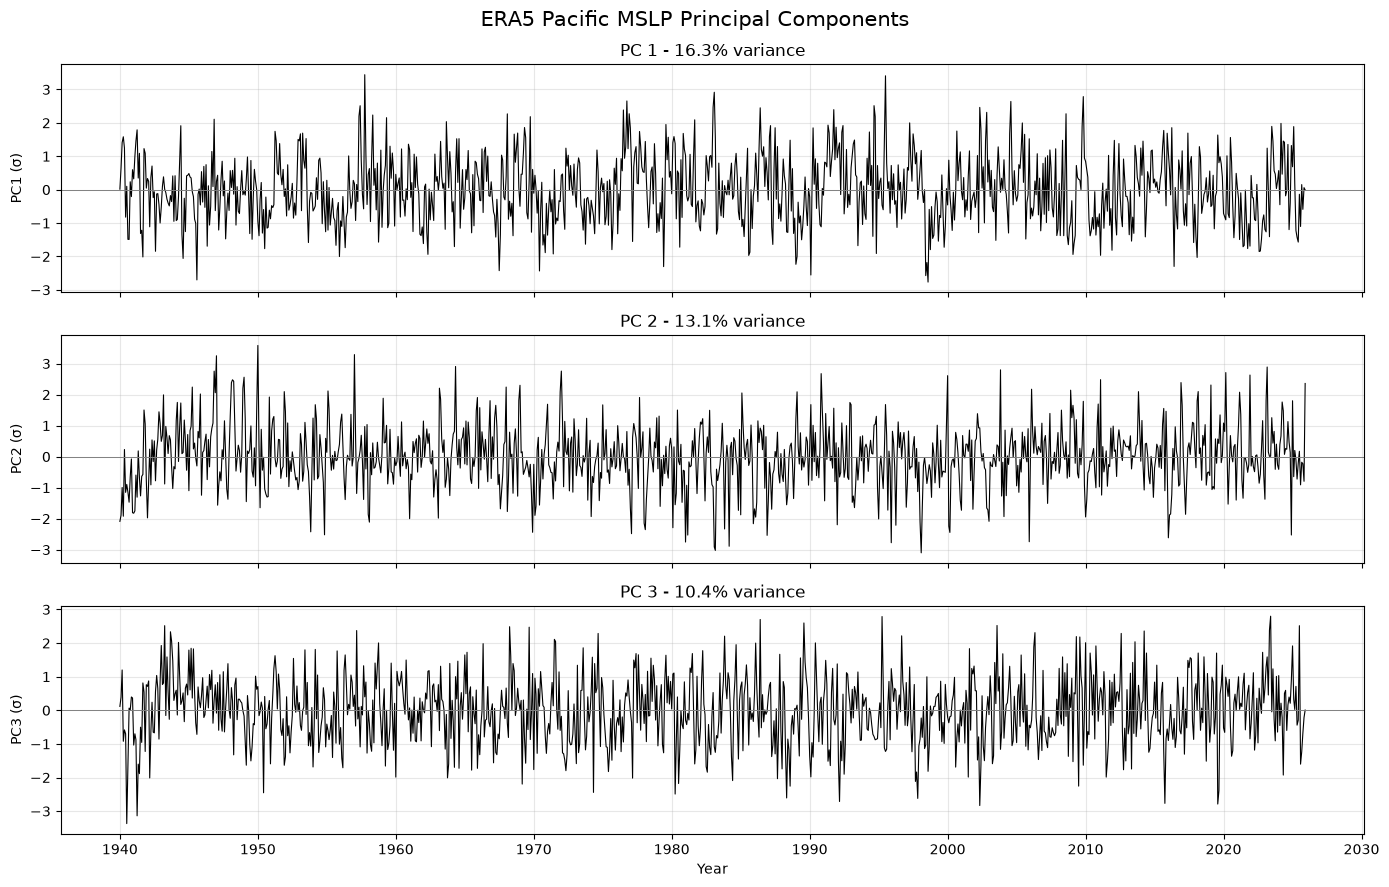


Comparing SST and MSLP PCs...

SST vs MSLP PC correlations:
         MSLP PC1  MSLP PC2  MSLP PC3
SST PC1     0.393    -0.149    -0.147
SST PC2    -0.039     0.219     0.015
SST PC3    -0.042     0.022    -0.131


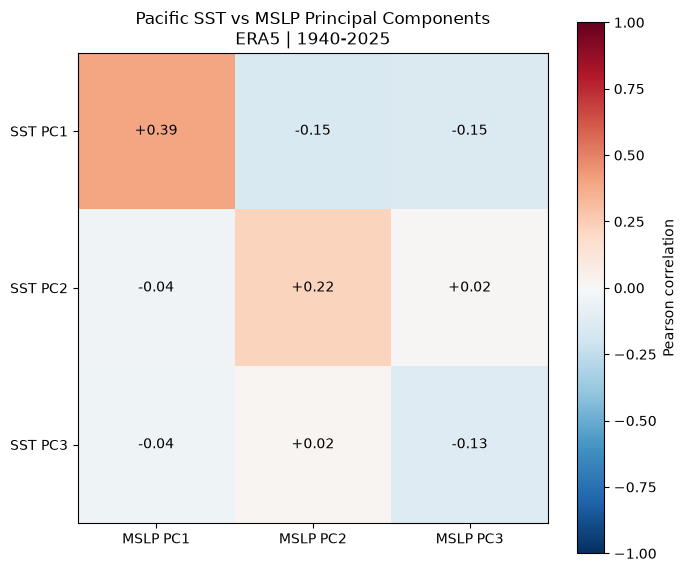

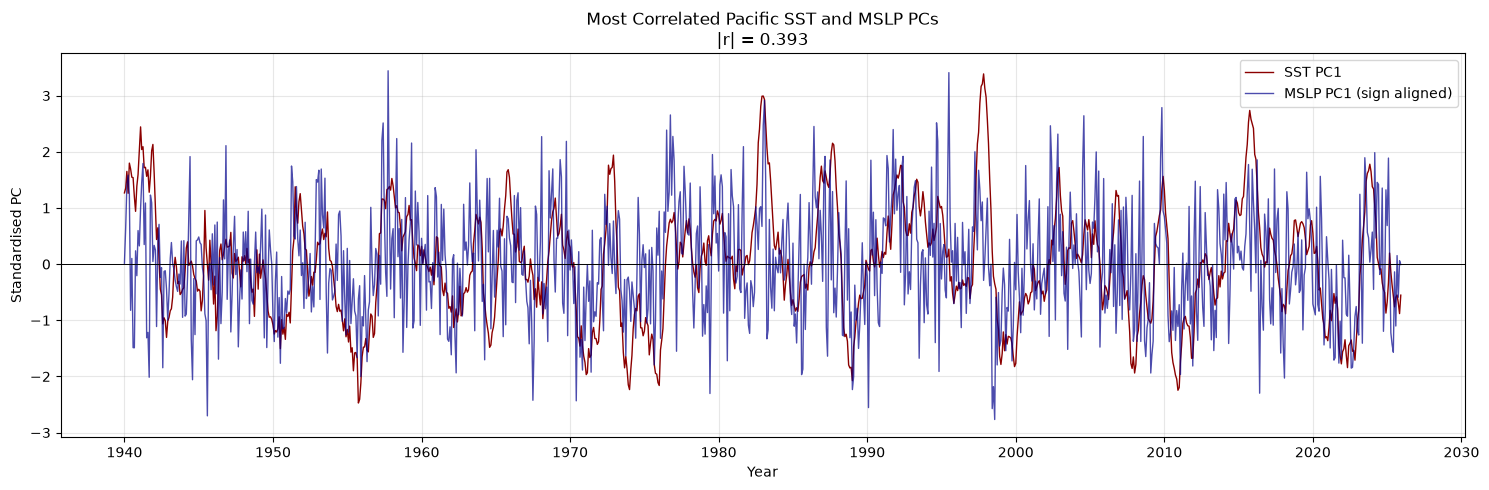


ERA5 FULL PACIFIC PCA SUMMARY

SST variance explained:
  EOF 1: 22.18%
  EOF 2: 7.35%
  EOF 3: 5.50%

MSLP variance explained:
  EOF 1: 16.26%
  EOF 2: 13.11%
  EOF 3: 10.41%

Strongest SST/MSLP PC correlation:
  SST PC1 vs MSLP PC1: r = 0.393

Figures saved to:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_pca_full_pacific


In [22]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from sklearn.decomposition import PCA
from scipy.signal import detrend

# ============================================================
# ERA5 PACIFIC OCEAN EOF / PCA ANALYSIS
# SST and MSLP | 1940-2025
# ============================================================

START_YEAR = 1940
END_YEAR = 2025
N_COMPONENTS = 3

# Approximate full Pacific basin
LAT_MIN = -65
LAT_MAX = 65
LON_MIN = 120
LON_MAX = 280

# Coarsen 0.25-degree ERA5 to approximately 2 degrees
COARSEN_FACTOR = 8

DATA_DIR = Path("data/era5/era5_global")
FIG_DIR = Path("figures/era5_pca_full_pacific")
FIG_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "SST": DATA_DIR / (
        "era5_sea_surface_temperature_1940_2025.nc"
    ),
    "MSLP": DATA_DIR / (
        "era5_mean_sea_level_pressure_1940_2025.nc"
    ),
}

# ============================================================
# 1. LOAD PACIFIC REGION
# ============================================================

def load_pacific(path, variable, conversion):

    print(f"\nLoading {variable}...")

    ds = xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    )

    if "valid_time" in ds.dims:
        ds = ds.rename({"valid_time": "time"})

    da = ds[variable]

    # Convert longitude to 0-360
    da = da.assign_coords(
        longitude=da.longitude % 360
    )

    # Sort coordinates
    da = da.sortby("longitude")
    da = da.sortby("latitude")

    # Select full Pacific region
    da = da.sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        ),
        latitude=slice(LAT_MIN, LAT_MAX),
        longitude=slice(LON_MIN, LON_MAX)
    )

    # Coarsen spatial resolution
    da = da.coarsen(
        latitude=COARSEN_FACTOR,
        longitude=COARSEN_FACTOR,
        boundary="trim"
    ).mean()

    # Convert units
    da = da * conversion[0] + conversion[1]

    da = da.transpose(
        "time", "latitude", "longitude"
    ).compute()

    print("Shape:", da.shape)

    ds.close()

    return da


sst = load_pacific(
    FILES["SST"],
    "sst",
    (1, -273.15)
)

mslp = load_pacific(
    FILES["MSLP"],
    "msl",
    (0.01, 0)
)

# ============================================================
# 2. APPLY COMMON OCEAN MASK
# ============================================================

print("\nApplying common ocean mask...")

# Use SST validity to identify ocean grid cells.
# Retain cells with valid SST throughout the record.
ocean_mask = sst.notnull().all("time")

# Apply identical spatial mask to both variables
sst = sst.where(ocean_mask)
mslp = mslp.where(ocean_mask)

print(
    "Ocean grid cells:",
    int(ocean_mask.sum())
)

# ============================================================
# 3. MONTHLY ANOMALIES
# ============================================================

def calculate_anomalies(da):

    climatology = da.groupby(
        "time.month"
    ).mean("time")

    return (
        da.groupby("time.month") - climatology
    )


sst_anom = calculate_anomalies(sst)
mslp_anom = calculate_anomalies(mslp)

# ============================================================
# 4. EOF / PCA FUNCTION
# ============================================================

def perform_pca(anomalies, n_components=3):

    print("\nPerforming PCA...")

    nt = anomalies.sizes["time"]

    spatial_shape = (
        anomalies.sizes["latitude"],
        anomalies.sizes["longitude"]
    )

    data = anomalies.values.reshape(nt, -1)

    # Exclude missing grid cells
    valid = np.isfinite(data).all(axis=0)

    X = data[:, valid]

    if X.shape[1] < n_components:
        raise ValueError(
            "Too few valid ocean grid cells for PCA"
        )

    # Remove linear trends at every grid point
    X = detrend(
        X,
        axis=0,
        type="linear"
    )

    # EOF area weights
    lat = anomalies.latitude.values

    lat_weights = np.sqrt(
        np.clip(
            np.cos(np.deg2rad(lat)),
            0,
            None
        )
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None],
        spatial_shape
    ).reshape(-1)

    weights = weights_2d[valid]

    # Apply area weighting
    X_weighted = X * weights

    # PCA
    pca = PCA(
        n_components=n_components,
        svd_solver="randomized",
        random_state=42
    )

    pcs = pca.fit_transform(X_weighted)

    # Reconstruct EOF maps
    eofs_flat = np.full(
        (n_components, data.shape[1]),
        np.nan
    )

    eofs_flat[:, valid] = (
        pca.components_ / weights
    )

    eofs = eofs_flat.reshape(
        n_components,
        *spatial_shape
    )

    explained = (
        pca.explained_variance_ratio_ * 100
    )

    return pcs, eofs, explained


sst_pcs, sst_eofs, sst_var = perform_pca(
    sst_anom,
    N_COMPONENTS
)

mslp_pcs, mslp_eofs, mslp_var = perform_pca(
    mslp_anom,
    N_COMPONENTS
)

# ============================================================
# 5. PLOT EOF SPATIAL PATTERNS
# ============================================================

def plot_eofs(eofs, explained, da, title, filename):

    fig, axes = plt.subplots(
        N_COMPONENTS,
        1,
        figsize=(13, 4 * N_COMPONENTS),
        subplot_kw={
            "projection": ccrs.PlateCarree(
                central_longitude=180
            )
        }
    )

    axes = np.atleast_1d(axes)

    lon = da.longitude.values
    lat = da.latitude.values

    for i, ax in enumerate(axes):

        vmax = np.nanmax(np.abs(eofs[i]))

        im = ax.pcolormesh(
            lon,
            lat,
            eofs[i],
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-vmax,
            vmax=vmax,
            shading="auto"
        )

        ax.coastlines(
            resolution="110m",
            linewidth=0.7
        )

        ax.set_extent(
            [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
            crs=ccrs.PlateCarree()
        )

        ax.set_title(
            f"EOF {i+1} - "
            f"{explained[i]:.1f}% variance"
        )

        fig.colorbar(
            im,
            ax=ax,
            orientation="horizontal",
            shrink=0.7,
            pad=0.06,
            label="EOF loading"
        )

    fig.suptitle(
        title,
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        FIG_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


plot_eofs(
    sst_eofs,
    sst_var,
    sst,
    "ERA5 Pacific Ocean SST EOFs | 1940-2025",
    "sst_eofs_full_pacific.png"
)

plot_eofs(
    mslp_eofs,
    mslp_var,
    mslp,
    "ERA5 Pacific Ocean MSLP EOFs | 1940-2025",
    "mslp_eofs_full_pacific.png"
)

# ============================================================
# 6. PLOT PRINCIPAL COMPONENT TIME SERIES
# ============================================================

def plot_pcs(pcs, explained, da, title, filename):

    fig, axes = plt.subplots(
        N_COMPONENTS,
        1,
        figsize=(14, 9),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    dates = pd.to_datetime(
        da.time.values
    )

    for i, ax in enumerate(axes):

        pc = pcs[:, i]

        pc_std = (
            pc - pc.mean()
        ) / pc.std()

        ax.plot(
            dates,
            pc_std,
            color="black",
            linewidth=0.8
        )

        ax.axhline(
            0,
            color="grey",
            linewidth=0.7
        )

        ax.set_ylabel(
            f"PC{i+1} (σ)"
        )

        ax.set_title(
            f"PC {i+1} - "
            f"{explained[i]:.1f}% variance"
        )

        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("Year")

    fig.suptitle(
        title,
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        FIG_DIR / filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


plot_pcs(
    sst_pcs,
    sst_var,
    sst,
    "ERA5 Pacific SST Principal Components",
    "sst_pcs_full_pacific.png"
)

plot_pcs(
    mslp_pcs,
    mslp_var,
    mslp,
    "ERA5 Pacific MSLP Principal Components",
    "mslp_pcs_full_pacific.png"
)

# ============================================================
# 7. COMPARE SST AND PRESSURE PRINCIPAL COMPONENTS
# ============================================================

print("\nComparing SST and MSLP PCs...")

# Standardise all three components
sst_std = (
    sst_pcs - sst_pcs.mean(axis=0)
) / sst_pcs.std(axis=0)

mslp_std = (
    mslp_pcs - mslp_pcs.mean(axis=0)
) / mslp_pcs.std(axis=0)

# Correlation matrix between SST and pressure PCs
correlations = np.corrcoef(
    sst_std.T,
    mslp_std.T
)[:N_COMPONENTS, N_COMPONENTS:]

correlation_df = pd.DataFrame(
    correlations,
    index=[
        f"SST PC{i+1}"
        for i in range(N_COMPONENTS)
    ],
    columns=[
        f"MSLP PC{i+1}"
        for i in range(N_COMPONENTS)
    ]
)

print("\nSST vs MSLP PC correlations:")
print(correlation_df.round(3))

# Plot correlation matrix
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(N_COMPONENTS))
ax.set_yticks(range(N_COMPONENTS))

ax.set_xticklabels(correlation_df.columns)
ax.set_yticklabels(correlation_df.index)

for i in range(N_COMPONENTS):
    for j in range(N_COMPONENTS):
        ax.text(
            j, i,
            f"{correlations[i, j]:+.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Pearson correlation"
)

ax.set_title(
    "Pacific SST vs MSLP Principal Components\n"
    "ERA5 | 1940-2025"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "sst_mslp_pc_correlations.png",
    dpi=200
)

plt.show()

# ============================================================
# 8. COMPARE MOST CORRELATED PC PAIR
# ============================================================

best_sst, best_mslp = np.unravel_index(
    np.argmax(np.abs(correlations)),
    correlations.shape
)

r = correlations[best_sst, best_mslp]

sst_series = sst_std[:, best_sst]
mslp_series = (
    mslp_std[:, best_mslp] * np.sign(r)
)

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    sst.time,
    sst_series,
    label=f"SST PC{best_sst+1}",
    color="darkred",
    linewidth=1
)

ax.plot(
    mslp.time,
    mslp_series,
    label=f"MSLP PC{best_mslp+1} (sign aligned)",
    color="darkblue",
    linewidth=1,
    alpha=0.7
)

ax.axhline(
    0,
    color="black",
    linewidth=0.7
)

ax.set_title(
    "Most Correlated Pacific SST and MSLP PCs\n"
    f"|r| = {abs(r):.3f}"
)

ax.set_ylabel("Standardised PC")
ax.set_xlabel("Year")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "sst_mslp_pc_comparison.png",
    dpi=200
)

plt.show()

# ============================================================
# 9. SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("ERA5 FULL PACIFIC PCA SUMMARY")
print("=" * 60)

print("\nSST variance explained:")
for i, v in enumerate(sst_var):
    print(f"  EOF {i+1}: {v:.2f}%")

print("\nMSLP variance explained:")
for i, v in enumerate(mslp_var):
    print(f"  EOF {i+1}: {v:.2f}%")

print("\nStrongest SST/MSLP PC correlation:")
print(
    f"  SST PC{best_sst+1} vs "
    f"MSLP PC{best_mslp+1}: r = {r:.3f}"
)

print("\nFigures saved to:")
print(FIG_DIR.resolve())

print("=" * 60)


Opening ERA5 SST dataset...
Calculating area-weighted Nino 3.4 SST...
Mean SST calculated.
Months: 1032
Calculating monthly SST anomalies...
Calculating detrended anomalies...
Linear SST trend: 0.0138 degC/decade


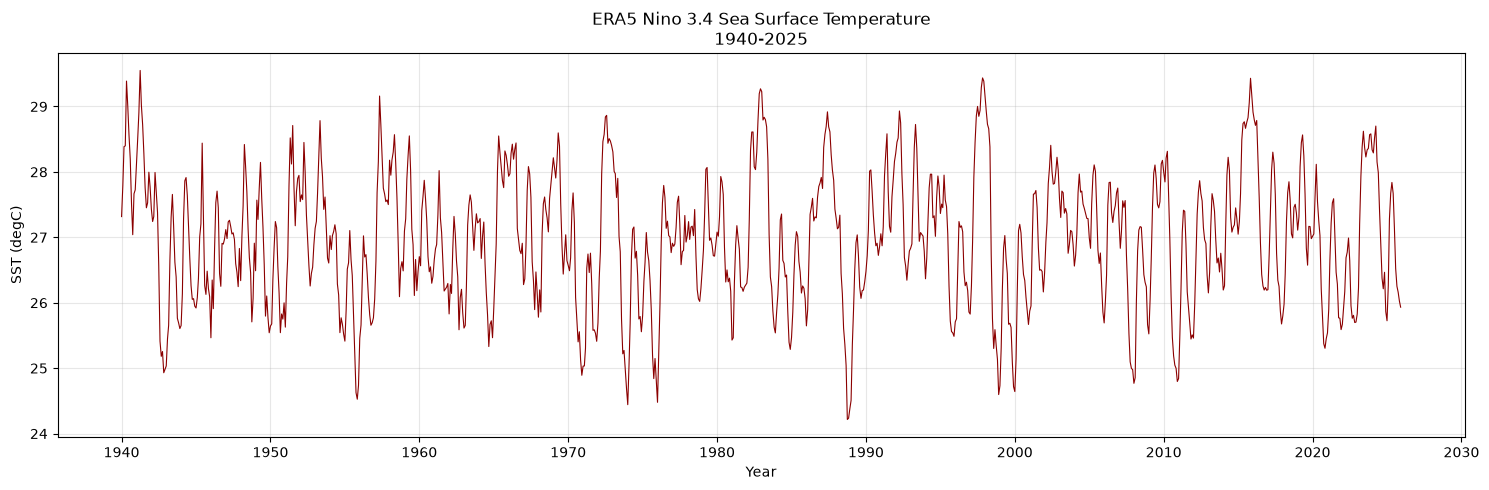

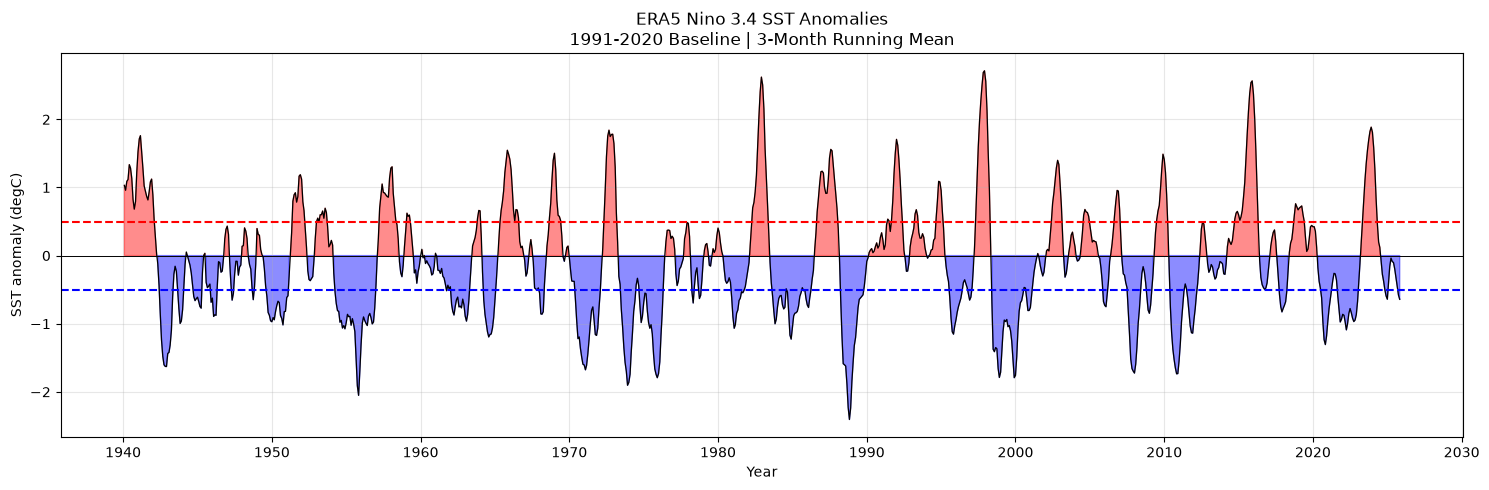

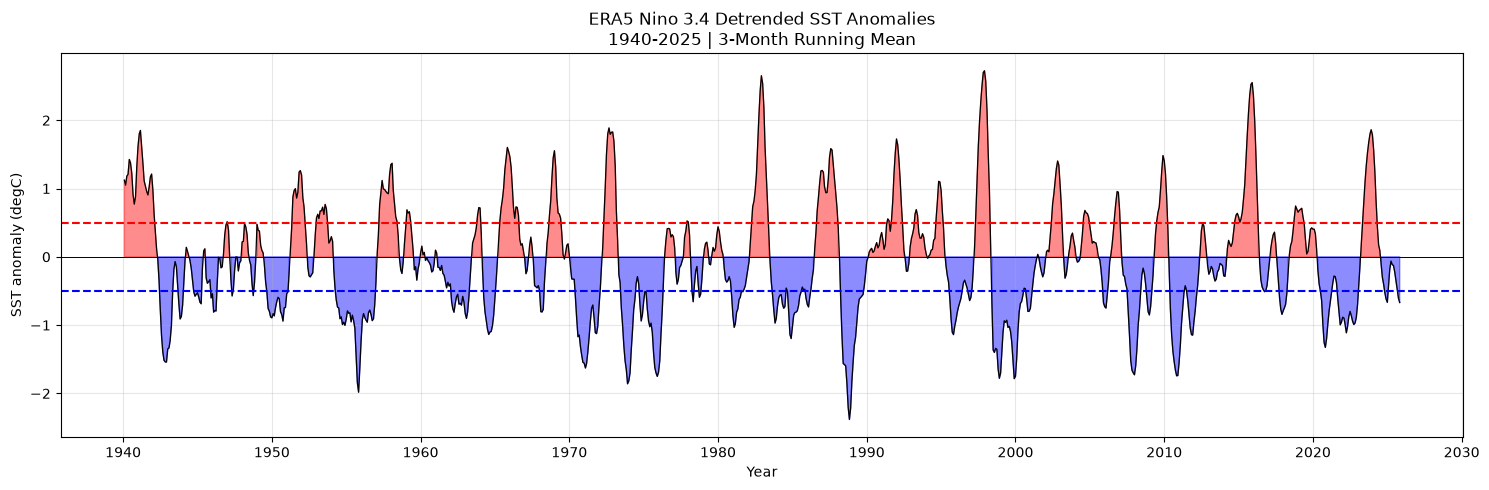


ERA5 NINO 3.4 ANALYSIS COMPLETE
Months analysed: 1032
Mean SST: 26.959 degC
SST trend: 0.014 degC/decade
Fixed anomaly standard deviation: 0.876 degC
Detrended anomaly standard deviation: 0.876 degC

NetCDF: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5\indices\era5_nino34_1940_2025.nc
CSV: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5\indices\era5_nino34_1940_2025.csv
Figures: C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_nino34


In [ ]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================================
# ERA5 NINO 3.4 INDEX
# 1940-2025 | Monthly SST
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

BASELINE_START = 1991
BASELINE_END = 2020

DATA_FILE = Path(
    "data/era5/era5_global/"
    "era5_sea_surface_temperature_1940_2025.nc"
)

OUTPUT_DIR = Path("derived_data/era5/indices")
FIG_DIR = Path("figures/era5_nino34")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. OPEN ERA5 SST
# ============================================================

print("Opening ERA5 SST dataset...")

ds = xr.open_dataset(
    DATA_FILE,
    engine="netcdf4"
)

if "valid_time" in ds.dims:
    ds = ds.rename({"valid_time": "time"})

sst = ds["sst"]

# Convert longitudes to 0-360
sst = sst.assign_coords(
    longitude=sst.longitude % 360
)

sst = sst.sortby("longitude")
sst = sst.sortby("latitude")

# Select time and Nino 3.4 region
sst = sst.sel(
    time=slice(
        f"{START_YEAR}-01-01",
        f"{END_YEAR}-12-31"
    ),
    latitude=slice(-5, 5),
    longitude=slice(190, 240)
)

assert sst.sizes["time"] == 1032
assert sst.sizes["latitude"] > 0
assert sst.sizes["longitude"] > 0

# ============================================================
# 2. CONVERT SST TO CELSIUS
# ============================================================

units = ds["sst"].attrs.get("units", "")

if units in ("K", "kelvin", "Kelvin"):
    sst = sst - 273.15
elif units in ("degC", "C", "celsius", "degrees_C"):
    pass
else:
    raise ValueError(f"Unexpected SST units: {units}")

sst.attrs["units"] = "degC"

# ============================================================
# 3. AREA-WEIGHTED MEAN SST
# ============================================================

print("Calculating area-weighted Nino 3.4 SST...")

# For a regular latitude-longitude grid,
# grid-cell area is proportional to cos(latitude).
weights = np.cos(
    np.deg2rad(sst.latitude)
)

nino34_sst = sst.weighted(weights).mean(
    dim=["latitude", "longitude"]
).compute()

nino34_sst.name = "nino34_sst"
nino34_sst.attrs["units"] = "degC"

print("Mean SST calculated.")
print("Months:", nino34_sst.sizes["time"])

# ============================================================
# 4. FIXED-BASELINE MONTHLY ANOMALIES
# ============================================================

print("Calculating monthly SST anomalies...")

baseline = nino34_sst.sel(
    time=slice(
        f"{BASELINE_START}-01-01",
        f"{BASELINE_END}-12-31"
    )
)

assert baseline.sizes["time"] == 360

monthly_climatology = baseline.groupby(
    "time.month"
).mean("time")

nino34_anomaly = (
    nino34_sst.groupby("time.month")
    - monthly_climatology
)

nino34_anomaly.name = "nino34_anomaly"
nino34_anomaly.attrs["units"] = "degC"

# ============================================================
# 5. REMOVE LINEAR BACKGROUND TREND
# ============================================================

print("Calculating detrended anomalies...")

# Decimal years for regression
years = (
    nino34_sst.time.dt.year
    + (nino34_sst.time.dt.month - 0.5) / 12
).values.astype(float)

values = nino34_anomaly.values

valid = np.isfinite(values)

slope, intercept = np.polyfit(
    years[valid],
    values[valid],
    1
)

# Centre trend at midpoint of baseline period
reference_year = (
    BASELINE_START + BASELINE_END + 1
) / 2

trend = xr.DataArray(
    slope * (years - reference_year),
    coords={"time": nino34_sst.time},
    dims=["time"]
)

nino34_detrended = nino34_anomaly - trend

nino34_detrended.name = "nino34_detrended"
nino34_detrended.attrs["units"] = "degC"

print(
    f"Linear SST trend: "
    f"{slope * 10:.4f} degC/decade"
)

# ============================================================
# 6. THREE-MONTH RUNNING MEANS
# ============================================================

nino34_fixed_3m = nino34_anomaly.rolling(
    time=3,
    center=True,
    min_periods=3
).mean()

nino34_detrended_3m = nino34_detrended.rolling(
    time=3,
    center=True,
    min_periods=3
).mean()

# ============================================================
# 7. PLOT ABSOLUTE NINO 3.4 SST
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    nino34_sst.time.values,
    nino34_sst.values,
    color="darkred",
    linewidth=0.8
)

ax.set_title(
    "ERA5 Nino 3.4 Sea Surface Temperature\n"
    "1940-2025"
)

ax.set_xlabel("Year")
ax.set_ylabel("SST (degC)")
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "nino34_absolute_sst.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. PLOT FIXED-BASELINE ANOMALIES
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

dates = pd.to_datetime(
    nino34_fixed_3m.time.values
)

values = nino34_fixed_3m.values

ax.plot(
    dates,
    values,
    color="black",
    linewidth=0.9
)

ax.fill_between(
    dates,
    values,
    0,
    where=values >= 0,
    color="red",
    alpha=0.45
)

ax.fill_between(
    dates,
    values,
    0,
    where=values < 0,
    color="blue",
    alpha=0.45
)

ax.axhline(0, color="black", linewidth=0.7)
ax.axhline(0.5, color="red", linestyle="--")
ax.axhline(-0.5, color="blue", linestyle="--")

ax.set_title(
    "ERA5 Nino 3.4 SST Anomalies\n"
    "1991-2020 Baseline | 3-Month Running Mean"
)

ax.set_ylabel("SST anomaly (degC)")
ax.set_xlabel("Year")
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "nino34_fixed_anomalies.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. PLOT DETRENDED ANOMALIES
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

dates = pd.to_datetime(
    nino34_detrended_3m.time.values
)

values = nino34_detrended_3m.values

ax.plot(
    dates,
    values,
    color="black",
    linewidth=0.9
)

ax.fill_between(
    dates,
    values,
    0,
    where=values >= 0,
    color="red",
    alpha=0.45
)

ax.fill_between(
    dates,
    values,
    0,
    where=values < 0,
    color="blue",
    alpha=0.45
)

ax.axhline(0, color="black", linewidth=0.7)
ax.axhline(0.5, color="red", linestyle="--")
ax.axhline(-0.5, color="blue", linestyle="--")

ax.set_title(
    "ERA5 Nino 3.4 Detrended SST Anomalies\n"
    "1940-2025 | 3-Month Running Mean"
)

ax.set_ylabel("SST anomaly (degC)")
ax.set_xlabel("Year")
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "nino34_detrended_anomalies.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. SAVE RESULTS
# ============================================================

results = xr.Dataset({
    "nino34_sst": nino34_sst,
    "nino34_anomaly": nino34_anomaly,
    "nino34_detrended": nino34_detrended,
    "nino34_fixed_3m": nino34_fixed_3m,
    "nino34_detrended_3m": nino34_detrended_3m
})

results.attrs["source"] = "ERA5 monthly SST"
results.attrs["region"] = "5S-5N, 170W-120W"
results.attrs["baseline"] = "1991-2020"
results.attrs["detrending"] = "Linear trend, 1940-2025"

netcdf_file = OUTPUT_DIR / "era5_nino34_1940_2025.nc"
csv_file = OUTPUT_DIR / "era5_nino34_1940_2025.csv"

results.to_netcdf(netcdf_file)
results.to_dataframe().to_csv(csv_file)

# ============================================================
# 11. SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("ERA5 NINO 3.4 ANALYSIS COMPLETE")
print("=" * 60)

print(f"Months analysed: {nino34_sst.sizes['time']}")
print(f"Mean SST: {float(nino34_sst.mean()):.3f} degC")
print(f"SST trend: {slope * 10:.3f} degC/decade")

print(
    "Fixed anomaly standard deviation:",
    f"{float(nino34_anomaly.std()):.3f} degC"
)

print(
    "Detrended anomaly standard deviation:",
    f"{float(nino34_detrended.std()):.3f} degC"
)

print("\nNetCDF:", netcdf_file.resolve())
print("CSV:", csv_file.resolve())
print("Figures:", FIG_DIR.resolve())

print("=" * 60)

ds.close()


ERA5 PCA CORRELATION WITH NINO 3.4

Niño 3.4 index loaded
Months: 1032

Opening sst...
Coarsened shape: (1032, 90, 180)

SST | Tropical Pacific
Region shape: (1032, 20, 80)
Variance explained: [49.99 10.21  5.73]
Niño correlations: [ 0.972 -0.106 -0.078]

SST | Pacific
Region shape: (1032, 65, 80)
Variance explained: [22.04  7.33  5.48]
Niño correlations: [0.934 0.203 0.093]

SST | Global
Region shape: (1032, 90, 180)
Variance explained: [12.86  7.18  3.4 ]
Niño correlations: [0.933 0.109 0.107]

Opening msl...
Coarsened shape: (1032, 90, 180)

MSLP | Tropical Pacific
Region shape: (1032, 20, 80)
Variance explained: [38.17 28.08  6.5 ]
Niño correlations: [-0.78   0.637 -0.141]

MSLP | Pacific
Region shape: (1032, 65, 80)
Variance explained: [14.76 12.59  9.58]
Niño correlations: [ 0.531 -0.058 -0.259]

MSLP | Global
Region shape: (1032, 90, 180)
Variance explained: [13.6   9.25  6.1 ]
Niño correlations: [0.122 0.17  0.54 ]

PCA vs NINO 3.4 CORRELATION SUMMARY
Variable           Region 

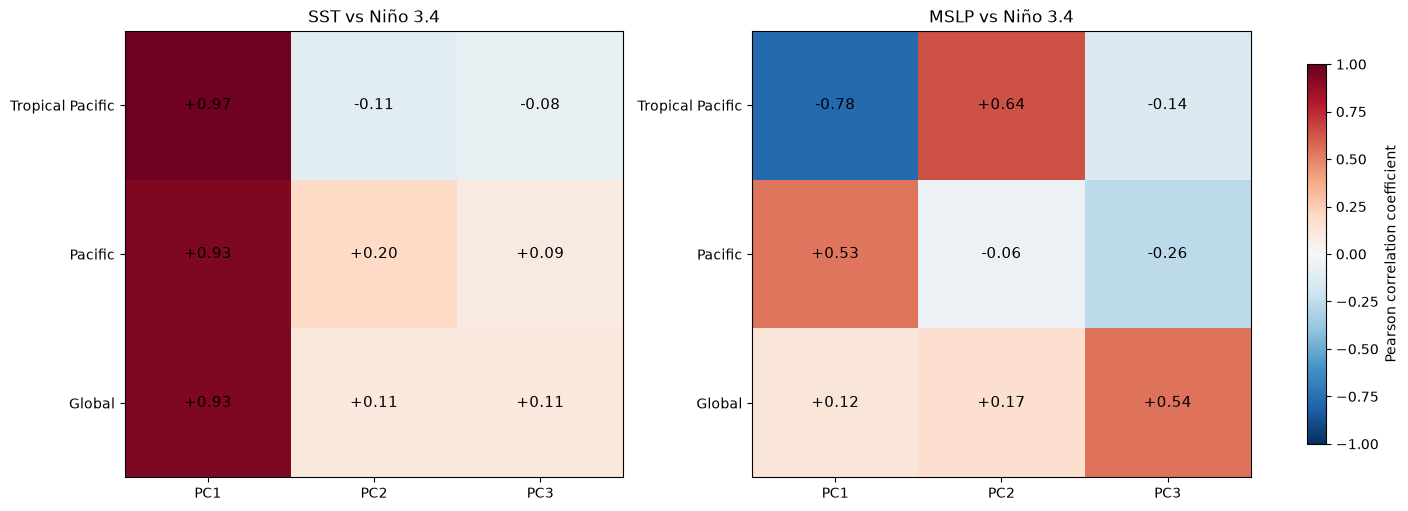

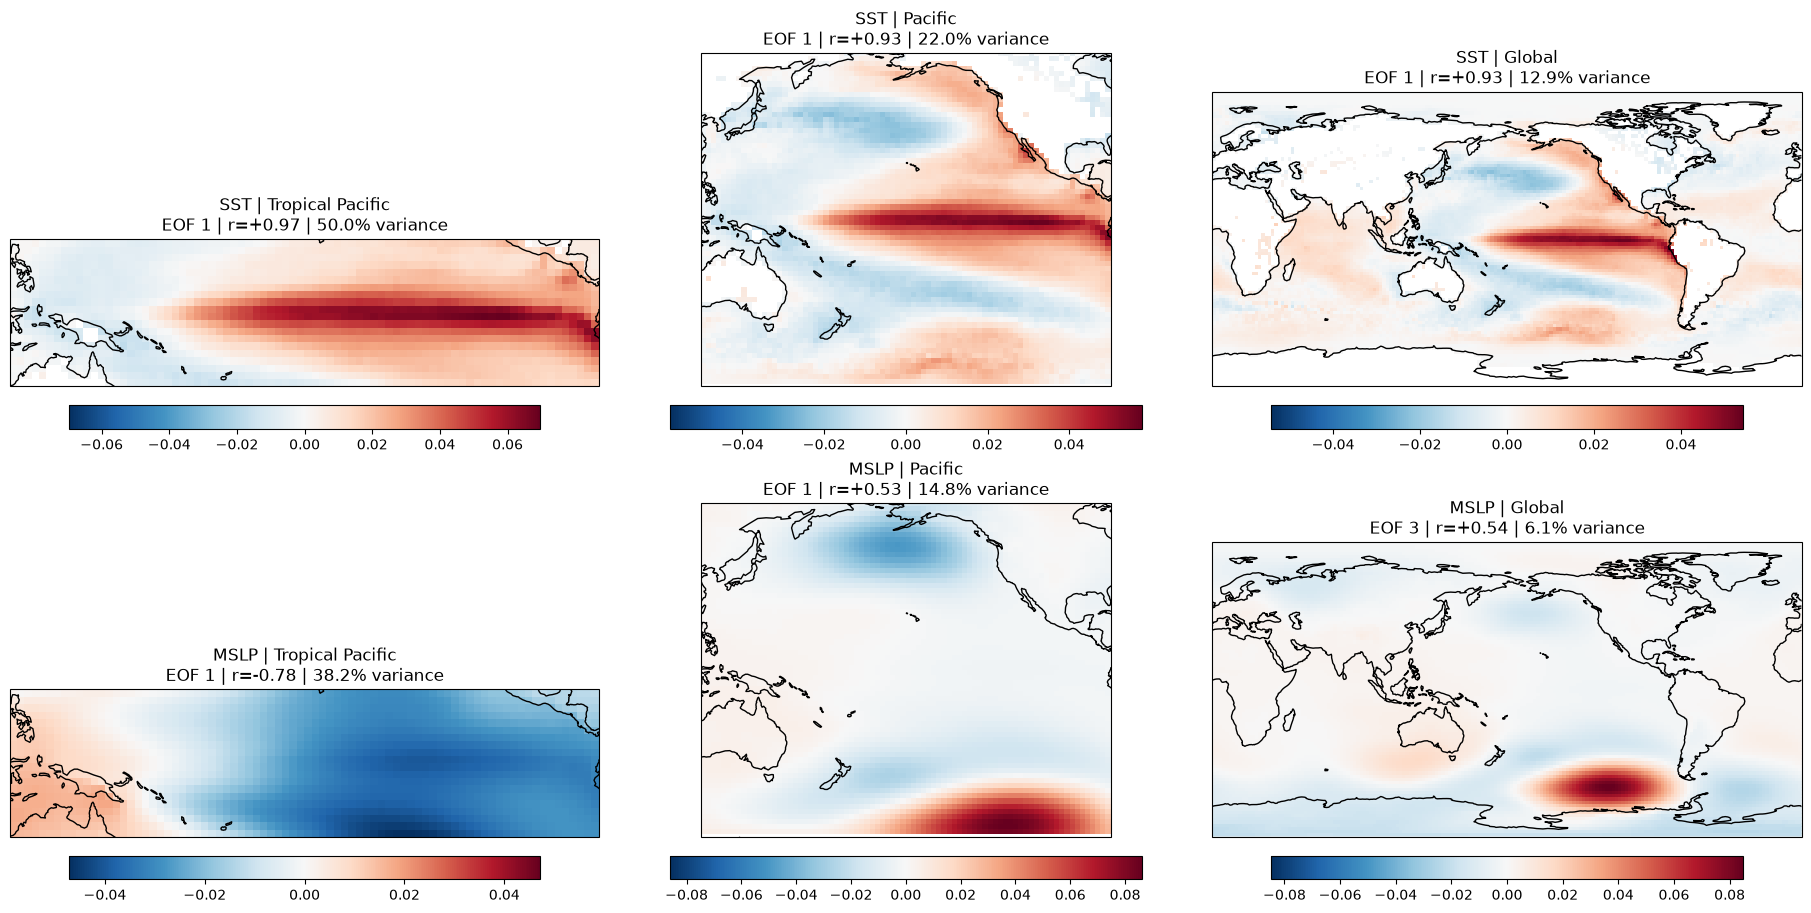

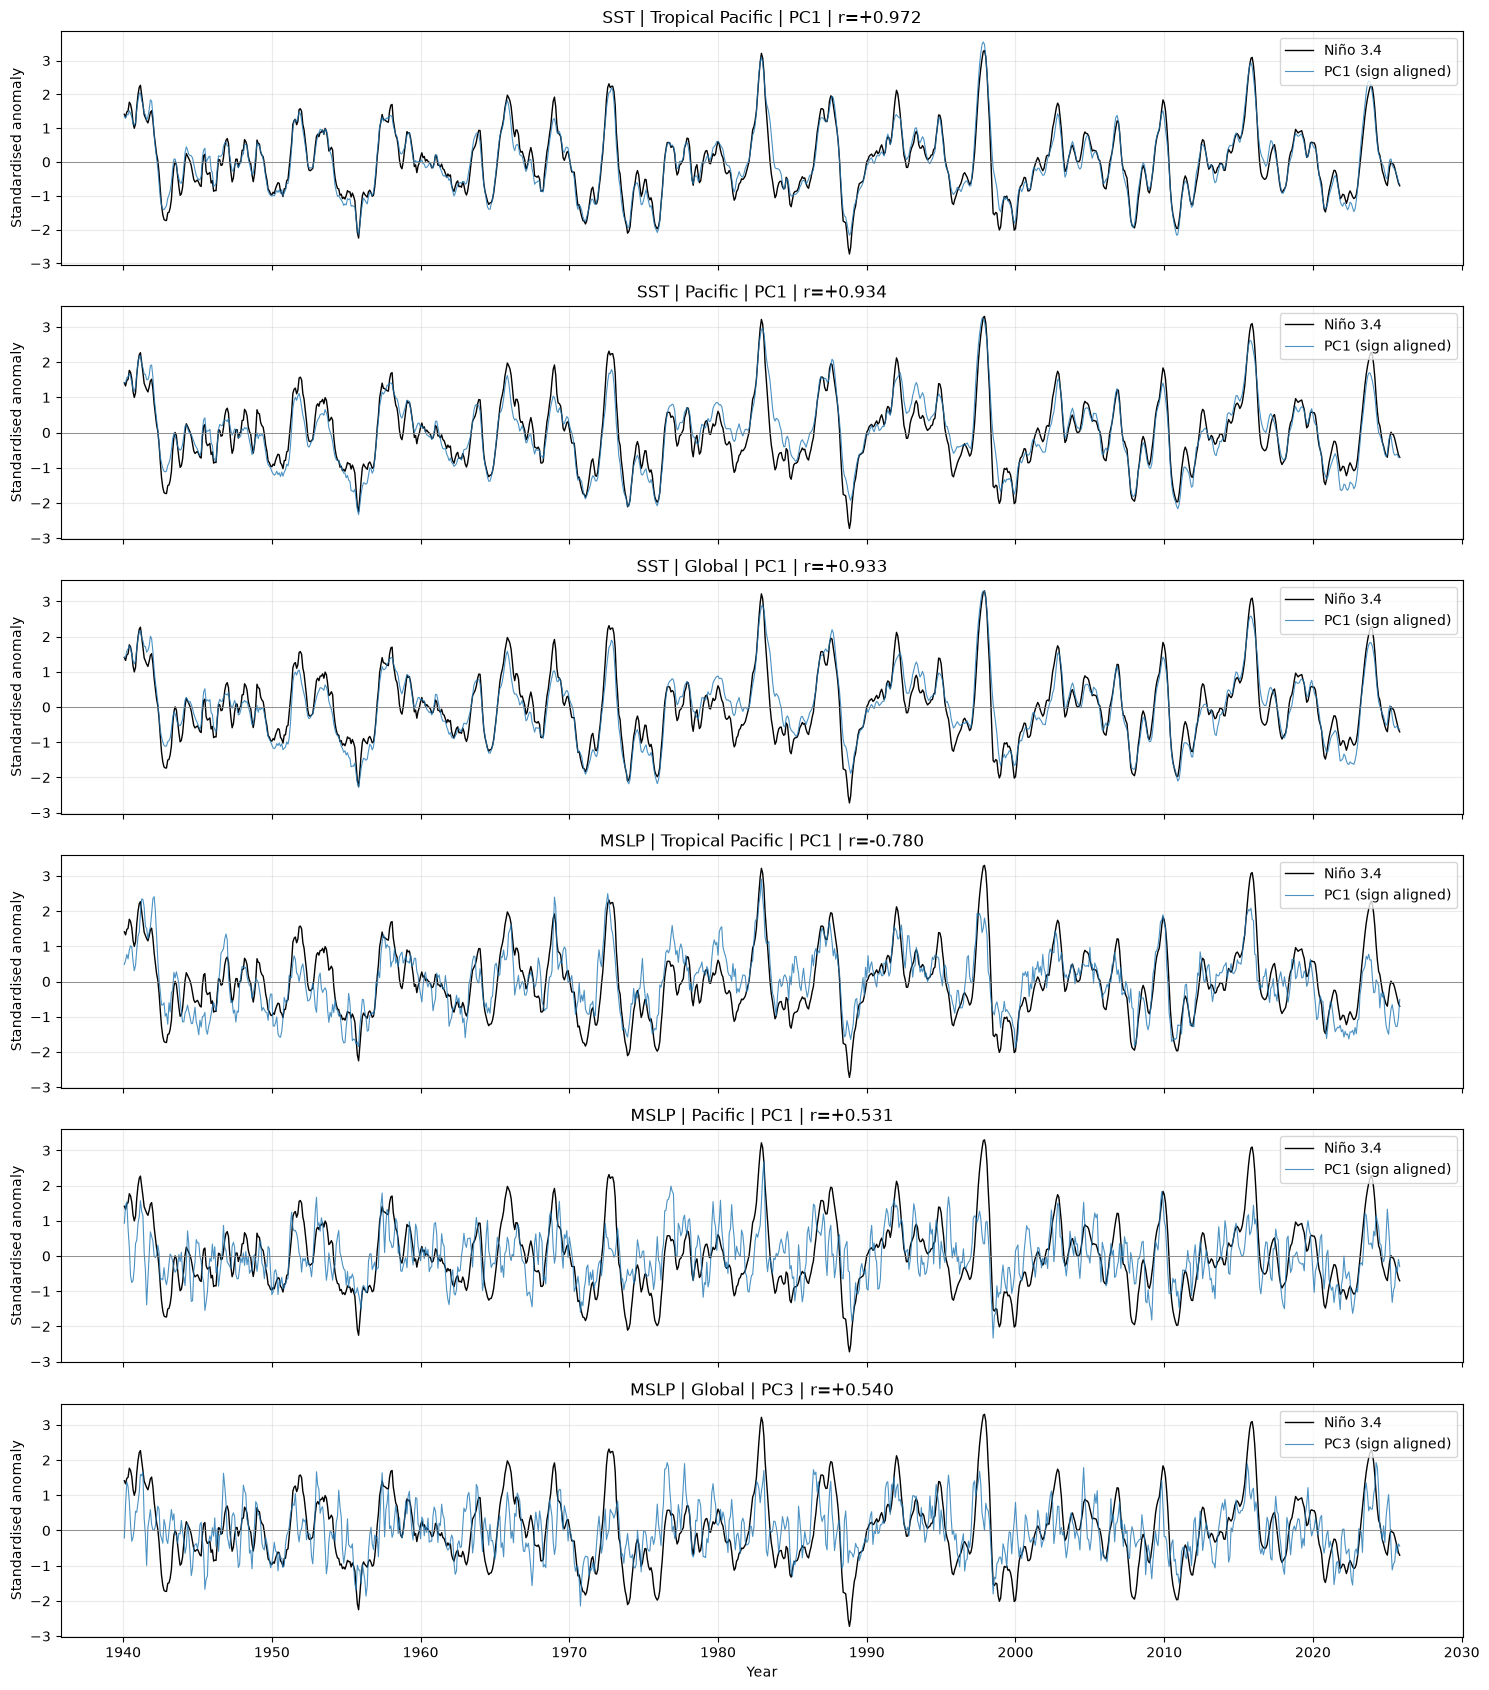


MODES MOST STRONGLY RELATED TO NINO 3.4
Variable           Region  PC  Variance (%)  Niño 3.4 r
     SST Tropical Pacific   1        49.993       0.972
     SST          Pacific   1        22.044       0.934
     SST           Global   1        12.865       0.933
    MSLP Tropical Pacific   1        38.166      -0.780
    MSLP Tropical Pacific   2        28.080       0.637
    MSLP           Global   3         6.104       0.540
    MSLP          Pacific   1        14.763       0.531
    MSLP          Pacific   3         9.583      -0.259
     SST          Pacific   2         7.328       0.203
    MSLP           Global   2         9.254       0.170
    MSLP Tropical Pacific   3         6.496      -0.141
    MSLP           Global   1        13.601       0.122
     SST           Global   2         7.175       0.109
     SST           Global   3         3.402       0.107
     SST Tropical Pacific   2        10.210      -0.106
     SST          Pacific   3         5.481       0.093
     SS

In [25]:

import gc
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from scipy.signal import detrend
from sklearn.decomposition import PCA

# ============================================================
# ERA5 EOF / PCA COMPARISON WITH NINO 3.4
# SST and MSLP | 1940-2025
# Tropical Pacific, Pacific Sector, Global
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

N_COMPONENTS = 3
COARSEN_FACTOR = 8  # 0.25 -> approximately 2 degrees

DATA_DIR = Path("data/era5/era5_global")
INDEX_DIR = Path("derived_data/era5/indices")
FIG_DIR = Path("figures/era5_enso_pca")

FIG_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "SST": DATA_DIR /
        "era5_sea_surface_temperature_1940_2025.nc",
    "MSLP": DATA_DIR /
        "era5_mean_sea_level_pressure_1940_2025.nc",
}

INDEX_FILE = (
    INDEX_DIR / "era5_nino34_1940_2025.nc"
)

# ============================================================
# 1. REGIONS
# ============================================================

REGIONS = {
    "Tropical Pacific": {
        "latitude": (-20, 20),
        "longitude": (120, 280),
    },
    "Pacific": {
        "latitude": (-65, 65),
        "longitude": (120, 280),
    },
    "Global": {
        "latitude": (-90, 90),
        "longitude": (0, 360),
    },
}

# ============================================================
# 2. LOAD NINO 3.4 INDEX
# ============================================================

print("=" * 65)
print("ERA5 PCA CORRELATION WITH NINO 3.4")
print("=" * 65)

with xr.open_dataset(INDEX_FILE) as index_ds:

    nino_index = index_ds[
        "nino34_detrended_3m"
    ].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    ).load()

# Align by calendar month rather than exact timestamp
nino_dates = pd.to_datetime(nino_index.time.values)

nino_series = pd.Series(
    nino_index.values,
    index=nino_dates.to_period("M")
)

assert not nino_series.index.has_duplicates

print("\nNiño 3.4 index loaded")
print("Months:", len(nino_series))

# ============================================================
# 3. LOAD ERA5 VARIABLE
# ============================================================

def load_variable(path, variable):

    print(f"\nOpening {variable}...")

    ds = xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    )

    if "valid_time" in ds.dims:
        ds = ds.rename({"valid_time": "time"})

    da = ds[variable].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    )

    # Convert units
    units = da.attrs.get("units", "")

    if variable == "sst":
        if units in ("K", "kelvin", "Kelvin"):
            da = da - 273.15
        elif units not in (
            "degC", "C", "celsius", "degrees_C"
        ):
            raise ValueError(
                f"Unexpected SST units: {units}"
            )

    elif variable == "msl":
        if units == "Pa":
            da = da / 100
        elif units not in ("hPa", "mbar"):
            raise ValueError(
                f"Unexpected MSLP units: {units}"
            )

    # Convert longitude to 0-360
    da = da.assign_coords(
        longitude=da.longitude % 360
    ).sortby("longitude").sortby("latitude")

    # Coarsen before loading
    da = da.coarsen(
        latitude=COARSEN_FACTOR,
        longitude=COARSEN_FACTOR,
        boundary="trim"
    ).mean()

    da = da.transpose(
        "time", "latitude", "longitude"
    )

    assert da.sizes["time"] == 1032

    print("Coarsened shape:", da.shape)

    return ds, da

# ============================================================
# 4. EOF / PCA FUNCTION
# ============================================================

def calculate_pca(data, n_components=3):

    # Remove monthly seasonal cycle
    climatology = data.groupby(
        "time.month"
    ).mean("time")

    anomalies = (
        data.groupby("time.month") - climatology
    )

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    matrix = anomalies.values.reshape(
        nt, ny * nx
    )

    # Exclude cells with missing observations
    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid].astype(
        np.float32, copy=True
    )

    if X.shape[1] < n_components:
        raise ValueError("Insufficient valid grid cells")

    # Remove linear trend at every grid cell
    X = detrend(
        X, axis=0, type="linear"
    ).astype(np.float32)

    # EOF area weighting
    lat = anomalies.latitude.values

    lat_weights = np.sqrt(
        np.clip(
            np.cos(np.deg2rad(lat)),
            0, None
        )
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None],
        (ny, nx)
    ).reshape(-1)

    weights = weights_2d[valid]

    # Exclude zero-weight cells
    positive = weights > 1e-8

    indices = np.flatnonzero(valid)[positive]

    X = X[:, positive]
    weights = weights[positive]

    X_weighted = X * weights

    # PCA using randomized SVD
    pca = PCA(
        n_components=n_components,
        svd_solver="randomized",
        random_state=42
    )

    pcs = pca.fit_transform(X_weighted)

    # Reconstruct spatial EOF patterns
    eofs_flat = np.full(
        (n_components, ny * nx),
        np.nan,
        dtype=np.float32
    )

    eofs_flat[:, indices] = (
        pca.components_ / weights
    ).astype(np.float32)

    eofs = eofs_flat.reshape(
        n_components, ny, nx
    )

    explained = (
        pca.explained_variance_ratio_ * 100
    )

    return pcs, eofs, explained

# ============================================================
# 5. COMPARE PCs WITH NINO INDEX
# ============================================================

def compare_with_nino(pcs, dates):

    # Standardise each PC
    pcs_std = (
        pcs - pcs.mean(axis=0)
    ) / pcs.std(axis=0, ddof=1)

    # Apply the same 3-month smoothing as Niño 3.4
    pcs_smooth = pd.DataFrame(
        pcs_std,
        index=pd.to_datetime(dates).to_period("M")
    ).rolling(
        window=3,
        center=True,
        min_periods=3
    ).mean()

    # Align by month
    common = pcs_smooth.index.intersection(
        nino_series.index
    )

    nino = nino_series.loc[common].to_numpy()

    correlations = []

    for i in range(N_COMPONENTS):

        pc = pcs_smooth.loc[common, i].to_numpy()

        valid = (
            np.isfinite(pc) &
            np.isfinite(nino)
        )

        r = np.corrcoef(
            pc[valid], nino[valid]
        )[0, 1]

        correlations.append(r)

    return np.array(correlations), pcs_smooth

# ============================================================
# 6. RUN SIX PCA ANALYSES
# ============================================================

results = {}
summary = []

for field, variable in [
    ("SST", "sst"),
    ("MSLP", "msl")
]:

    ds, global_data = load_variable(
        FILES[field], variable
    )

    for region_name, bounds in REGIONS.items():

        print("\n" + "=" * 60)
        print(f"{field} | {region_name}")
        print("=" * 60)

        lat_min, lat_max = bounds["latitude"]
        lon_min, lon_max = bounds["longitude"]

        region = global_data.sel(
            latitude=slice(lat_min, lat_max)
        )

        if region_name != "Global":
            region = region.sel(
                longitude=slice(lon_min, lon_max)
            )

        # Load one region at a time
        region = region.compute()

        print("Region shape:", region.shape)

        pcs, eofs, explained = calculate_pca(
            region, N_COMPONENTS
        )

        correlations, pcs_smooth = compare_with_nino(
            pcs, region.time.values
        )

        key = (field, region_name)

        results[key] = {
            "pcs": pcs,
            "pcs_smooth": pcs_smooth,
            "eofs": eofs,
            "explained": explained,
            "correlations": correlations,
            "latitude": region.latitude.values,
            "longitude": region.longitude.values,
        }

        for i in range(N_COMPONENTS):
            summary.append({
                "Variable": field,
                "Region": region_name,
                "PC": i + 1,
                "Variance (%)": explained[i],
                "Niño 3.4 r": correlations[i],
                "Absolute r": abs(correlations[i])
            })

        print("Variance explained:", explained.round(2))
        print("Niño correlations:", correlations.round(3))

        del region
        gc.collect()

    ds.close()
    del global_data
    gc.collect()

# ============================================================
# 7. SUMMARY TABLE
# ============================================================

summary_df = pd.DataFrame(summary)

print("\n" + "=" * 65)
print("PCA vs NINO 3.4 CORRELATION SUMMARY")
print("=" * 65)

print(
    summary_df[
        ["Variable", "Region", "PC",
         "Variance (%)", "Niño 3.4 r"]
    ].round(3).to_string(index=False)
)

summary_df.to_csv(
    FIG_DIR / "pca_nino34_correlations.csv",
    index=False
)

# ============================================================
# 8. CORRELATION HEATMAP
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

region_names = list(REGIONS)

for ax, field in zip(axes, ["SST", "MSLP"]):

    matrix = np.array([
        results[(field, region)]["correlations"]
        for region in region_names
    ])

    im = ax.imshow(
        matrix,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        aspect="auto"
    )

    ax.set_xticks(range(N_COMPONENTS))
    ax.set_xticklabels(
        [f"PC{i+1}" for i in range(N_COMPONENTS)]
    )

    ax.set_yticks(range(len(region_names)))
    ax.set_yticklabels(region_names)

    for i in range(len(region_names)):
        for j in range(N_COMPONENTS):
            value = matrix[i, j]

            ax.text(
                j, i,
                f"{value:+.2f}",
                ha="center",
                va="center",
                fontsize=11
            )

    ax.set_title(f"{field} vs Niño 3.4")

fig.colorbar(
    im,
    ax=axes,
    label="Pearson correlation coefficient",
    shrink=0.85
)

plt.savefig(
    FIG_DIR / "nino34_pca_correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. PLOT MOST CORRELATED EOF FOR EACH ANALYSIS
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 9),
    subplot_kw={
        "projection": ccrs.PlateCarree(
            central_longitude=180
        )
    },
    constrained_layout=True
)

for row, field in enumerate(["SST", "MSLP"]):

    for col, region_name in enumerate(region_names):

        ax = axes[row, col]

        result = results[(field, region_name)]

        correlations = result["correlations"]

        best_pc = np.argmax(
            np.abs(correlations)
        )

        r = correlations[best_pc]

        # Orient EOF so positive corresponds
        # to positive Niño 3.4 anomalies
        pattern = (
            result["eofs"][best_pc] * np.sign(r)
        )

        vmax = np.nanmax(np.abs(pattern))

        im = ax.pcolormesh(
            result["longitude"],
            result["latitude"],
            pattern,
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-vmax,
            vmax=vmax,
            shading="auto"
        )

        ax.coastlines(resolution="110m")

        if region_name == "Global":
            ax.set_global()
        else:
            bounds = REGIONS[region_name]
            ax.set_extent(
                [
                    *bounds["longitude"],
                    *bounds["latitude"]
                ],
                crs=ccrs.PlateCarree()
            )

        ax.set_title(
            f"{field} | {region_name}\n"
            f"EOF {best_pc+1} | "
            f"r={r:+.2f} | "
            f"{result['explained'][best_pc]:.1f}% variance"
        )

        fig.colorbar(
            im,
            ax=ax,
            orientation="horizontal",
            shrink=0.8,
            pad=0.05
        )

plt.savefig(
    FIG_DIR / "nino34_related_eof_maps.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. COMPARE MOST CORRELATED PCs WITH NINO 3.4
# ============================================================

fig, axes = plt.subplots(
    6, 1,
    figsize=(15, 17),
    sharex=True
)

plot_index = 0

for field in ["SST", "MSLP"]:

    for region_name in region_names:

        ax = axes[plot_index]
        result = results[(field, region_name)]

        best_pc = np.argmax(
            np.abs(result["correlations"])
        )

        r = result["correlations"][best_pc]

        pc_series = (
            result["pcs_smooth"][best_pc] *
            np.sign(r)
        )

        common = pc_series.index.intersection(
            nino_series.index
        )

        dates = common.to_timestamp()

        # Standardise Niño index for comparison
        nino = nino_series.loc[common]
        nino_std = (
            nino - nino.mean()
        ) / nino.std()

        ax.plot(
            dates,
            nino_std,
            color="black",
            linewidth=1,
            label="Niño 3.4"
        )

        ax.plot(
            dates,
            pc_series.loc[common],
            linewidth=0.8,
            alpha=0.8,
            label=f"PC{best_pc+1} (sign aligned)"
        )

        ax.axhline(0, color="grey", linewidth=0.6)

        ax.set_title(
            f"{field} | {region_name} | "
            f"PC{best_pc+1} | r={r:+.3f}"
        )

        ax.set_ylabel("Standardised anomaly")
        ax.legend(loc="upper right")
        ax.grid(alpha=0.25)

        plot_index += 1

axes[-1].set_xlabel("Year")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "nino34_pc_timeseries_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. RANK MODES BY CORRELATION
# ============================================================

ranked = summary_df.sort_values(
    "Absolute r",
    ascending=False
)

print("\n" + "=" * 65)
print("MODES MOST STRONGLY RELATED TO NINO 3.4")
print("=" * 65)

print(
    ranked[
        ["Variable", "Region", "PC",
         "Variance (%)", "Niño 3.4 r"]
    ].round(3).to_string(index=False)
)

print("\nFigures saved to:")
print(FIG_DIR.resolve())

print("=" * 65)



Loading sst...
Shape: (1032, 20, 80)

Loading msl...
Shape: (1032, 20, 80)

SST DECADAL EOF ANALYSIS

Processing SST 1940-1949 (120 months)
Variance explained: [42.59 11.3   5.71]
Niño correlations: [ 0.905 -0.067 -0.048]

Processing SST 1950-1959 (120 months)
Variance explained: [57.38  7.51  3.39]
Niño correlations: [ 0.979  0.012 -0.102]

Processing SST 1960-1969 (120 months)
Variance explained: [45.02 11.46  6.59]
Niño correlations: [ 0.9   -0.187 -0.073]

Processing SST 1970-1979 (120 months)
Variance explained: [61.83 10.55  5.92]
Niño correlations: [0.965 0.035 0.122]

Processing SST 1980-1989 (120 months)
Variance explained: [58.85 10.55  4.12]
Niño correlations: [ 0.95  -0.231  0.033]

Processing SST 1990-1999 (120 months)
Variance explained: [60.3   8.03  4.78]
Niño correlations: [ 0.907 -0.202  0.144]

Processing SST 2000-2009 (120 months)
Variance explained: [47.08 13.95  4.36]
Niño correlations: [ 0.987 -0.031 -0.034]

Processing SST 2010-2019 (120 months)
Variance explai

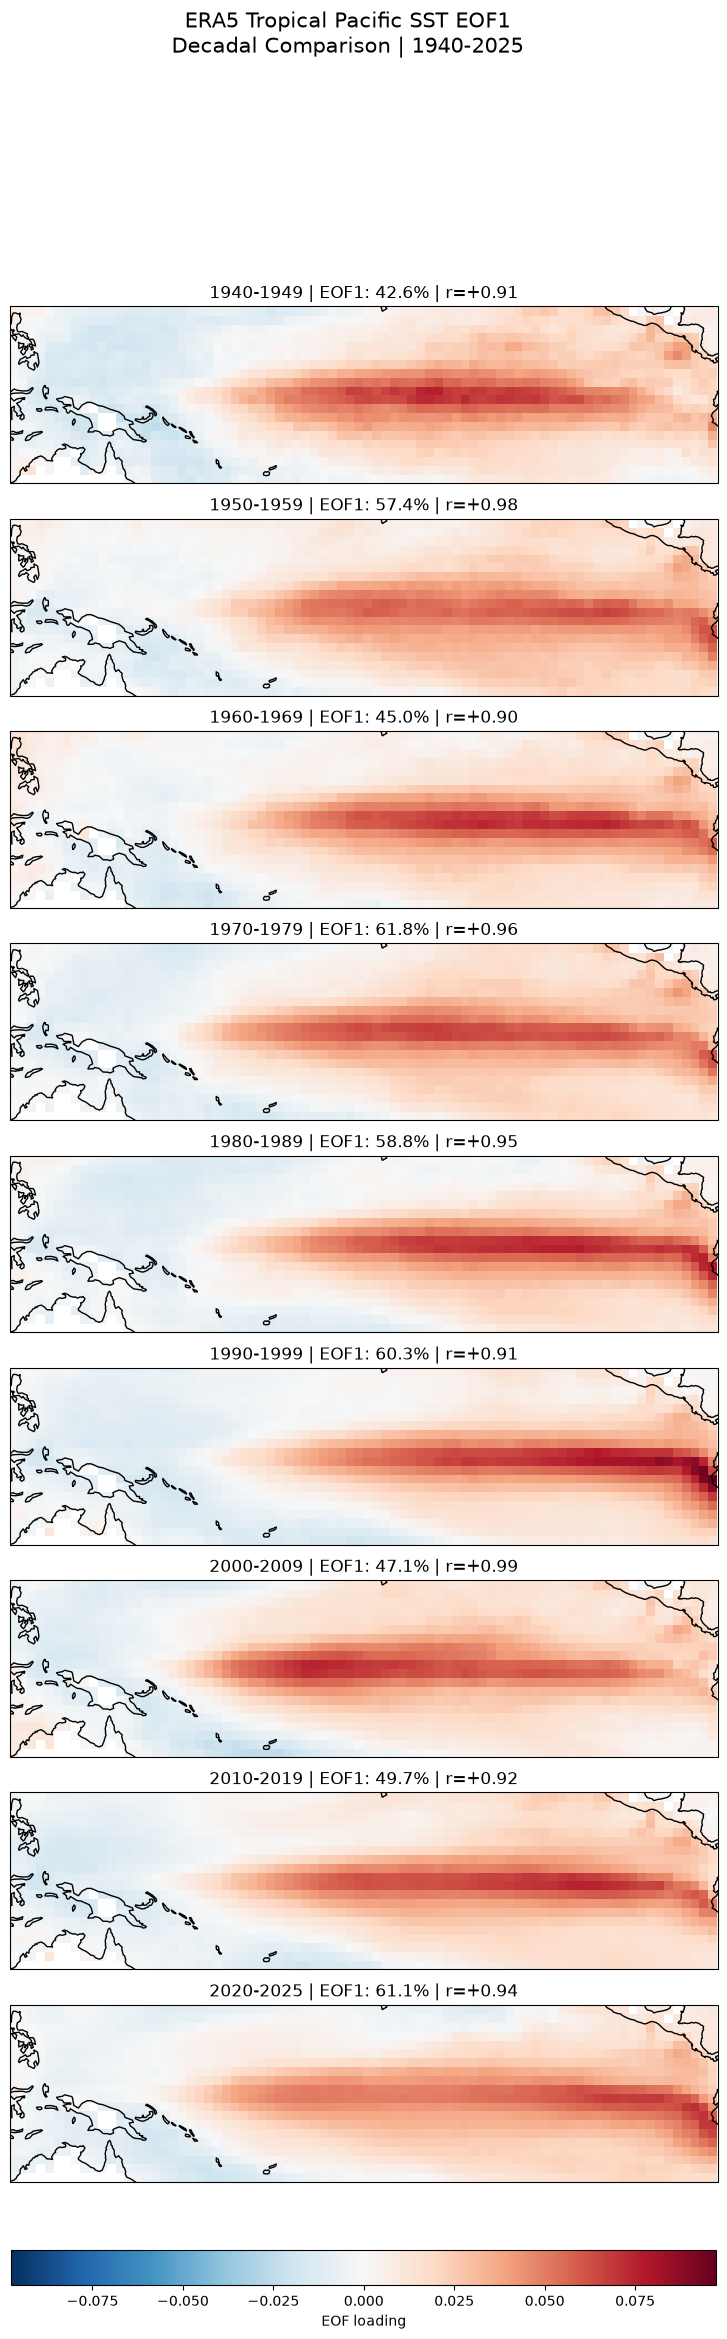

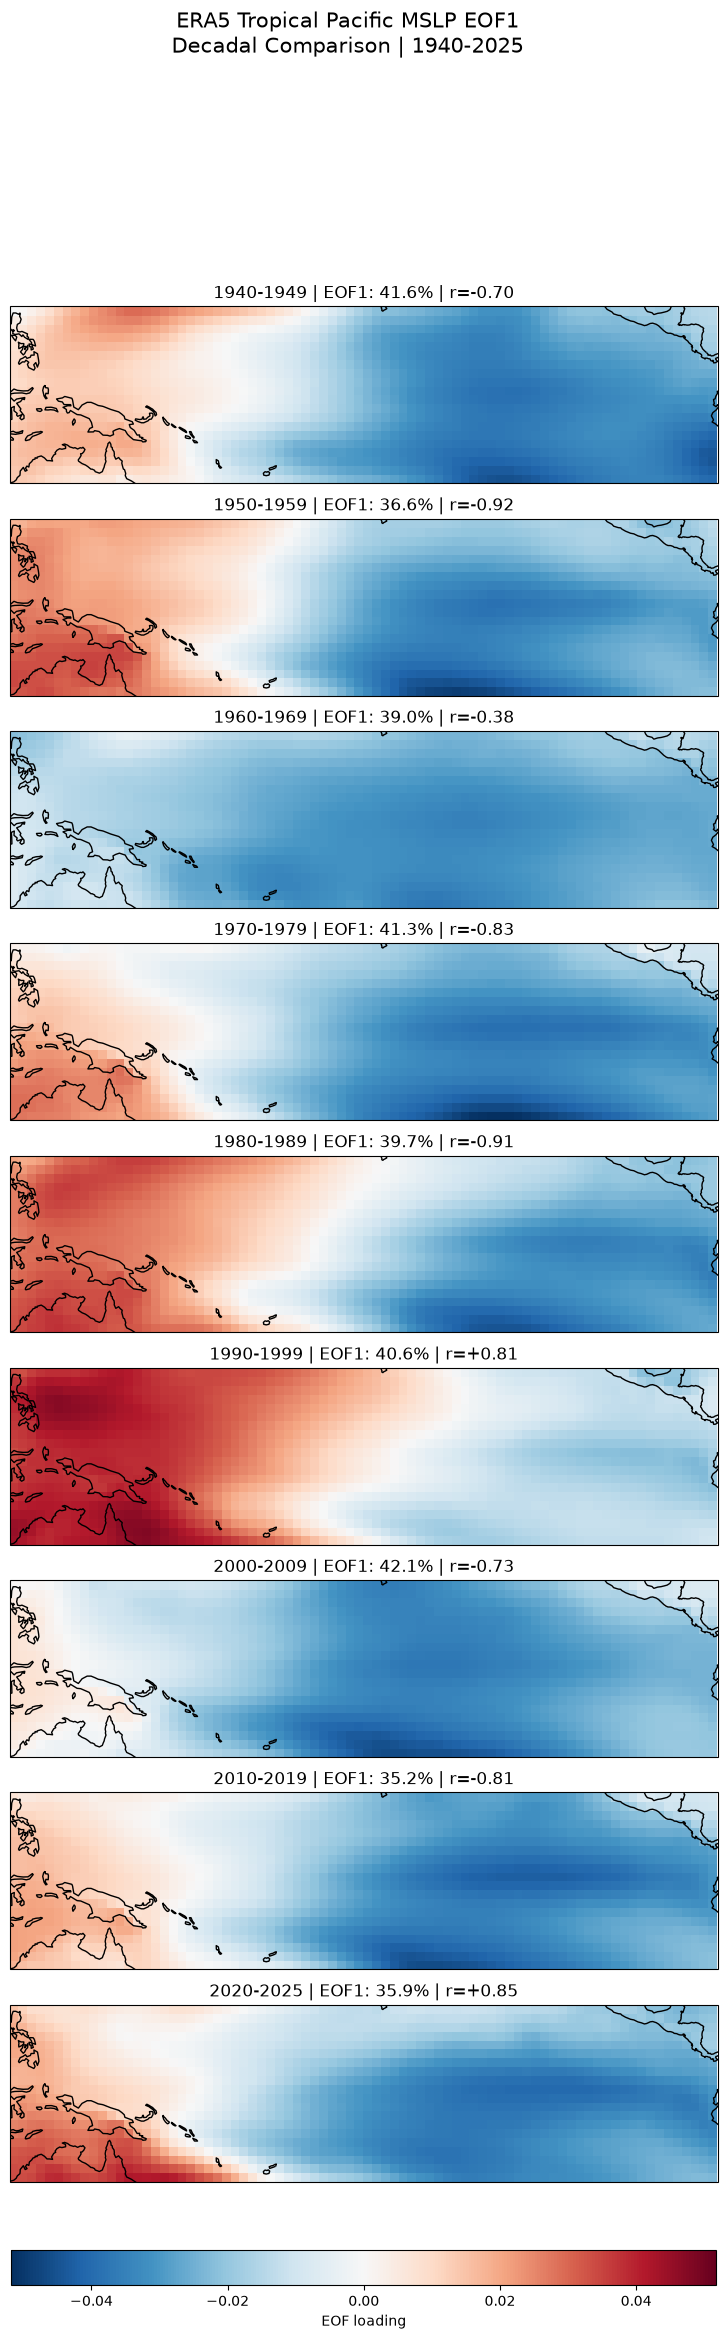

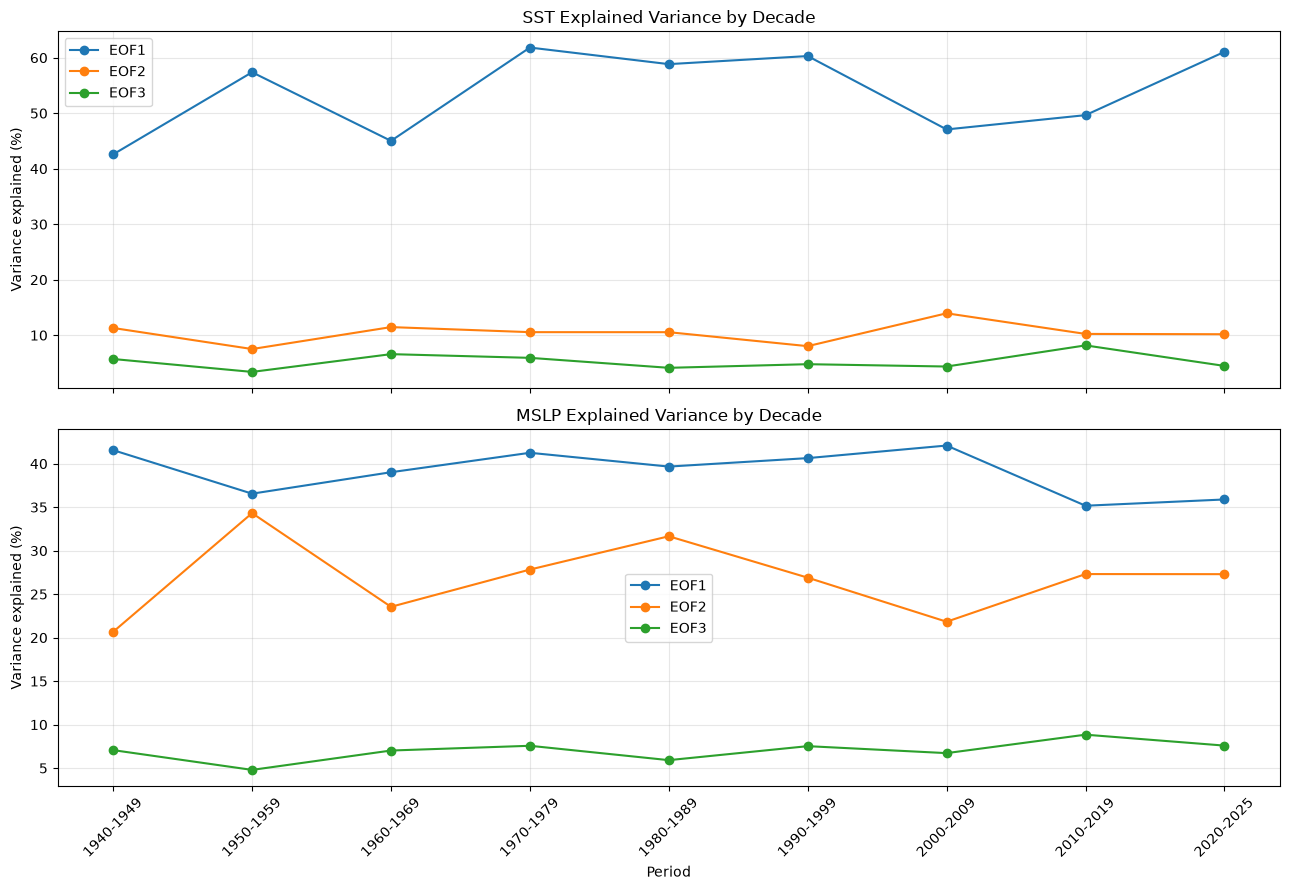

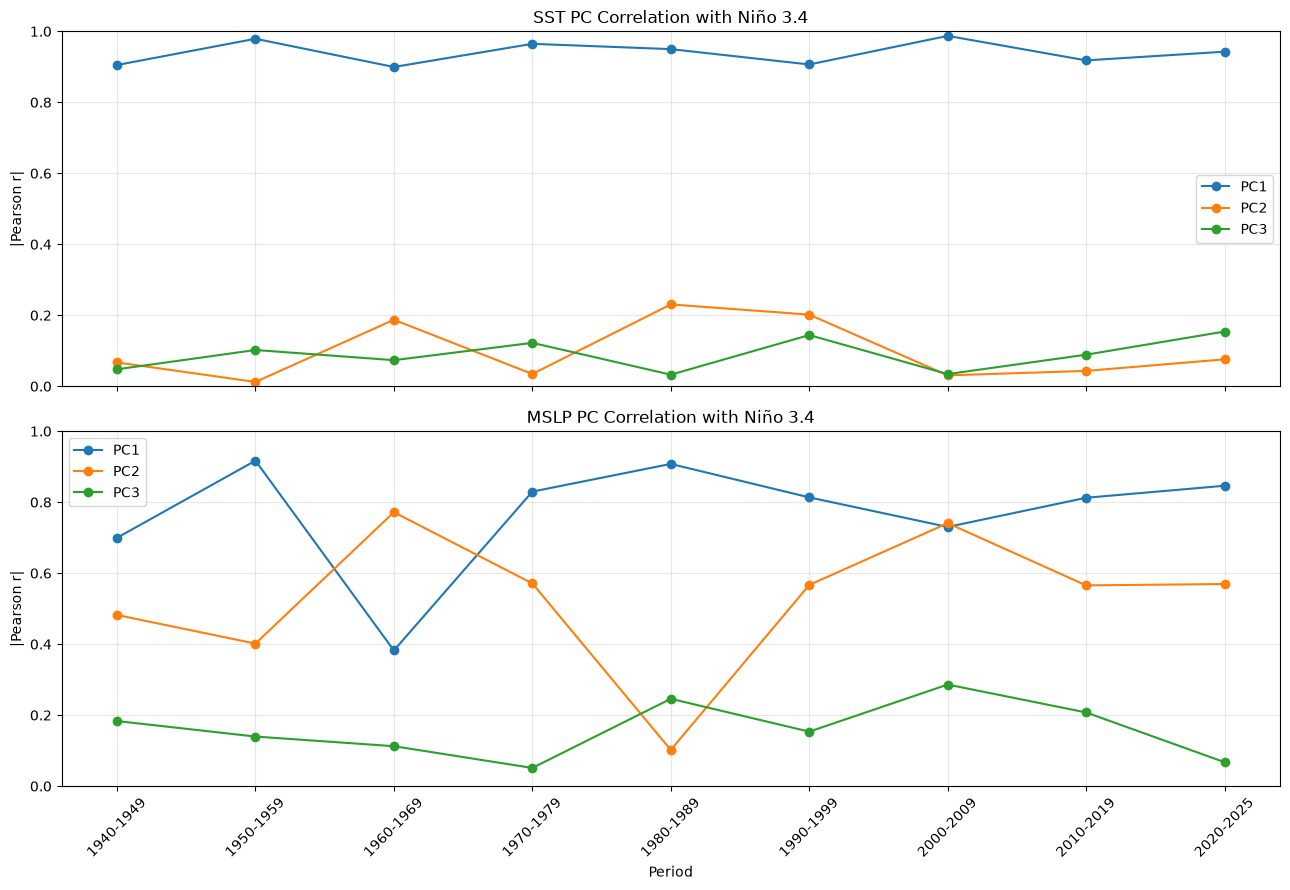


STRONGEST NINO 3.4-RELATED EOF BY DECADE
Variable    Period  Best EOF  Variance (%)  Nino34 r
     SST 1940-1949         1        42.588     0.905
     SST 1950-1959         1        57.383     0.979
     SST 1960-1969         1        45.019     0.900
     SST 1970-1979         1        61.833     0.965
     SST 1980-1989         1        58.845     0.950
     SST 1990-1999         1        60.300     0.907
     SST 2000-2009         1        47.078     0.987
     SST 2010-2019         1        49.654     0.918
     SST 2020-2025         1        61.061     0.943
    MSLP 1940-1949         1        41.556    -0.700
    MSLP 1950-1959         1        36.553    -0.917
    MSLP 1960-1969         2        23.545     0.772
    MSLP 1970-1979         1        41.254    -0.830
    MSLP 1980-1989         1        39.669    -0.908
    MSLP 1990-1999         1        40.642     0.814
    MSLP 2000-2009         2        21.831     0.741
    MSLP 2010-2019         1        35.167    -0.812
    

In [27]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from sklearn.decomposition import PCA
from scipy.signal import detrend

# ============================================================
# ERA5 DECADAL EOF ANALYSIS
# Tropical Pacific SST and MSLP | 1940-2025
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

N_COMPONENTS = 3
COARSEN_FACTOR = 8

LAT_MIN, LAT_MAX = -20, 20
LON_MIN, LON_MAX = 120, 280

DATA_DIR = Path("data/era5/era5_global")
INDEX_DIR = Path("derived_data/era5/indices")
FIG_DIR = Path("figures/era5_decadal_eofs")

FIG_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "SST": DATA_DIR /
        "era5_sea_surface_temperature_1940_2025.nc",
    "MSLP": DATA_DIR /
        "era5_mean_sea_level_pressure_1940_2025.nc",
}

INDEX_FILE = INDEX_DIR / "era5_nino34_1940_2025.nc"

PERIODS = [
    (start, min(start + 9, END_YEAR))
    for start in range(START_YEAR, END_YEAR + 1, 10)
]

# ============================================================
# 1. LOAD TROPICAL PACIFIC DATA
# ============================================================

def load_field(path, variable):

    print(f"\nLoading {variable}...")

    with xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    ) as ds:

        if "valid_time" in ds.dims:
            ds = ds.rename({"valid_time": "time"})

        da = ds[variable]

        # Select time and standardise coordinates
        da = da.sel(
            time=slice(
                f"{START_YEAR}-01-01",
                f"{END_YEAR}-12-31"
            )
        )

        da = da.assign_coords(
            longitude=da.longitude % 360
        ).sortby("longitude").sortby("latitude")

        da = da.sel(
            latitude=slice(LAT_MIN, LAT_MAX),
            longitude=slice(LON_MIN, LON_MAX)
        )

        # Coarsen before loading
        da = da.coarsen(
            latitude=COARSEN_FACTOR,
            longitude=COARSEN_FACTOR,
            boundary="trim"
        ).mean()

        # Convert units
        units = da.attrs.get("units", "")

        if variable == "sst":
            if units in ("K", "kelvin", "Kelvin"):
                da = da - 273.15
            elif units not in (
                "degC", "C", "celsius", "degrees_C"
            ):
                raise ValueError(
                    f"Unexpected SST units: {units}"
                )

        elif variable == "msl":
            if units == "Pa":
                da = da / 100.0
            elif units not in ("hPa", "mbar"):
                raise ValueError(
                    f"Unexpected MSLP units: {units}"
                )

        da = da.transpose(
            "time", "latitude", "longitude"
        ).compute()

    print("Shape:", da.shape)
    return da


sst = load_field(FILES["SST"], "sst")
mslp = load_field(FILES["MSLP"], "msl")

# Ensure monthly timestamps align
sst_months = pd.to_datetime(
    sst.time.values
).to_period("M")

mslp_months = pd.to_datetime(
    mslp.time.values
).to_period("M")

assert sst_months.equals(mslp_months), (
    "SST and MSLP monthly coverage does not match"
)

# ============================================================
# 2. CALCULATE FULL-PERIOD MONTHLY ANOMALIES
# ============================================================

def monthly_anomalies(da):

    climatology = da.groupby(
        "time.month"
    ).mean("time")

    return da.groupby("time.month") - climatology


sst_anom = monthly_anomalies(sst)
mslp_anom = monthly_anomalies(mslp)

# ============================================================
# 3. LOAD NINO 3.4 INDEX
# ============================================================

with xr.open_dataset(INDEX_FILE) as ds_index:

    nino = ds_index[
        "nino34_detrended_3m"
    ].load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(
        nino.time.values
    ).to_period("M")
)

assert not nino_series.index.has_duplicates

# ============================================================
# 4. EOF / PCA FUNCTION
# ============================================================

def decadal_pca(data, n_components=3):

    nt = data.sizes["time"]
    ny = data.sizes["latitude"]
    nx = data.sizes["longitude"]

    matrix = data.values.reshape(
        nt, ny * nx
    )

    # Retain cells valid throughout this period
    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid].astype(np.float64)

    if X.shape[1] < n_components:
        raise ValueError("Too few valid grid cells")

    # Remove linear trend within the decade
    X = detrend(
        X, axis=0, type="linear"
    )

    # Square-root area weighting
    lat = data.latitude.values

    lat_weights = np.sqrt(
        np.clip(
            np.cos(np.deg2rad(lat)),
            0, None
        )
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None],
        (ny, nx)
    ).reshape(-1)

    weights = weights_2d[valid]

    X_weighted = X * weights

    # Fit PCA independently for each decade
    pca = PCA(
        n_components=n_components,
        svd_solver="full"
    )

    pcs = pca.fit_transform(X_weighted)

    # Recover physical-space EOF maps
    eofs_flat = np.full(
        (n_components, ny * nx),
        np.nan
    )

    eofs_flat[:, valid] = (
        pca.components_ / weights
    )

    eofs = eofs_flat.reshape(
        n_components, ny, nx
    )

    explained = (
        pca.explained_variance_ratio_ * 100
    )

    return pcs, eofs, explained

# ============================================================
# 5. RUN PCA FOR EACH DECADE
# ============================================================

results = {}
summary = []

for field_name, anomalies in [
    ("SST", sst_anom),
    ("MSLP", mslp_anom)
]:

    print(f"\n{'=' * 60}")
    print(f"{field_name} DECADAL EOF ANALYSIS")
    print(f"{'=' * 60}")

    for start, end in PERIODS:

        period_name = f"{start}-{end}"

        subset = anomalies.sel(
            time=slice(
                f"{start}-01-01",
                f"{end}-12-31"
            )
        )

        print(
            f"\nProcessing {field_name} {period_name} "
            f"({subset.sizes['time']} months)"
        )

        pcs, eofs, explained = decadal_pca(
            subset,
            N_COMPONENTS
        )

        # Compare PCs with Niño 3.4
        pc_months = pd.to_datetime(
            subset.time.values
        ).to_period("M")

        # Standardise PCs
        pcs_std = (
            pcs - pcs.mean(axis=0)
        ) / pcs.std(axis=0, ddof=1)

        pc_df = pd.DataFrame(
            pcs_std,
            index=pc_months,
            columns=[
                f"PC{i+1}"
                for i in range(N_COMPONENTS)
            ]
        )

        # Three-month smoothing for comparison
        pc_smooth = pc_df.rolling(
            3,
            center=True,
            min_periods=3
        ).mean()

        common = pc_smooth.index.intersection(
            nino_series.index
        )

        correlations = []

        for i in range(N_COMPONENTS):

            pc = pc_smooth.loc[
                common, f"PC{i+1}"
            ].values

            nino_values = nino_series.loc[
                common
            ].values

            valid = (
                np.isfinite(pc) &
                np.isfinite(nino_values)
            )

            r = np.corrcoef(
                pc[valid],
                nino_values[valid]
            )[0, 1]

            correlations.append(r)

        correlations = np.array(correlations)

        results[(field_name, period_name)] = {
            "pcs": pcs,
            "eofs": eofs,
            "explained": explained,
            "correlations": correlations,
            "time": subset.time.values,
            "latitude": subset.latitude.values,
            "longitude": subset.longitude.values,
        }

        for i in range(N_COMPONENTS):
            summary.append({
                "Variable": field_name,
                "Period": period_name,
                "PC": i + 1,
                "Variance (%)": explained[i],
                "Nino34 r": correlations[i],
                "Absolute r": abs(correlations[i]),
            })

        print(
            "Variance explained:",
            explained.round(2)
        )

        print(
            "Niño correlations:",
            correlations.round(3)
        )

# ============================================================
# 6. SAVE SUMMARY TABLE
# ============================================================

summary_df = pd.DataFrame(summary)

summary_file = (
    FIG_DIR / "decadal_eof_summary.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)

print("\nDecadal summary:")
print(summary_df.round(3).to_string(index=False))

# ============================================================
# 7. PLOT EOF1 FOR EACH DECADE
# ============================================================

def plot_decadal_eofs(field_name):

    n_periods = len(PERIODS)

    fig, axes = plt.subplots(
        n_periods, 1,
        figsize=(13, 3.3 * n_periods),
        subplot_kw={
            "projection": ccrs.PlateCarree(
                central_longitude=180
            )
        }
    )

    axes = np.atleast_1d(axes)

    # Common scale across decades
    patterns = [
        results[
            (field_name, f"{s}-{e}")
        ]["eofs"][0]
        for s, e in PERIODS
    ]

    vmax = max(
        np.nanmax(np.abs(p))
        for p in patterns
    )

    for ax, (start, end) in zip(axes, PERIODS):

        period_name = f"{start}-{end}"

        result = results[
            (field_name, period_name)
        ]

        pattern = result["eofs"][0]

        # Align EOF sign using correlation with Niño
        r = result["correlations"][0]

        if np.isfinite(r) and r < 0:
            pattern = -pattern

        im = ax.pcolormesh(
            result["longitude"],
            result["latitude"],
            pattern,
            transform=ccrs.PlateCarree(),
            cmap="RdBu_r",
            vmin=-vmax,
            vmax=vmax,
            shading="auto"
        )

        ax.coastlines(resolution="110m")

        ax.set_extent(
            [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
            crs=ccrs.PlateCarree()
        )

        ax.set_title(
            f"{period_name} | "
            f"EOF1: {result['explained'][0]:.1f}% "
            f"| r={r:+.2f}"
        )

    fig.colorbar(
        im,
        ax=axes,
        orientation="horizontal",
        shrink=0.7,
        pad=0.03,
        label="EOF loading"
    )

    fig.suptitle(
        f"ERA5 Tropical Pacific {field_name} EOF1\n"
        "Decadal Comparison | 1940-2025",
        fontsize=15
    )

    plt.savefig(
        FIG_DIR / f"{field_name.lower()}_decadal_eof1.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


plot_decadal_eofs("SST")
plot_decadal_eofs("MSLP")

# ============================================================
# 8. PLOT EXPLAINED VARIANCE BY DECADE
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

period_labels = [
    f"{s}-{e}"
    for s, e in PERIODS
]

for ax, field_name in zip(
    axes, ["SST", "MSLP"]
):

    for component in range(N_COMPONENTS):

        values = [
            results[
                (field_name, period)
            ]["explained"][component]
            for period in period_labels
        ]

        ax.plot(
            period_labels,
            values,
            marker="o",
            label=f"EOF{component+1}"
        )

    ax.set_title(
        f"{field_name} Explained Variance by Decade"
    )

    ax.set_ylabel("Variance explained (%)")
    ax.legend()
    ax.grid(alpha=0.3)

    ax.tick_params(
        axis="x",
        rotation=45
    )

axes[-1].set_xlabel("Period")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "decadal_explained_variance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. PLOT NINO 3.4 CORRELATION BY DECADE
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

for ax, field_name in zip(
    axes, ["SST", "MSLP"]
):

    for component in range(N_COMPONENTS):

        values = [
            results[
                (field_name, period)
            ]["correlations"][component]
            for period in period_labels
        ]

        ax.plot(
            period_labels,
            np.abs(values),
            marker="o",
            label=f"PC{component+1}"
        )

    ax.set_title(
        f"{field_name} PC Correlation with Niño 3.4"
    )

    ax.set_ylabel("|Pearson r|")
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.3)

    ax.tick_params(
        axis="x",
        rotation=45
    )

axes[-1].set_xlabel("Period")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "decadal_nino34_correlations.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. IDENTIFY STRONGEST ENSO-RELATED MODE
# ============================================================

print("\n" + "=" * 65)
print("STRONGEST NINO 3.4-RELATED EOF BY DECADE")
print("=" * 65)

best_modes = []

for field_name in ["SST", "MSLP"]:

    for start, end in PERIODS:

        period_name = f"{start}-{end}"

        result = results[
            (field_name, period_name)
        ]

        best = np.argmax(
            np.abs(result["correlations"])
        )

        best_modes.append({
            "Variable": field_name,
            "Period": period_name,
            "Best EOF": best + 1,
            "Variance (%)": result["explained"][best],
            "Nino34 r": result["correlations"][best],
        })

best_df = pd.DataFrame(best_modes)

print(
    best_df.round(3).to_string(index=False)
)

best_df.to_csv(
    FIG_DIR / "decadal_best_enso_modes.csv",
    index=False
)

print("\nAnalysis complete.")
print("Figures and CSV files saved to:")
print(FIG_DIR.resolve())



Loading sst...
Shape: (1032, 20, 80)

Loading msl...
Shape: (1032, 20, 80)

Calculating full-period SST EOF1...
Calculating full-period MSLP EOF1...
SST EOF1 explained variance: 49.99%
MSLP EOF1 explained variance: 38.17%

Decadal statistics:
Variable    Period  Months  PC std  PC variance  Relative std
     SST 1940-1949     120  14.007      196.196         0.858
     SST 1950-1959     120  16.080      258.569         0.985
     SST 1960-1969     120  12.094      146.258         0.741
     SST 1970-1979     120  16.716      279.435         1.024
     SST 1980-1989     120  18.887      356.724         1.157
     SST 1990-1999     120  18.568      344.788         1.138
     SST 2000-2009     120  12.934      167.280         0.792
     SST 2010-2019     120  16.701      278.913         1.023
     SST 2020-2025      72  17.668      312.164         1.082
    MSLP 1940-1949     120  22.336      498.895         1.096
    MSLP 1950-1959     120  19.862      394.512         0.975
    MSLP 196

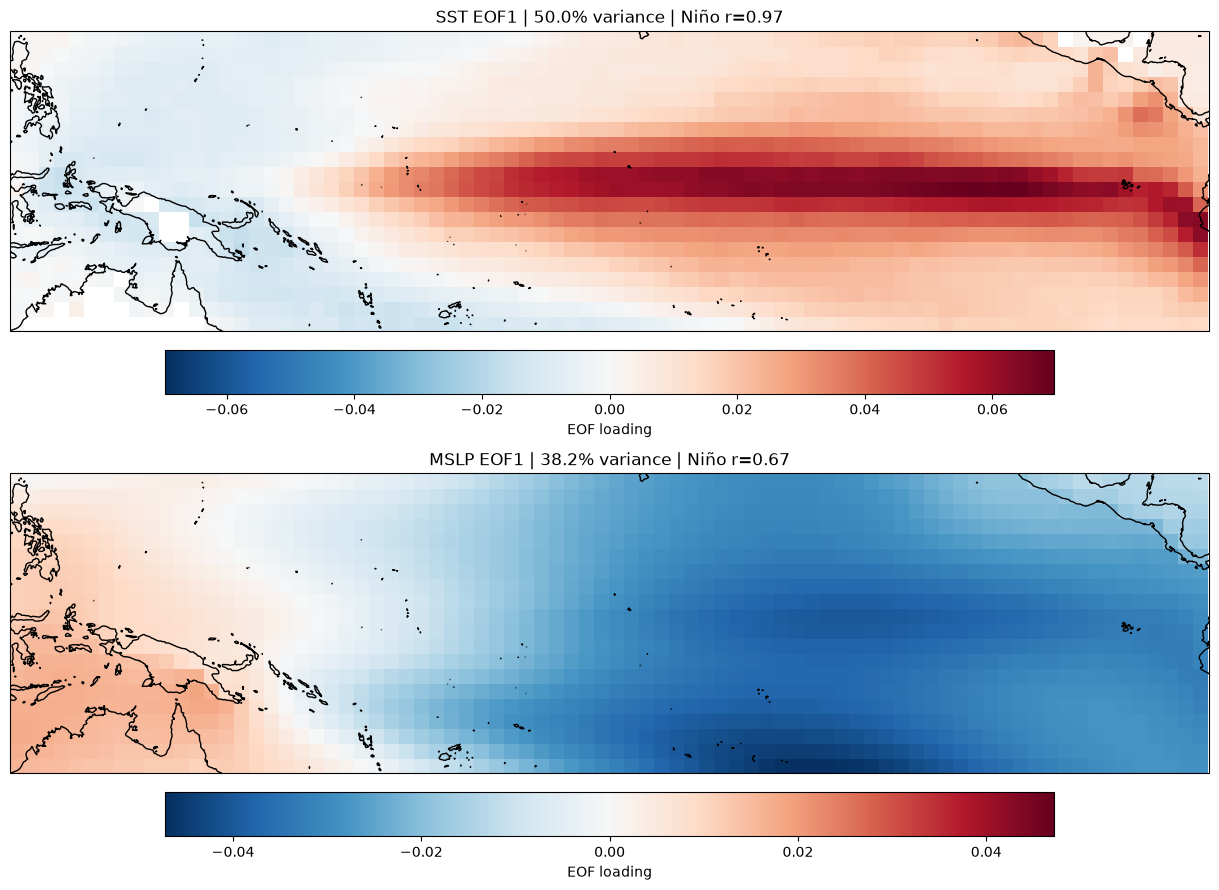

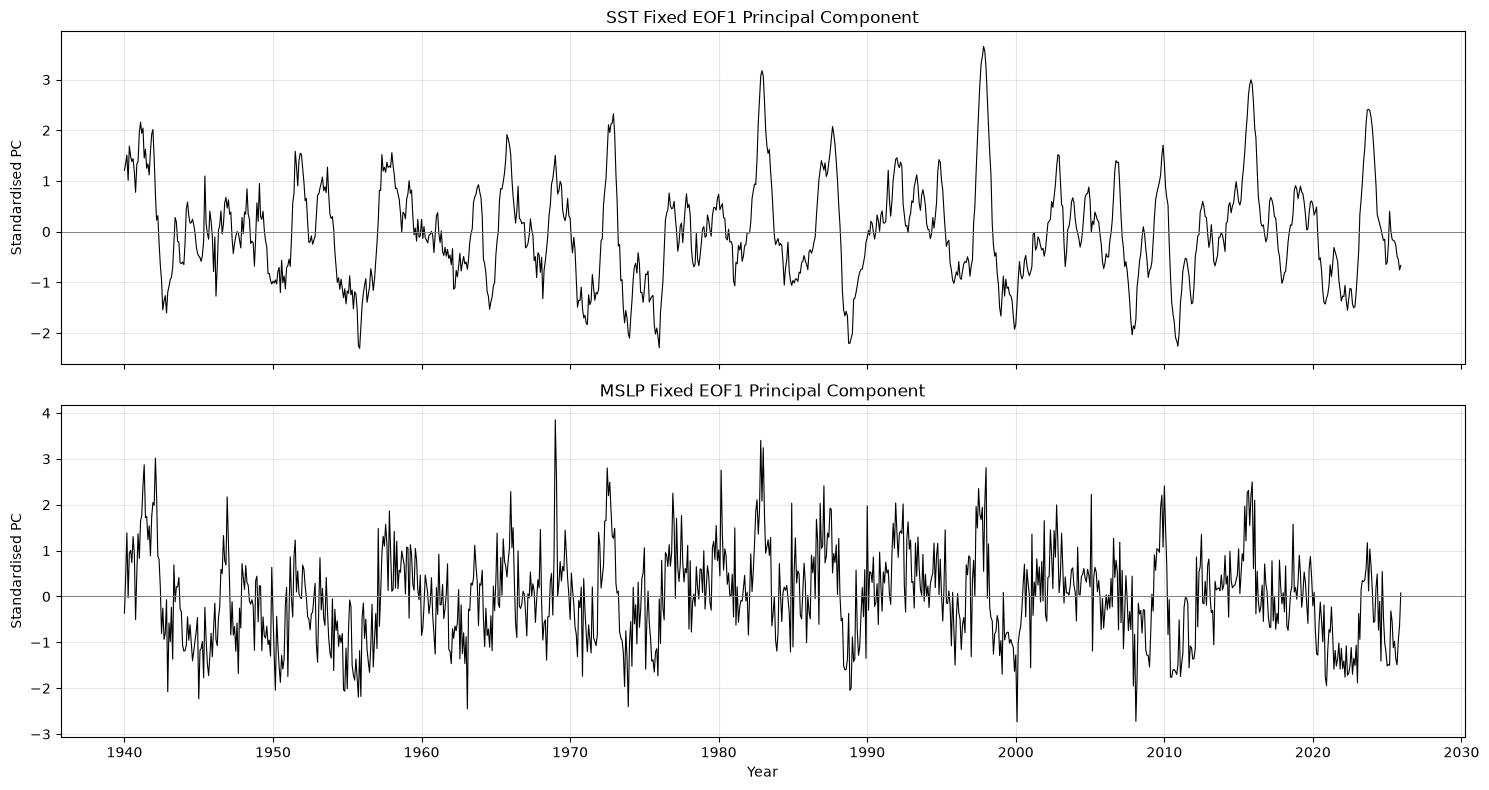

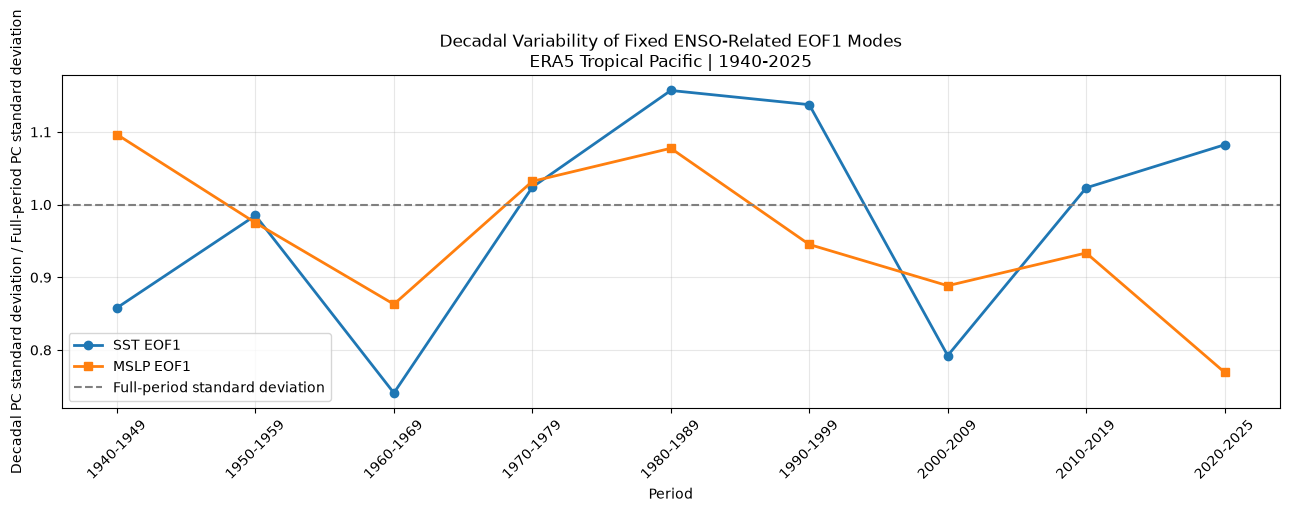


FIXED EOF PROJECTION SUMMARY
SST EOF1 explained variance: 49.99%
MSLP EOF1 explained variance: 38.17%
SST PC1 vs Niño 3.4: r=0.966
MSLP PC1 vs Niño 3.4: r=0.672

Results saved to:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\data\era5\fixed_eof

Figures saved to:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_fixed_eof


In [29]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from pathlib import Path
from sklearn.decomposition import PCA
from scipy.signal import detrend

# ============================================================
# ERA5 FIXED EOF PROJECTION
# Tropical Pacific SST and MSLP | 1940-2025
#
# EOF1 calculated over full period.
# All monthly anomalies projected onto fixed EOF1.
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

LAT_MIN, LAT_MAX = -20, 20
LON_MIN, LON_MAX = 120, 280

COARSEN_FACTOR = 8  # 0.25 -> approximately 2 degrees

DATA_DIR = Path("data/era5/era5_global")
OUTPUT_DIR = Path("data/era5/fixed_eof")
FIG_DIR = Path("figures/era5_fixed_eof")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "SST": DATA_DIR /
        "era5_sea_surface_temperature_1940_2025.nc",
    "MSLP": DATA_DIR /
        "era5_mean_sea_level_pressure_1940_2025.nc",
}

VARIABLE_NAMES = {
    "SST": "sst",
    "MSLP": "msl",
}

# ============================================================
# 1. LOAD TROPICAL PACIFIC DATA
# ============================================================

def load_field(path, variable):

    print(f"\nLoading {variable}...")

    with xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    ) as ds:

        if "valid_time" in ds.dims:
            ds = ds.rename({"valid_time": "time"})

        da = ds[variable]

        da = da.sel(
            time=slice(
                f"{START_YEAR}-01-01",
                f"{END_YEAR}-12-31"
            )
        )

        da = da.assign_coords(
            longitude=da.longitude % 360
        ).sortby("longitude").sortby("latitude")

        da = da.sel(
            latitude=slice(LAT_MIN, LAT_MAX),
            longitude=slice(LON_MIN, LON_MAX)
        )

        # Coarsen before loading
        da = da.coarsen(
            latitude=COARSEN_FACTOR,
            longitude=COARSEN_FACTOR,
            boundary="trim"
        ).mean()

        units = da.attrs.get("units", "")

        if variable == "sst":
            if units in ("K", "kelvin", "Kelvin"):
                da = da - 273.15
            elif units not in (
                "degC", "C", "celsius", "degrees_C"
            ):
                raise ValueError(
                    f"Unexpected SST units: {units}"
                )

        elif variable == "msl":
            if units == "Pa":
                da = da / 100.0
            elif units not in ("hPa", "mbar"):
                raise ValueError(
                    f"Unexpected MSLP units: {units}"
                )

        da = da.transpose(
            "time", "latitude", "longitude"
        ).compute()

    print("Shape:", da.shape)
    return da


sst = load_field(FILES["SST"], "sst")
mslp = load_field(FILES["MSLP"], "msl")

# ============================================================
# 2. PREPROCESS ANOMALIES
# ============================================================

def preprocess(da):

    # Full-period monthly climatology
    climatology = da.groupby(
        "time.month"
    ).mean("time")

    anomalies = (
        da.groupby("time.month") - climatology
    )

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    matrix = anomalies.values.reshape(nt, ny * nx)

    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid].astype(np.float64)

    # Remove linear trend over full period
    X = detrend(
        X, axis=0, type="linear"
    )

    lat = anomalies.latitude.values

    lat_weights = np.sqrt(
        np.clip(
            np.cos(np.deg2rad(lat)),
            0, None
        )
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None],
        (ny, nx)
    ).reshape(-1)

    weights = weights_2d[valid]

    X_weighted = X * weights

    return {
        "X_weighted": X_weighted,
        "valid": valid,
        "weights": weights,
        "shape": (ny, nx),
        "latitude": anomalies.latitude.values,
        "longitude": anomalies.longitude.values,
        "time": anomalies.time.values,
    }

# ============================================================
# 3. FIT EOF1 OVER FULL PERIOD
# ============================================================

def fit_fixed_eof(data):

    processed = preprocess(data)

    X = processed["X_weighted"]

    pca = PCA(
        n_components=1,
        svd_solver="full"
    )

    # Fit full-period EOF1
    pca.fit(X)

    eof_weighted = pca.components_[0]

    # Project all monthly anomaly fields
    pcs = (
        X - pca.mean_
    ) @ eof_weighted

    # Reconstruct physical EOF map
    eof_flat = np.full(
        np.prod(processed["shape"]),
        np.nan
    )

    eof_flat[processed["valid"]] = (
        eof_weighted / processed["weights"]
    )

    eof_map = eof_flat.reshape(
        processed["shape"]
    )

    return {
        "pc": pcs,
        "eof": eof_map,
        "explained": (
            pca.explained_variance_ratio_[0] * 100
        ),
        "latitude": processed["latitude"],
        "longitude": processed["longitude"],
        "time": processed["time"],
    }

# ============================================================
# 4. CALCULATE SST AND MSLP FIXED EOF1
# ============================================================

print("\nCalculating full-period SST EOF1...")
sst_result = fit_fixed_eof(sst)

print("Calculating full-period MSLP EOF1...")
mslp_result = fit_fixed_eof(mslp)

print(
    f"SST EOF1 explained variance: "
    f"{sst_result['explained']:.2f}%"
)

print(
    f"MSLP EOF1 explained variance: "
    f"{mslp_result['explained']:.2f}%"
)

# ============================================================
# 5. ORIENT EOF SIGNS USING NINO 3.4
# ============================================================

INDEX_FILE = Path(
    "derived_data/era5/indices/"
    "era5_nino34_1940_2025.nc"
)

with xr.open_dataset(INDEX_FILE) as index_ds:
    nino = index_ds[
        "nino34_detrended"
    ].load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(
        nino.time.values
    ).to_period("M")
)

def orient_to_nino(result):

    pc_months = pd.to_datetime(
        result["time"]
    ).to_period("M")

    pc_series = pd.Series(
        result["pc"],
        index=pc_months
    )

    common = pc_series.index.intersection(
        nino_series.index
    )

    r = np.corrcoef(
        pc_series.loc[common],
        nino_series.loc[common]
    )[0, 1]

    if r < 0:
        result["pc"] *= -1
        result["eof"] *= -1

    result["nino_correlation"] = abs(r)

    return result


sst_result = orient_to_nino(sst_result)
mslp_result = orient_to_nino(mslp_result)

# ============================================================
# 6. DECADAL STATISTICS
# ============================================================

def calculate_decadal_stats(result, variable):

    dates = pd.to_datetime(result["time"])
    pcs = result["pc"]

    df = pd.DataFrame({
        "time": dates,
        "pc": pcs
    })

    df["year"] = df["time"].dt.year

    # Fixed full-period standardisation
    full_std = df["pc"].std(ddof=1)

    df["pc_standardised"] = (
        df["pc"] / full_std
    )

    rows = []

    for start in range(START_YEAR, END_YEAR + 1, 10):

        end = min(start + 9, END_YEAR)

        subset = df[
            (df["year"] >= start) &
            (df["year"] <= end)
        ]

        rows.append({
            "Variable": variable,
            "Period": f"{start}-{end}",
            "Months": len(subset),
            "PC std": subset["pc"].std(ddof=1),
            "PC variance": subset["pc"].var(ddof=1),
            "Relative std": (
                subset["pc"].std(ddof=1) / full_std
            ),
        })

    return df, pd.DataFrame(rows)


sst_pc_df, sst_stats = calculate_decadal_stats(
    sst_result, "SST"
)

mslp_pc_df, mslp_stats = calculate_decadal_stats(
    mslp_result, "MSLP"
)

stats = pd.concat(
    [sst_stats, mslp_stats],
    ignore_index=True
)

print("\nDecadal statistics:")
print(stats.round(3).to_string(index=False))

stats.to_csv(
    OUTPUT_DIR / "decadal_pc_statistics.csv",
    index=False
)

# ============================================================
# 7. PLOT FIXED EOF MAPS
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    subplot_kw={
        "projection": ccrs.PlateCarree(
            central_longitude=180
        )
    }
)

for ax, result, title in [
    (axes[0], sst_result, "SST"),
    (axes[1], mslp_result, "MSLP")
]:

    pattern = result["eof"]

    vmax = np.nanmax(np.abs(pattern))

    im = ax.pcolormesh(
        result["longitude"],
        result["latitude"],
        pattern,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
        shading="auto"
    )

    ax.coastlines()

    ax.set_extent(
        [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
        crs=ccrs.PlateCarree()
    )

    ax.set_title(
        f"{title} EOF1 | "
        f"{result['explained']:.1f}% variance | "
        f"Niño r={result['nino_correlation']:.2f}"
    )

    fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        shrink=0.7,
        pad=0.05,
        label="EOF loading"
    )

plt.tight_layout()

plt.savefig(
    FIG_DIR / "fixed_eof1_maps.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. PLOT FULL-PERIOD PROJECTED PCs
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 8),
    sharex=True
)

for ax, df, title in [
    (axes[0], sst_pc_df, "SST"),
    (axes[1], mslp_pc_df, "MSLP")
]:

    ax.plot(
        df["time"],
        df["pc_standardised"],
        linewidth=0.8,
        color="black"
    )

    ax.axhline(0, color="grey", linewidth=0.7)

    ax.set_title(
        f"{title} Fixed EOF1 Principal Component"
    )

    ax.set_ylabel("Standardised PC")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Year")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "fixed_eof1_pc_timeseries.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 9. PLOT DECADAL VARIABILITY
# ============================================================

fig, ax = plt.subplots(figsize=(13, 5))

periods = sst_stats["Period"]

ax.plot(
    periods,
    sst_stats["Relative std"],
    marker="o",
    linewidth=2,
    label="SST EOF1"
)

ax.plot(
    periods,
    mslp_stats["Relative std"],
    marker="s",
    linewidth=2,
    label="MSLP EOF1"
)

ax.axhline(
    1,
    color="grey",
    linestyle="--",
    label="Full-period standard deviation"
)

ax.set_title(
    "Decadal Variability of Fixed ENSO-Related EOF1 Modes\n"
    "ERA5 Tropical Pacific | 1940-2025"
)

ax.set_ylabel(
    "Decadal PC standard deviation / "
    "Full-period PC standard deviation"
)

ax.set_xlabel("Period")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "decadal_fixed_eof_variability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. SAVE PC TIME SERIES
# ============================================================

sst_pc_df.to_csv(
    OUTPUT_DIR / "sst_fixed_eof1_pc.csv",
    index=False
)

mslp_pc_df.to_csv(
    OUTPUT_DIR / "mslp_fixed_eof1_pc.csv",
    index=False
)

# ============================================================
# 11. SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("FIXED EOF PROJECTION SUMMARY")
print("=" * 65)

print(
    f"SST EOF1 explained variance: "
    f"{sst_result['explained']:.2f}%"
)

print(
    f"MSLP EOF1 explained variance: "
    f"{mslp_result['explained']:.2f}%"
)

print(
    f"SST PC1 vs Niño 3.4: "
    f"r={sst_result['nino_correlation']:.3f}"
)

print(
    f"MSLP PC1 vs Niño 3.4: "
    f"r={mslp_result['nino_correlation']:.3f}"
)

print("\nResults saved to:")
print(OUTPUT_DIR.resolve())

print("\nFigures saved to:")
print(FIG_DIR.resolve())

print("=" * 65)
